In [12]:
# restrict 4000 MiB, NO OOM!!! 
options(future.globals.maxSize = 4000 * 1024^2)

In [ ]:
options(warn=-1)


# Task1

In [1]:
# ================= 1. Environment Setup =================
packages <- c("Seurat", "ggplot2", "dplyr", "patchwork", "hdf5r", "ggrepel") # Added ggrepel for volcano labels
for (pkg in packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) install.packages(pkg)
}

library(Seurat)
library(ggplot2)
library(dplyr)
library(patchwork)
library(ggrepel)

# ================= 2. Data Loading & Preprocessing =================

# Set file paths (Remember!!!!!!)
path_ctr <- "F:\\H.M.打火机\\Huang_Minza__Ctr_1_A1\\square_016um"
path_sms <- "F:\\H.M.打火机\\Huang_Minza__SMS_1_D1\\square_016um"

# Load CTR sample
print("Loading CTR sample...")
ctr_obj <- Load10X_Spatial(data.dir = path_ctr, filename = "filtered_feature_bc_matrix.h5")
ctr_obj$orig.ident <- "CTR"
ctr_obj$condition <- "CTR"

# Load SMS sample
print("Loading SMS sample...")
sms_obj <- Load10X_Spatial(data.dir = path_sms, filename = "filtered_feature_bc_matrix.h5")
sms_obj$orig.ident <- "SMS"
sms_obj$condition <- "SMS"

Warning message:
"package 'Seurat' was built under R version 4.4.3"
Loading required package: SeuratObject

Warning message:
"package 'SeuratObject' was built under R version 4.4.3"
Loading required package: sp

Warning message:
"package 'sp' was built under R version 4.4.3"

Attaching package: 'SeuratObject'


The following objects are masked from 'package:base':

    intersect, t


Warning message:
"package 'ggplot2' was built under R version 4.4.3"

Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union


Warning message:
"package 'patchwork' was built under R version 4.4.3"


[1] "Loading CTR sample..."
[1] "Loading SMS sample..."


[1] "--- Diagnosing Coordinates Visual Check ---"


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information."
Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead."


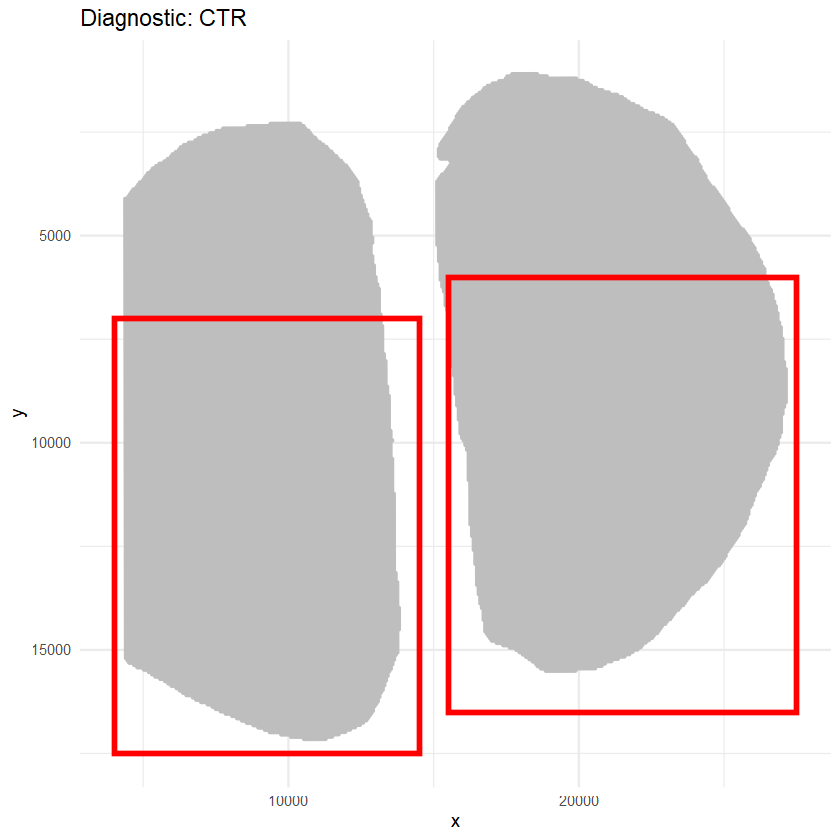

[1] "Applying spatial cropping with NEW coordinates..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "CTR Cells: Before = 80246 -> After = 55712"


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "SMS Cells: Before = 84918 -> After = 52266"
[1] "Merging datasets..."


Warning message:
"Key 'slice1_' taken, using 'slice12_' instead"
Normalizing layer: counts.1

Normalizing layer: counts.2



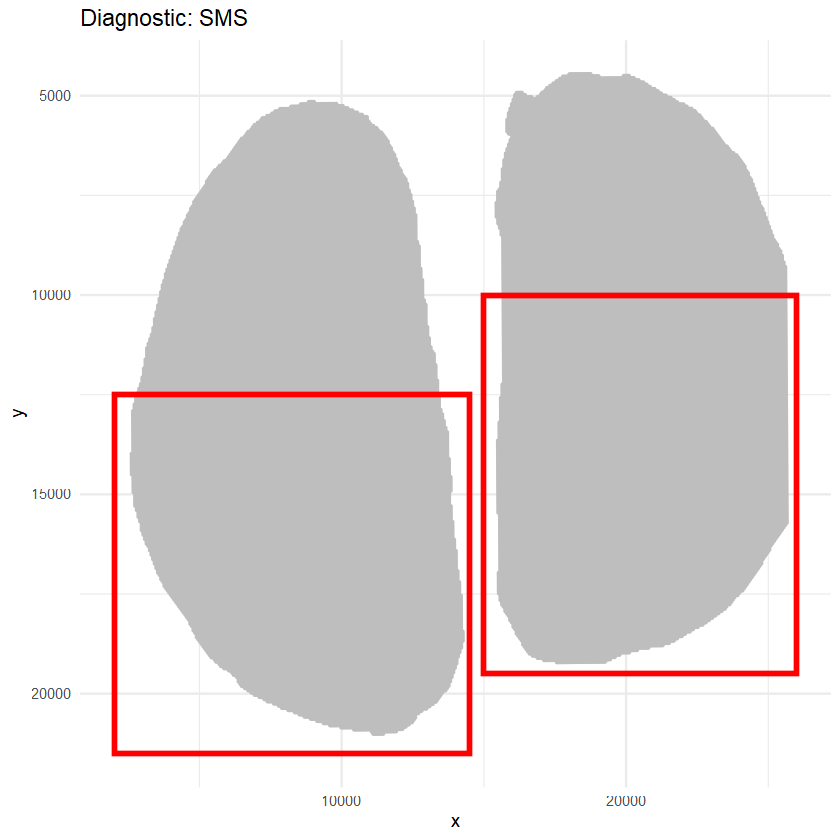

In [2]:
# ================= 2.1 Coordinate  =================
print("--- Diagnosing Coordinates Visual Check ---")

# --- Function to plot diagnostic boxes ---
plot_diagnosis <- function(obj, box_df, title_suffix) {
  coords <- GetTissueCoordinates(obj)
  
  # Detect column names (imagecol/imagerow or x/y)
  x_col <- grep("col|x", colnames(coords), value = TRUE)[1]
  y_col <- grep("row|y", colnames(coords), value = TRUE)[1]
  
  p <- ggplot(coords, aes_string(x = x_col, y = y_col)) +
    geom_point(size = 0.25, color = "grey") + 
    geom_rect(data = box_df, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax), 
              inherit.aes = FALSE, fill = NA, color = "red", size = 1.2, linetype = "solid") +
    scale_y_reverse() + # Visium start from left Upper usually?
    ggtitle(paste("Diagnostic:", title_suffix)) +
    theme_minimal()
  return(p)
}

# --- Define Your New Boxes (User Provided) ---
# CTR Boxes
ctr_boxes <- data.frame(
  xmin = c(4000, 15500),
  xmax = c(14500, 27500),
  ymin = c(7000, 6000),
  ymax = c(17500, 16500),
  label = c("Box 1", "Box 2")
)

# SMS Boxes
sms_boxes <- data.frame(
  xmin = c(15000, 2000),
  xmax = c(26000, 14500),
  ymin = c(10000, 12500),
  ymax = c(19500, 21500),
  label = c("Box 1", "Box 2")
)

# --- Generate & Save Diagnostic Plots ---
p_diag_ctr <- plot_diagnosis(ctr_obj, ctr_boxes, "CTR")
print(p_diag_ctr)
ggsave("Debug_CTR_Coords_New.png", plot = p_diag_ctr, width = 6, height = 6)

p_diag_sms <- plot_diagnosis(sms_obj, sms_boxes, "SMS")
print(p_diag_sms)
ggsave("Debug_SMS_Coords_New.png", plot = p_diag_sms, width = 6, height = 6)


# ================= 2.2 Apply Spatial Cropping (The Math Part) =================
print("Applying spatial cropping with NEW coordinates...")

subset_by_coords <- function(obj, boxes) {
  coords <- GetTissueCoordinates(obj)
  x_col <- grep("col|x", colnames(coords), value = TRUE)[1]
  y_col <- grep("row|y", colnames(coords), value = TRUE)[1]
  
  cells_to_keep <- c()
  
  # Loop through each box defined in the dataframe
  for (i in 1:nrow(boxes)) {
    x_min <- boxes$xmin[i]
    x_max <- boxes$xmax[i]
    y_min <- boxes$ymin[i]
    y_max <- boxes$ymax[i]
    
    # Mathematical Intersection: Find points inside the rectangle
    # Logic: x >= xmin AND x <= xmax AND y >= ymin AND y <= ymax
    ids <- rownames(coords[coords[[x_col]] >= x_min & coords[[x_col]] <= x_max &
                           coords[[y_col]] >= y_min & coords[[y_col]] <= y_max, ])
    cells_to_keep <- c(cells_to_keep, ids)
  }
  
  if (length(cells_to_keep) == 0) {
    stop("error (Pixels vs Microns)")
  }
  
  return(subset(obj, cells = unique(cells_to_keep)))
}

# --- Execute Cropping ---
# Crop CTR
ctr_obj_subset <- subset_by_coords(ctr_obj, ctr_boxes)
print(paste("CTR Cells: Before =", ncol(ctr_obj), "-> After =", ncol(ctr_obj_subset)))
ctr_obj <- ctr_obj_subset # Overwrite

# Crop SMS
sms_obj_subset <- subset_by_coords(sms_obj, sms_boxes)
print(paste("SMS Cells: Before =", ncol(sms_obj), "-> After =", ncol(sms_obj_subset)))
sms_obj <- sms_obj_subset # Overwrite

# ================= 2.3 Merging & Normalization (Standard Flow) =================


print("Merging datasets...")
combined_data <- merge(ctr_obj, y = sms_obj, add.cell.ids = c("CTR", "SMS"))

# Normalize
combined_data <- NormalizeData(combined_data)
combined_data <- JoinLayers(combined_data)
Idents(combined_data) <- "condition"

[1] "Verifying removal of Striatum markers..."
[1] "Verifying Rai1..."


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



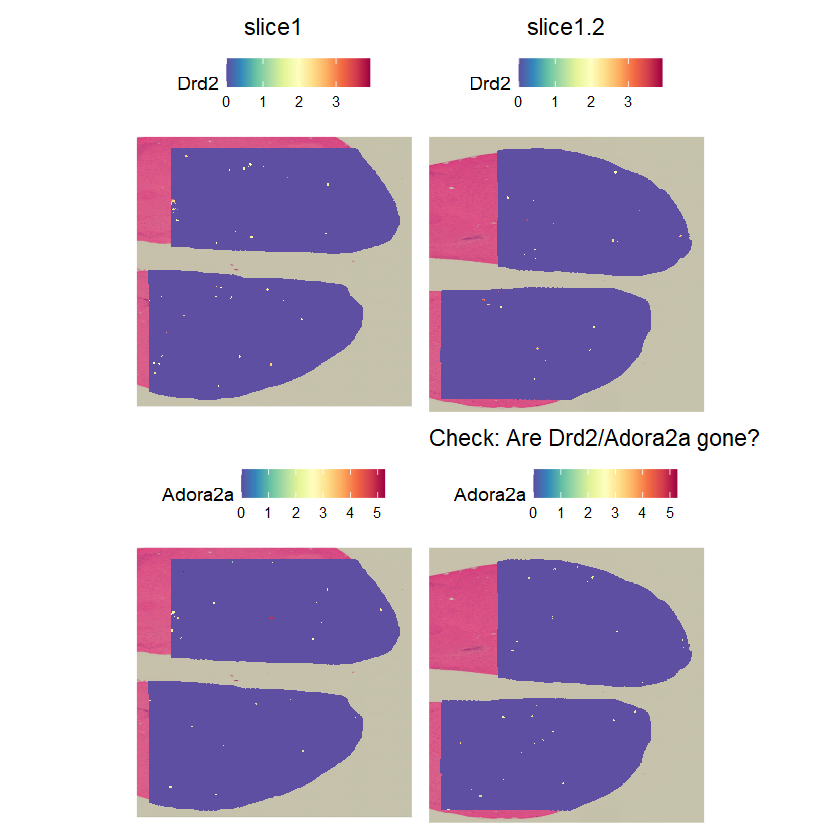

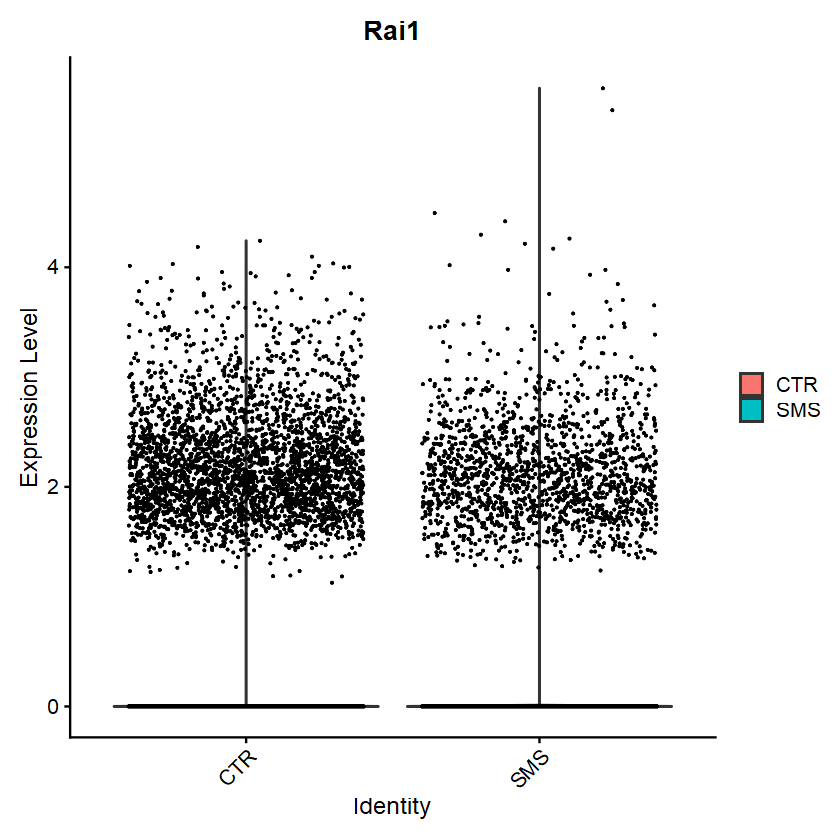

In [3]:
# ================= 3. Quick Check (from given coordinate) =================

print("Verifying removal of Striatum markers...")
p_check <- SpatialFeaturePlot(combined_data, features = c("Drd2", "Adora2a"), ncol = 2, pt.size.factor = 4) +
           ggtitle("Check: Are Drd2/Adora2a gone?")
print(p_check)
ggsave("Task1_Striatum_Check.png", plot = p_check, width = 10, height = 5)


print("Verifying Rai1...")
p_rai1 <- VlnPlot(combined_data, features = "Rai1", group.by = "condition")
print(p_rai1)
ggsave("Task1_Rai1_Validation_NewCoords.png", width = 6, height = 6)


[1] "Visualizing cropped regions to verify coordinates..."
[1] "Verifying Rai1 downregulation..."


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



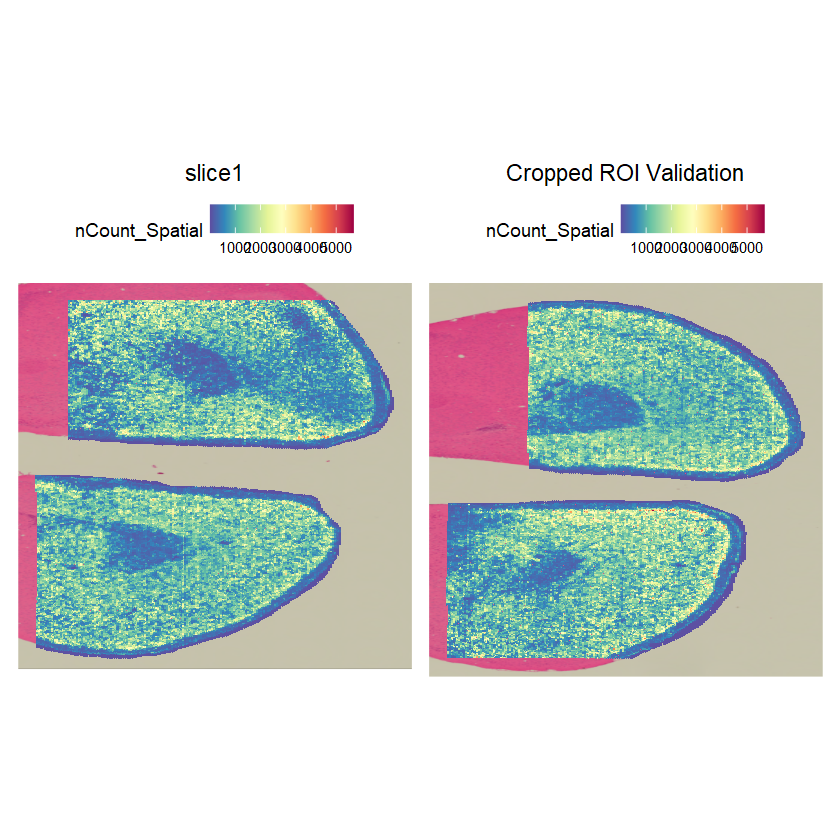

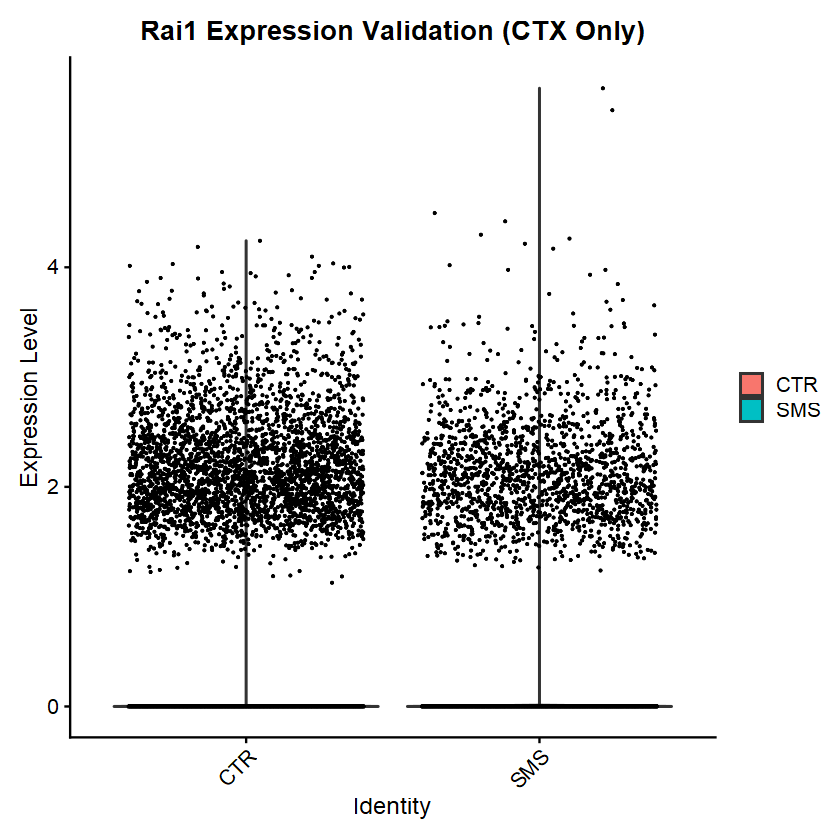

In [4]:
# ================= 3. Validation Visualization (Quality Check) =================

# 1. 
print("Visualizing cropped regions to verify coordinates...")
p_spatial_check <- SpatialFeaturePlot(combined_data, features = "nCount_Spatial", ncol = 2) + 
                   ggtitle("Cropped ROI Validation")
print(p_spatial_check)
ggsave("Task1_ROI_Check.png", plot = p_spatial_check, width = 10, height = 5)

# 2. Rai1(Boxplot as requested)
print("Verifying Rai1 downregulation...")
p_rai1 <- VlnPlot(combined_data, features = "Rai1", pt.size = 0.1, group.by = "condition") + 
          ggtitle("Rai1 Expression Validation (CTX Only)") +
          theme(plot.title = element_text(hjust = 0.5))
print(p_rai1)
ggsave("Task1_Rai1_Validation.png", plot = p_rai1, width = 6, height = 6)

In [5]:
# ================= 4. Whole-Tissue Differential Expression =================
print("Calculating differential expression for CTX regions...")

de_markers <- FindMarkers(combined_data, 
                          ident.1 = "SMS", 
                          ident.2 = "CTR", 
                          group.by = "condition",
                          logfc.threshold = 0.1) # Slightly lowered threshold to capture more genes

# Remove confounding genes (Blacklist)    Drd2 Adora2a 
blacklist <- c("Drd2", "Adora2a")
de_markers <- de_markers[!rownames(de_markers) %in% blacklist, ]

# Sort
de_markers <- de_markers[order(de_markers$avg_log2FC, decreasing = TRUE), ]

# Save Results
write.csv(de_markers, "Task1_WholeTissue_DE_Genes_CTX_Only.csv")
print("New DE list saved (excluding Drd2/Adora2a).")

[1] "Calculating differential expression for CTX regions..."


For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session



[1] "New DE list saved (excluding Drd2/Adora2a)."


[1] "Generating Volcano Plots..."
[1] "Plotting Version A: Standard Cleaned..."


Warning message:
"Removed 3750 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 3750 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


[1] "Plotting Version B: IEG Highlight..."
[1] "Found 10 IEGs in data out of 10"


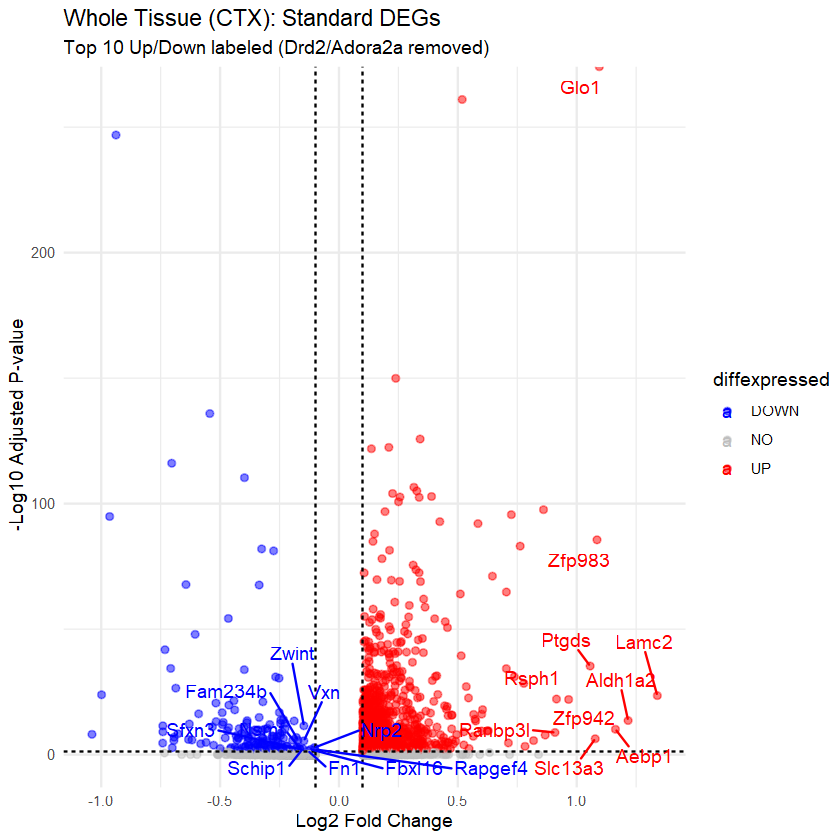

[1] "Step 5 Complete: Two volcano plots generated."


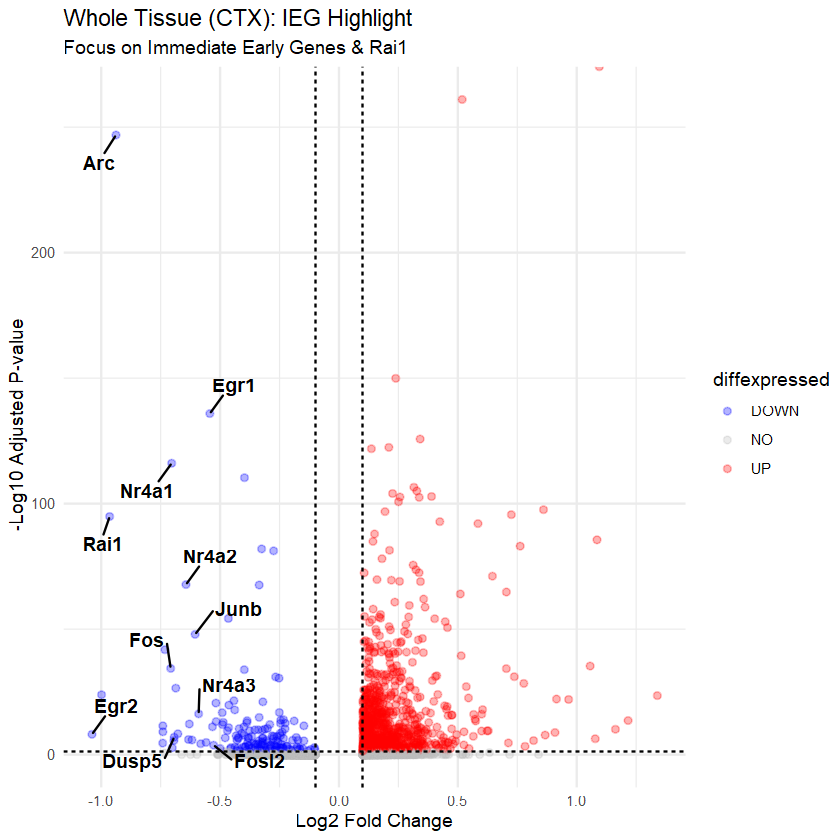

In [6]:
# ================= 5. Visualization: Volcano Plot (Two Versions) =================

print("Generating Volcano Plots...")

# --- Data Preparation ---
# Ensure we work with the latest DE results
# Add a column for color categorization
de_markers$diffexpressed <- "NO"
de_markers$diffexpressed[de_markers$avg_log2FC > 0.1 & de_markers$p_val_adj < 0.05] <- "UP"
de_markers$diffexpressed[de_markers$avg_log2FC < -0.1 & de_markers$p_val_adj < 0.05] <- "DOWN"
de_markers$gene <- rownames(de_markers)

# Define the "Blacklist" (Genes to strictly hide/ignore)
blacklist <- c("Drd2", "Adora2a")

# ================= Version A: Standard Cleaned Plot =================
# Goal: Show Top 10 Up and Top 10 Down, BUT exclude Drd2/Adora2a
print("Plotting Version A: Standard Cleaned...")

# 1. Identify Top 10 UP genes (excluding blacklist)
top_up_genes <- head(de_markers$gene[de_markers$diffexpressed == "UP" & 
                                     !de_markers$gene %in% blacklist], 10)

# 2. Identify Top 10 DOWN genes (excluding blacklist)
top_down_genes <- head(de_markers$gene[de_markers$diffexpressed == "DOWN" & 
                                       !de_markers$gene %in% blacklist], 10)

# 3. Create Label Column for Version A
de_markers$label_ver_A <- NA
genes_to_label_A <- c(top_up_genes, top_down_genes)
de_markers$label_ver_A[de_markers$gene %in% genes_to_label_A] <- de_markers$gene[de_markers$gene %in% genes_to_label_A]

# 4. Plot Version A
p_volcano_A <- ggplot(data = de_markers, aes(x = avg_log2FC, y = -log10(p_val_adj), col = diffexpressed, label = label_ver_A)) +
  geom_point(alpha = 0.5) + 
  theme_minimal() +
  scale_color_manual(values = c("blue", "grey", "red")) +
  geom_vline(xintercept = c(-0.1, 0.1), col = "black", linetype = "dashed") +
  geom_hline(yintercept = -log10(0.05), col = "black", linetype = "dashed") +
  # Use ggrepel for clean labels
  geom_text_repel(max.overlaps = 30, box.padding = 0.5, force = 2) +
  labs(title = "Whole Tissue (CTX): Standard DEGs", 
       subtitle = "Top 10 Up/Down labeled (Drd2/Adora2a removed)",
       x = "Log2 Fold Change", 
       y = "-Log10 Adjusted P-value")

print(p_volcano_A)
ggsave("Task1_VolcanoPlot_Standard.png", plot = p_volcano_A, width = 8, height = 6)


# ================= Version B: IEG Highlight Plot =================
# Goal: Highlight specific Immediate Early Genes (IEGs) in downregulated section
print("Plotting Version B: IEG Highlight...")

# 1. Define IEG list from instructions
ieg_list <- c("Fos", "Junb", "Fosl2", "Egr1", "Egr2", 
              "Nr4a1", "Nr4a2", "Nr4a3", "Arc", "Dusp5")

# 2. Check which IEGs are actually in our data (to avoid errors)
valid_iegs <- intersect(ieg_list, rownames(de_markers))
print(paste("Found", length(valid_iegs), "IEGs in data out of", length(ieg_list)))

# 3. Create Label Column for Version B
# Label ONLY the IEGs (and maybe Rai1 for consistency)
de_markers$label_ver_B <- NA
genes_to_label_B <- c(valid_iegs, "Rai1")
de_markers$label_ver_B[de_markers$gene %in% genes_to_label_B] <- de_markers$gene[de_markers$gene %in% genes_to_label_B]

# 4. Plot Version B
p_volcano_B <- ggplot(data = de_markers, aes(x = avg_log2FC, y = -log10(p_val_adj), col = diffexpressed, label = label_ver_B)) +
  geom_point(alpha = 0.3) + # Make background points more transparent
  theme_minimal() +
  scale_color_manual(values = c("blue", "grey", "red")) +
  geom_vline(xintercept = c(-0.1, 0.1), col = "black", linetype = "dashed") +
  geom_hline(yintercept = -log10(0.05), col = "black", linetype = "dashed") +
  # Highlight the IEG points specifically (optional: make them bigger/different color?)
  # Here we just label them clearly
  geom_text_repel(data = subset(de_markers, !is.na(label_ver_B)), 
                  max.overlaps = Inf, box.padding = 0.8, 
                  fontface = "bold", color = "black") +
  labs(title = "Whole Tissue (CTX): IEG Highlight", 
       subtitle = "Focus on Immediate Early Genes & Rai1",
       x = "Log2 Fold Change", 
       y = "-Log10 Adjusted P-value")

print(p_volcano_B)
ggsave("Task1_VolcanoPlot_IEG_Highlight.png", plot = p_volcano_B, width = 8, height = 6)

print("Step 5 Complete: Two volcano plots generated.")

[1] "Generating DotPlot..."


Warning message:
"Scaling data with a low number of groups may produce misleading results"
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


[1] "Generating Heatmap..."


Centering and scaling data matrix

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


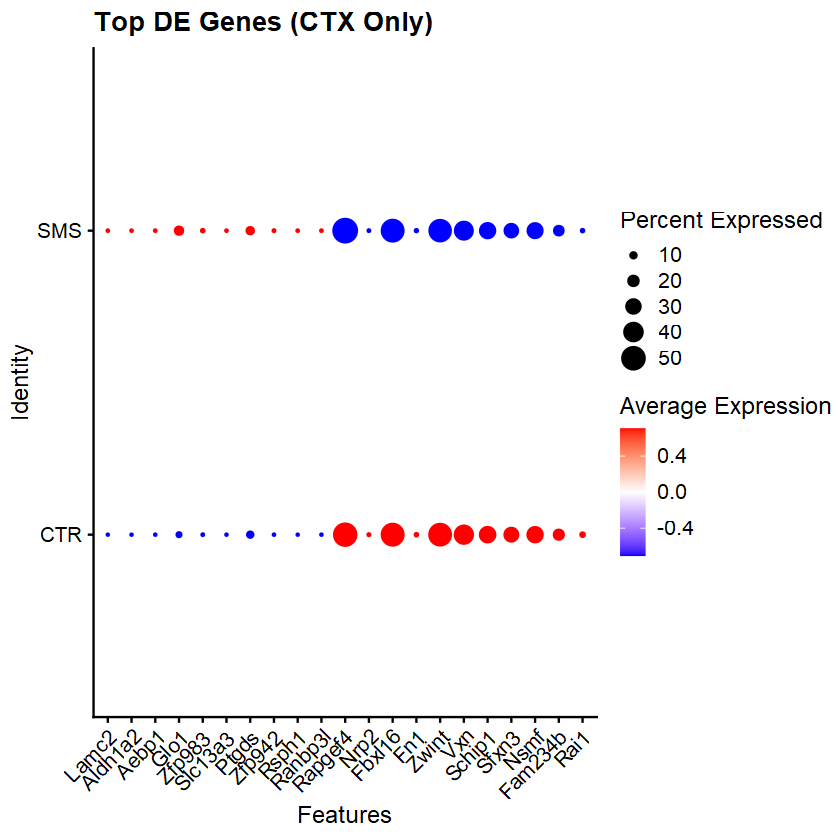

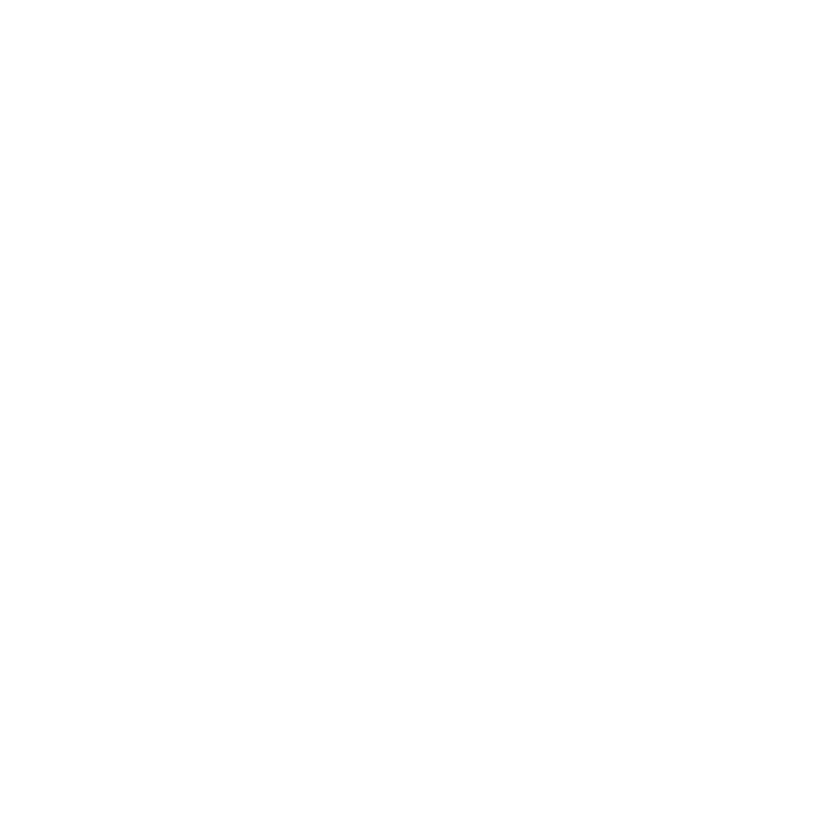

In [7]:
# ================= 6. Visualization: DotPlot & Heatmap =================

# Update top genes list (Making sure Drd2 is gone)
top_10_up <- head(de_markers[de_markers$diffexpressed == "UP", "gene"], 10)
top_10_down <- head(de_markers[de_markers$diffexpressed == "DOWN", "gene"], 10)
top_genes_list <- unique(c(top_10_up, top_10_down, "Rai1"))

# Double check filtering
top_genes_list <- setdiff(top_genes_list, blacklist)

# Dot Plot
print("Generating DotPlot...")
p_dot <- DotPlot(combined_data, features = top_genes_list, group.by = "condition") + 
  RotatedAxis() + 
  ggtitle("Top DE Genes (CTX Only)") + 
  scale_color_gradient2(low = "blue", mid = "white", high = "red")
print(p_dot)
ggsave("Task1_DotPlot.png", plot = p_dot, width = 10, height = 6)

# Heatmap
print("Generating Heatmap...")
combined_data <- ScaleData(combined_data, features = top_genes_list)
p_heat <- DoHeatmap(combined_data, features = top_genes_list, group.by = "condition", size = 4) + 
  scale_fill_gradientn(colors = c("blue", "white", "red"))
print(p_heat)
ggsave("Task1_Heatmap.png", plot = p_heat, width = 12, height = 8)

[1] "Running GO Analysis..."


Warning message:
"package 'clusterProfiler' was built under R version 4.4.2"


clusterProfiler v4.14.6 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, Yanyan Han and Qing-Yu He.
clusterProfiler: an R package for comparing biological themes among
gene clusters. OMICS: A Journal of Integrative Biology. 2012,
16(5):284-287


Attaching package: 'clusterProfiler'


The following object is masked from 'package:stats':

    filter


Loading required package: AnnotationDbi

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: 'BiocGenerics'


The following objects are masked from 'package:dplyr':

    combine, intersect, setdiff, union


The following object is masked from 'package:SeuratObject':

    intersect


The following objects are masked from 'package:stats':

    IQR, mad, sd, var, xtabs


The following objects are masked from 'package:base':

    anyDuplicated, aperm, append, as.da

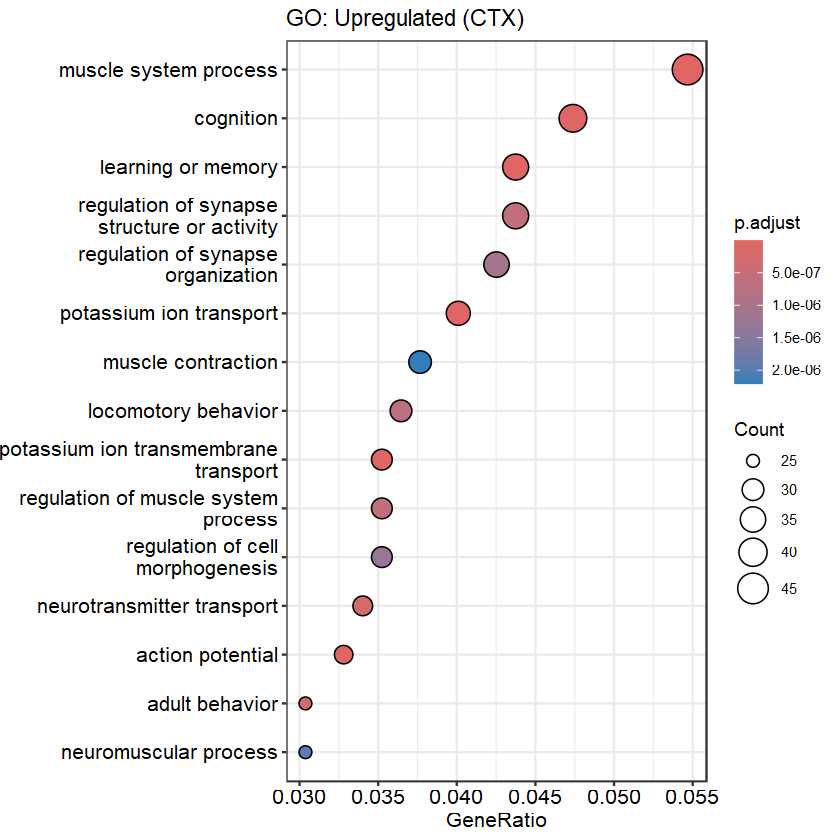

Saving 6.67 x 6.67 in image


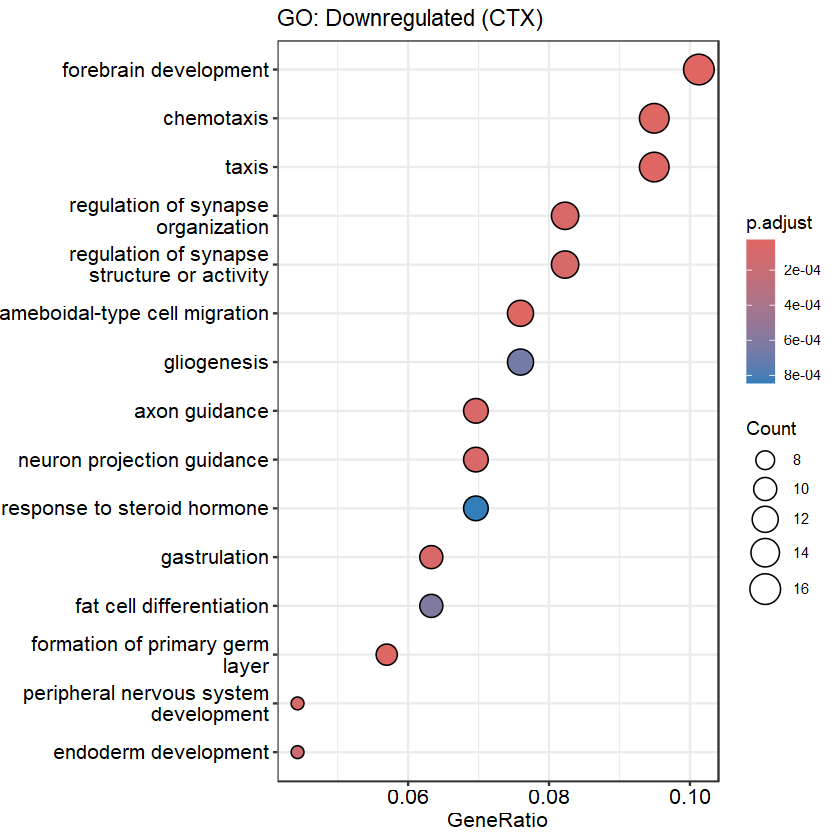

In [8]:
# ================= 7. GO Enrichment (Updated) =================
# CTX GO

print("Running GO Analysis...")
library(clusterProfiler)
library(org.Mm.eg.db)

genes_up <- rownames(de_markers[de_markers$diffexpressed == "UP", ])
genes_down <- rownames(de_markers[de_markers$diffexpressed == "DOWN", ])

# Up
if(length(genes_up) > 0){
  ego_up <- enrichGO(gene = genes_up, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP",
                     pAdjustMethod = "BH", pvalueCutoff = 0.05)
  if(!is.null(ego_up)){
      p_go_up <- dotplot(ego_up, showCategory=15) + ggtitle("GO: Upregulated (CTX)")
      print(p_go_up)
      ggsave("Task1_GO_Enrichment_UP.png", p_go_up)
  }
}

# Down
if(length(genes_down) > 0){
  ego_down <- enrichGO(gene = genes_down, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP",
                       pAdjustMethod = "BH", pvalueCutoff = 0.05)
  if(!is.null(ego_down)){
      p_go_down <- dotplot(ego_down, showCategory=15) + ggtitle("GO: Downregulated (CTX)")
      print(p_go_down)
      ggsave("Task1_GO_Enrichment_DOWN.png", p_go_down)
  }
}



[1] "Running GO Analysis..."


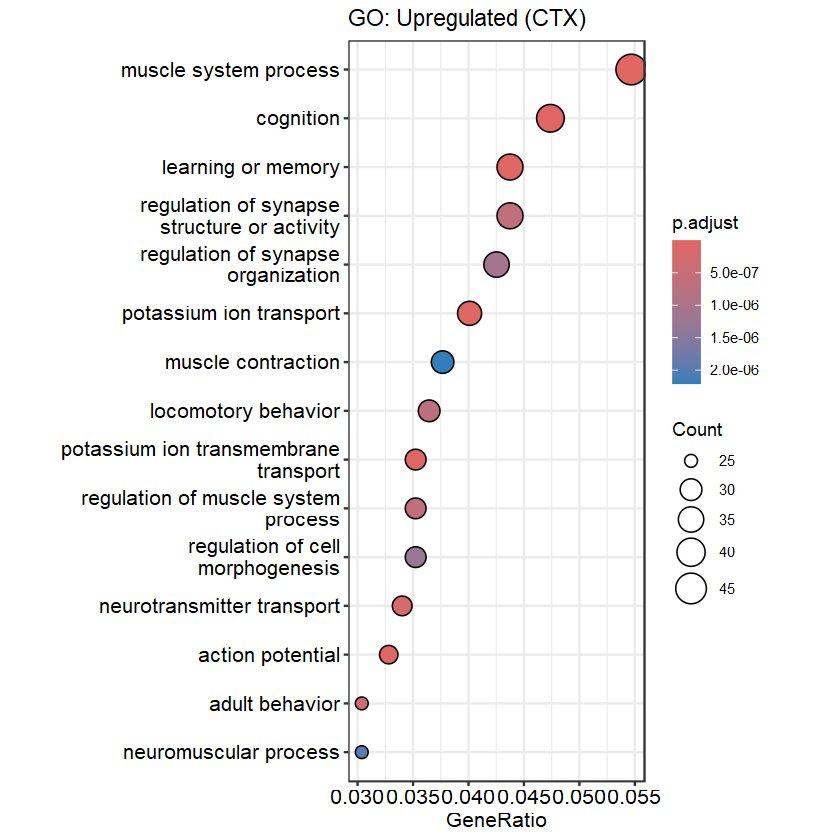

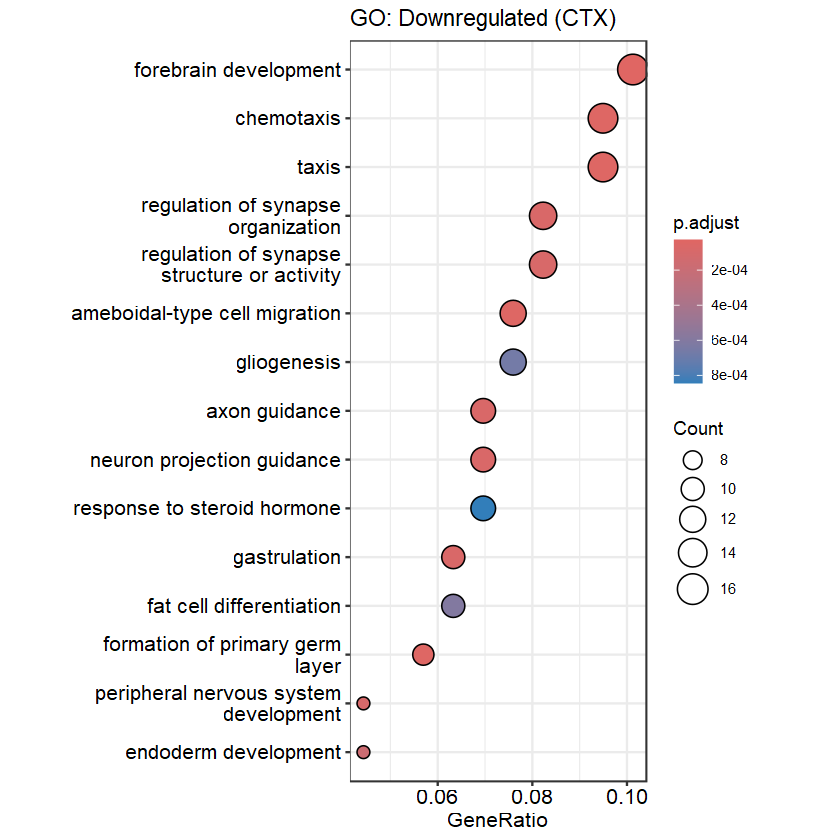

In [10]:
print("Running GO Analysis...")
library(clusterProfiler)
library(org.Mm.eg.db)
library(ggplot2)

genes_up <- rownames(de_markers[de_markers$diffexpressed == "UP", ])
genes_down <- rownames(de_markers[de_markers$diffexpressed == "DOWN", ])

# Up
if(length(genes_up) > 0){
  ego_up <- enrichGO(gene = genes_up, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP",
                     pAdjustMethod = "BH", pvalueCutoff = 0.05)
  if(!is.null(ego_up)){
      p_go_up <- dotplot(ego_up, showCategory=15) + 
                 ggtitle("GO: Upregulated (CTX)") +
                 # Adjust Here
                 theme(aspect.ratio = 2.5) 
      
      print(p_go_up)
      
      # 
      ggsave("Task1_GO_Enrichment_UP.png", p_go_up, width = 5, height = 7, dpi = 300)
  }
}

# Down
if(length(genes_down) > 0){
  ego_down <- enrichGO(gene = genes_down, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP",
                       pAdjustMethod = "BH", pvalueCutoff = 0.05)
  if(!is.null(ego_down)){
      p_go_down <- dotplot(ego_down, showCategory=15) + 
                   ggtitle("GO: Downregulated (CTX)") +
                   # Adjust Here
                   theme(aspect.ratio = 2.5)
                   
      print(p_go_down)
      
      # 
      ggsave("Task1_GO_Enrichment_DOWN.png", p_go_down, width = 5, height = 7, dpi = 300)
  }
}

# Task 1.5

In [ ]:
# 2026/02/14
# There were 2 samples for CTR and SMS. Could I please have both sets of numbers so I can also plot the deviation?

In [11]:
# ==============================================================================
# TASK 2: Cell-Class-Specific Analysis (CTX Only)
# ==============================================================================
# PREREQUISITE: Ensure 'combined_data' is the CROPPED object from Task 1.
# If you haven't run Task 1 (cropping), go back and run it first.

library(Seurat)
library(ggplot2)
library(dplyr)
library(patchwork)
library(clusterProfiler)
library(org.Mm.eg.db)
library(enrichplot)

# ================= 1. Load & Process Reference Atlas =================
print("--- Step 1: Preparing Reference Atlas ---")

# Define paths (Ensure these point to the correct files)
ref_path_matrix <- "F:\\H.M.打火机\\Task2\\DataFromPaper\\GSE124952_expression_matrix.csv.gz"
ref_path_meta <- "F:\\H.M.打火机\\Task2\\DataFromPaper\\GSE124952_meta_data.csv.gz"

# Load data
if (file.exists(ref_path_matrix) && file.exists(ref_path_meta)) {
  ref_counts <- read.csv(ref_path_matrix, row.names = 1, check.names = FALSE)
  ref_meta <- read.csv(ref_path_meta, row.names = 1)
  
  ref_obj <- CreateSeuratObject(counts = ref_counts, meta.data = ref_meta)
  
  # Set identity
  if ("CellType" %in% colnames(ref_obj@meta.data)) {
    Idents(ref_obj) <- ref_obj$CellType
  } else {
    stop("Error: 'CellType' column missing in reference metadata.")
  }
  
  # Normalize & PCA (Standard Seurat Workflow)
  ref_obj <- NormalizeData(ref_obj)
  ref_obj <- FindVariableFeatures(ref_obj, selection.method = "vst", nfeatures = 2000)
  ref_obj <- ScaleData(ref_obj)
  ref_obj <- RunPCA(ref_obj, verbose = FALSE)
  
  print("Reference Atlas prepared successfully.")
} else {
  stop("Error: Reference files not found. Check paths.")
}

Warning message:
"package 'enrichplot' was built under R version 4.4.2"
enrichplot v1.26.6 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, Yanyan Han and Qing-Yu He.
clusterProfiler: an R package for comparing biological themes among
gene clusters. OMICS: A Journal of Integrative Biology. 2012,
16(5):284-287



[1] "--- Step 1: Preparing Reference Atlas ---"


Warning message:
"Data is of class data.frame. Coercing to dgCMatrix."
Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix



[1] "Reference Atlas prepared successfully."


[1] "--- Step 1: Loading Raw Data ---"
[1] "--- Step 2: Cropping with Replicate Labels ---"


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "--- Step 3: Merging & Normalizing ---"


Warning message:
"Key 'slice1_' taken, using 'slice12_' instead"
Normalizing layer: counts.1

Normalizing layer: counts.2



[1] "--- Step 4: Re-running Annotation (Label Transfer) ---"


...

[1] "Transferring labels..."


Warning message:
"Layer counts isn't present in the assay object; returning NULL"


[1] "Annotation Complete. Cell types available:"
[1] "Inhibitory" "Excitatory" "Oligo"      "Astro"      "Endo"      
[6] "Microglia"  "OPC"        "NF Oligo"  
[1] "--- Step 5: Generating 4-Bar Replicate Plot ---"


Warning message in geom_bar(stat = "identity", position = position_dodge(width = 0.8), :
"Ignoring unknown parameters: `size`"


[1] "Success! Object rebuilt and graph generated."


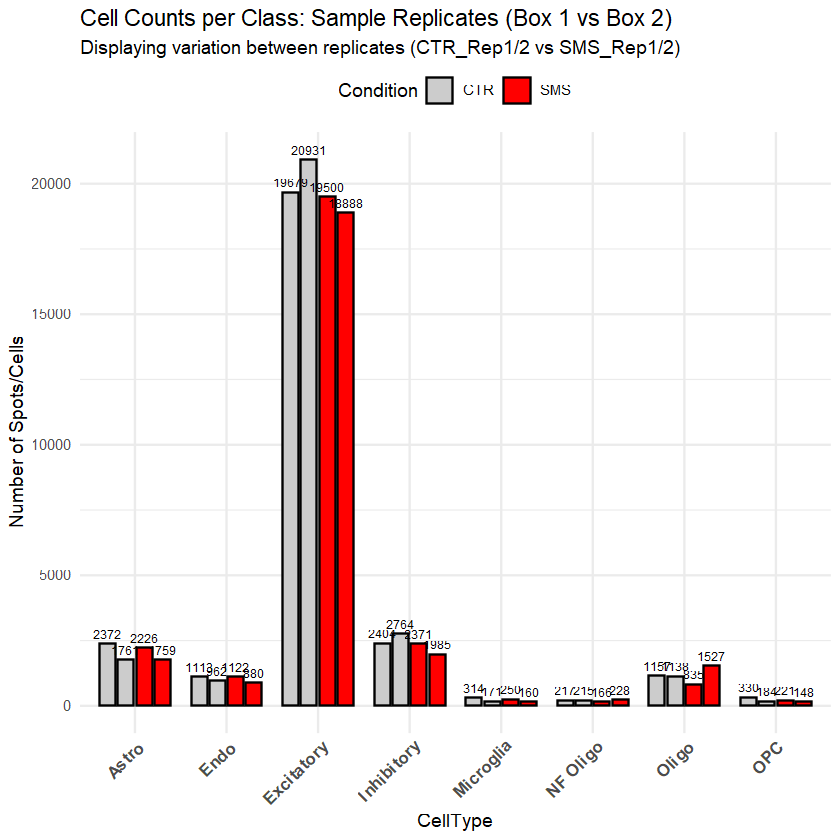

In [13]:
# ================= Task 1.5: Rebuild Object with Replicates & Annotation =================
library(Seurat)
library(ggplot2)
library(dplyr)
library(patchwork)

# 1. Set paths & load data
print("--- Step 1: Loading Raw Data ---")
path_ctr <- "F:\\H.M.打火机\\Huang_Minza__Ctr_1_A1\\square_016um"
path_sms <- "F:\\H.M.打火机\\Huang_Minza__SMS_1_D1\\square_016um"

ctr_obj <- Load10X_Spatial(data.dir = path_ctr, filename = "filtered_feature_bc_matrix.h5")
ctr_obj$orig.ident <- "CTR"
ctr_obj$condition <- "CTR"

sms_obj <- Load10X_Spatial(data.dir = path_sms, filename = "filtered_feature_bc_matrix.h5")
sms_obj$orig.ident <- "SMS"
sms_obj$condition <- "SMS"

# 2. Define bounding boxes for cropping
ctr_boxes <- data.frame(
  xmin = c(4000, 15500), xmax = c(14500, 27500),
  ymin = c(7000, 6000),  ymax = c(17500, 16500),
  label = c("Box 1", "Box 2")
)

sms_boxes <- data.frame(
  xmin = c(15000, 2000), xmax = c(26000, 14500),
  ymin = c(10000, 12500), ymax = c(19500, 21500),
  label = c("Box 1", "Box 2")
)

# 3. Custom subset function to handle replicate labels
subset_with_replicates <- function(obj, boxes, sample_name) {
  coords <- GetTissueCoordinates(obj)
  x_col <- grep("col|x", colnames(coords), value = TRUE)[1]
  y_col <- grep("row|y", colnames(coords), value = TRUE)[1]
  
  # Initialize the replicate column
  replicate_vector <- rep(NA, ncol(obj))
  names(replicate_vector) <- colnames(obj)
  cells_to_keep <- c()
  
  for (i in 1:nrow(boxes)) {
    x_min <- boxes$xmin[i]; x_max <- boxes$xmax[i]
    y_min <- boxes$ymin[i]; y_max <- boxes$ymax[i]
    
    ids <- rownames(coords[coords[[x_col]] >= x_min & coords[[x_col]] <= x_max &
                             coords[[y_col]] >= y_min & coords[[y_col]] <= y_max, ])
    
    if(length(ids) > 0){
      # Tag cells with CTR_Rep1, CTR_Rep2, etc.
      rep_name <- paste0(sample_name, "_Rep", i) 
      replicate_vector[ids] <- rep_name
      cells_to_keep <- c(cells_to_keep, ids)
    }
  }
  
  if (length(cells_to_keep) == 0) stop("No cells found in boxes!")
  
  obj_subset <- subset(obj, cells = unique(cells_to_keep))
  obj_subset$replicate <- replicate_vector[colnames(obj_subset)]
  return(obj_subset)
}

print("--- Step 2: Cropping with Replicate Labels ---")
ctr_obj <- subset_with_replicates(ctr_obj, ctr_boxes, "CTR")
sms_obj <- subset_with_replicates(sms_obj, sms_boxes, "SMS")

# 4. Merge and normalize datasets
print("--- Step 3: Merging & Normalizing ---")
combined_data <- merge(ctr_obj, y = sms_obj, add.cell.ids = c("CTR", "SMS"))
combined_data <- NormalizeData(combined_data)
combined_data <- JoinLayers(combined_data) # Required for Seurat v5
Idents(combined_data) <- "condition"

# 5. Re-run cell annotation (Task 2 core)
# Note: Skipping this will break the plotting later because 'predicted_celltype' won't exist
print("--- Step 4: Re-running Annotation (Label Transfer) ---")

# Make sure ref_obj is actually loaded in the environment
if (!exists("ref_obj")) {
  stop("Error: 'ref_obj' (Reference Data) is not in memory. Please load your reference dataset first.")
}

# Preprocess the query dataset
DefaultAssay(combined_data) <- "Spatial"
combined_data <- FindVariableFeatures(combined_data, selection.method = "vst", nfeatures = 2000)
combined_data <- ScaleData(combined_data)
combined_data <- RunPCA(combined_data, verbose = FALSE)

# Find transfer anchors
print("Finding anchors...")
anchors <- FindTransferAnchors(reference = ref_obj, 
                               query = combined_data, 
                               normalization.method = "LogNormalize",
                               verbose = FALSE)

# Transfer labels
print("Transferring labels...")
predictions <- TransferData(anchorset = anchors, 
                            refdata = ref_obj$CellType, 
                            prediction.assay = TRUE,
                            weight.reduction = combined_data[["pca"]],
                            dims = 1:30,
                            verbose = FALSE)

combined_data[["prediction"]] <- predictions

# Extract max probability to assign hard labels
probs <- GetAssayData(combined_data, assay = "prediction")
best_labels <- rownames(probs)[apply(probs, 2, which.max)]
combined_data$predicted_celltype <- best_labels

# Update active idents
Idents(combined_data) <- "predicted_celltype"
print("Annotation Complete. Cell types available:")
print(unique(combined_data$predicted_celltype))

# ================= 6. Final Visualization: 4-Bar Replicate Plot =================
print("--- Step 5: Generating 4-Bar Replicate Plot ---")

# Prep data for ggplot
df_counts <- as.data.frame(table(combined_data$predicted_celltype, combined_data$replicate))
colnames(df_counts) <- c("CellType", "Replicate", "Count")

# Pull out Condition (CTR/SMS) to use for fill colors
df_counts$Condition <- sapply(strsplit(as.character(df_counts$Replicate), "_"), `[`, 1)

# Generate the bar plot
p_rep_counts <- ggplot(df_counts, aes(x = CellType, y = Count, fill = Condition, group = Replicate)) +
  # Use position_dodge to put Rep1 and Rep2 side-by-side rather than stacking them
  geom_bar(stat = "identity", position = position_dodge(width = 0.8), width = 0.7, color = "black", size = 0.2) +
  
  # Add count labels on top of the bars
  geom_text(aes(label = Count), position = position_dodge(width = 0.8), vjust = -0.5, size = 2.5) +
  
  # Custom colors
  scale_fill_manual(values = c("CTR" = "grey80", "SMS" = "red")) +
  
  theme_minimal() +
  labs(title = "Cell Counts per Class: Sample Replicates (Box 1 vs Box 2)", 
       subtitle = "Displaying variation between replicates (CTR_Rep1/2 vs SMS_Rep1/2)",
       y = "Number of Spots/Cells") +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, size = 10, face = "bold"),
    legend.position = "top"
  )

print(p_rep_counts)
ggsave("Task2_CellCounts_Replicates_4Bars_Fixed.png", plot = p_rep_counts, width = 12, height = 6)

print("Success! Object rebuilt and graph generated.")

# Task2

In [14]:
# ==============================================================================
# TASK 2: Cell-Class-Specific Analysis (CTX Only)
# ==============================================================================
# PREREQUISITE: Ensure 'combined_data' is the CROPPED object from Task 1.
# If you haven't run Task 1 (cropping), go back and run it first.

library(Seurat)
library(ggplot2)
library(dplyr)
library(patchwork)
library(clusterProfiler)
library(org.Mm.eg.db)
library(enrichplot)

# ================= 1. Load & Process Reference Atlas =================
print("--- Step 1: Preparing Reference Atlas ---")

# Define paths (Ensure these point to the correct files)
ref_path_matrix <- "F:\\H.M.打火机\\Task2\\DataFromPaper\\GSE124952_expression_matrix.csv.gz"
ref_path_meta <- "F:\\H.M.打火机\\Task2\\DataFromPaper\\GSE124952_meta_data.csv.gz"

# Load data
if (file.exists(ref_path_matrix) && file.exists(ref_path_meta)) {
  ref_counts <- read.csv(ref_path_matrix, row.names = 1, check.names = FALSE)
  ref_meta <- read.csv(ref_path_meta, row.names = 1)
  
  ref_obj <- CreateSeuratObject(counts = ref_counts, meta.data = ref_meta)
  
  # Set identity
  if ("CellType" %in% colnames(ref_obj@meta.data)) {
    Idents(ref_obj) <- ref_obj$CellType
  } else {
    stop("Error: 'CellType' column missing in reference metadata.")
  }
  
  # Normalize & PCA (Standard Seurat Workflow)
  ref_obj <- NormalizeData(ref_obj)
  ref_obj <- FindVariableFeatures(ref_obj, selection.method = "vst", nfeatures = 2000)
  ref_obj <- ScaleData(ref_obj)
  ref_obj <- RunPCA(ref_obj, verbose = FALSE)
  
  print("Reference Atlas prepared successfully.")
} else {
  stop("Error: Reference files not found. Check paths.")
}

[1] "--- Step 1: Preparing Reference Atlas ---"


Warning message:
"Data is of class data.frame. Coercing to dgCMatrix."
Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix



[1] "Reference Atlas prepared successfully."


In [15]:
# ================= 2. Label Transfer (Annotation) =================
print("--- Step 2: Annotating Visium Spots (Deconvolution/Transfer) ---")
# We are annotating the CROPPED combined_data from Task 1

# Prepare Query (Visium Data)
DefaultAssay(combined_data) <- "Spatial"
combined_data <- FindVariableFeatures(combined_data, selection.method = "vst", nfeatures = 2000)
combined_data <- ScaleData(combined_data)
combined_data <- RunPCA(combined_data, verbose = FALSE)

# Find Anchors
print("Finding anchors between Reference and Visium (CTX)...")
anchors <- FindTransferAnchors(reference = ref_obj, 
                               query = combined_data, 
                               normalization.method = "LogNormalize")

# Transfer Predictions
print("Transferring labels...")
predictions <- TransferData(anchorset = anchors, 
                            refdata = ref_obj$CellType, 
                            prediction.assay = TRUE,
                            weight.reduction = combined_data[["pca"]],
                            dims = 1:30)

combined_data[["prediction"]] <- predictions

# Assign Hard Labels (Max Probability)
probs <- GetAssayData(combined_data, assay = "prediction")
best_labels <- rownames(probs)[apply(probs, 2, which.max)]
combined_data$predicted_celltype <- best_labels

# Set identity to new labels
Idents(combined_data) <- "predicted_celltype"
print("Annotation complete. Cell types identified in CTX:")
print(unique(combined_data$predicted_celltype))

[1] "--- Step 2: Annotating Visium Spots (Deconvolution/Transfer) ---"


Finding variable features for layer counts

Centering and scaling data matrix



[1] "Finding anchors between Reference and Visium (CTX)..."


Performing PCA on the provided reference using 1761 features as input.

Projecting cell embeddings

Finding neighborhoods

Finding anchors

	Found 6379 anchors



[1] "Transferring labels..."


Finding integration vectors

Finding integration vector weights

Predicting cell labels

Warning message:
"Layer counts isn't present in the assay object; returning NULL"


[1] "Annotation complete. Cell types identified in CTX:"
[1] "Inhibitory" "Excitatory" "Oligo"      "Astro"      "Endo"      
[6] "Microglia"  "OPC"        "NF Oligo"  


In [ ]:
 #debug text size 2026 02 14

In [ ]:
# ================= 3. DE Analysis & GO Enrichment (Per Cell Type) =================
library(Seurat)
library(dplyr)
library(ggplot2)
library(clusterProfiler)
library(org.Mm.eg.db)
library(stringr) # Required to wrap long text labels

print("--- Step 3: Running DE & GO Analysis per Cell Class (Publication Ready) ---")

# Make sure combined_data is loaded
if (!exists("combined_data")) stop("Error: combined_data is missing.")

# Switch back to RNA expression for DE analysis
DefaultAssay(combined_data) <- "Spatial"

# Define cell types to analyze
target_types <- unique(combined_data$predicted_celltype)

# Define Blacklist genes (Striatum markers to exclude, optional)
blacklist_genes <- c("Drd2", "Adora2a")

# Storage for summary
all_markers_list <- list()

for (ctype in target_types) {
  print(paste0("Processing: ", ctype, "..."))
  
  # 3.1 Subset data
  # Wrap in tryCatch so subset errors don't kill the loop
  tryCatch({
    sub_obj <- subset(combined_data, idents = ctype)
    
    # Ensure we have both SMS and CTR cells in this cell type
    if (length(unique(sub_obj$condition)) < 2) {
      print(paste("Skipping", ctype, "- missing condition(s)."))
      next
    }
    
    # 3.2 Find Markers
    markers <- FindMarkers(sub_obj, 
                           ident.1 = "SMS", 
                           ident.2 = "CTR", 
                           group.by = "condition", 
                           logfc.threshold = 0.1, 
                           min.pct = 0.1)
    
    # Clean up results
    if (nrow(markers) > 0) {
      markers$gene <- rownames(markers)
      markers$cell_type <- ctype
      
      # Filter out blacklist genes
      markers <- markers[!markers$gene %in% blacklist_genes, ]
      
      # Save individual CSV
      filename <- paste0("Task2_DEGs_CTX_", gsub(" ", "_", ctype), ".csv")
      write.csv(markers, filename, row.names = FALSE)
      
      # Store for combined list
      all_markers_list[[ctype]] <- markers
      
      # ================= 3.3 GO Enrichment Analysis (Improved Plotting) =================
      
      # Separate Up and Down
      genes_up <- markers$gene[markers$avg_log2FC > 0 & markers$p_val_adj < 0.05]
      genes_down <- markers$gene[markers$avg_log2FC < 0 & markers$p_val_adj < 0.05]
      
      # --- Function to Draw Improved DotPlot ---
      draw_improved_dotplot <- function(gene_list, title_suffix, filename_suffix) {
        if (length(gene_list) > 5) {
          ego <- enrichGO(gene = gene_list, 
                          OrgDb = org.Mm.eg.db, 
                          keyType = "SYMBOL", 
                          ont = "BP", 
                          pAdjustMethod = "BH", 
                          pvalueCutoff = 0.05)
          
          if (!is.null(ego) && nrow(ego) > 0) {
            # Count terms to display so we can scale plot height dynamically
            display_count <- min(15, nrow(ego)) 
            
            p_go <- dotplot(ego, showCategory = display_count) + 
              ggtitle(paste0(title_suffix, ": ", ctype)) +
              
              # === Fix 1: Auto-wrap Y-axis text ===
              # Wrap at 50 chars to stop long GO terms from getting cut off on the left
              scale_y_discrete(labels = function(x) stringr::str_wrap(x, width = 50)) + 
              
              # === Fix 2: Adjust text size and color ===
              theme(
                axis.text.y = element_text(size = 10, color = "black"), # Shrink font slightly
                plot.title = element_text(size = 12, face = "bold"),
                legend.position = "right"
              )
            
            # === Fix 3: Dynamic plot height ===
            # Base height of 4 + 0.25 inches per GO term so dots don't squish together
            dynamic_height <- 4 + (display_count * 0.25)
            
            # Width 9 gives plenty of margin for the long text labels
            ggsave(paste0(filename_suffix, "_", gsub(" ", "_", ctype), ".png"), 
                   plot = p_go, width = 9, height = dynamic_height) 
            
            print(paste("Saved GO plot for", ctype))
          }
        }
      }
      
      # Run GO UP
      draw_improved_dotplot(genes_up, "GO UP (Biological Process)", "Task2_GO_UP")
      
      # Run GO DOWN
      draw_improved_dotplot(genes_down, "GO DOWN (Biological Process)", "Task2_GO_DOWN")
      
    } else {
      print(paste("No significant markers found for", ctype))
    }
    
  }, error = function(e) {
    print(paste("Error processing", ctype, ":", e$message))
  })
}

print("Task 3 DE & GO Analysis Completed.")

[1] "--- Step 3: Running DE & GO Analysis per Cell Class (Publication Ready) ---"
[1] "Processing: Inhibitory..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


[1] "Saved GO plot for Inhibitory"


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


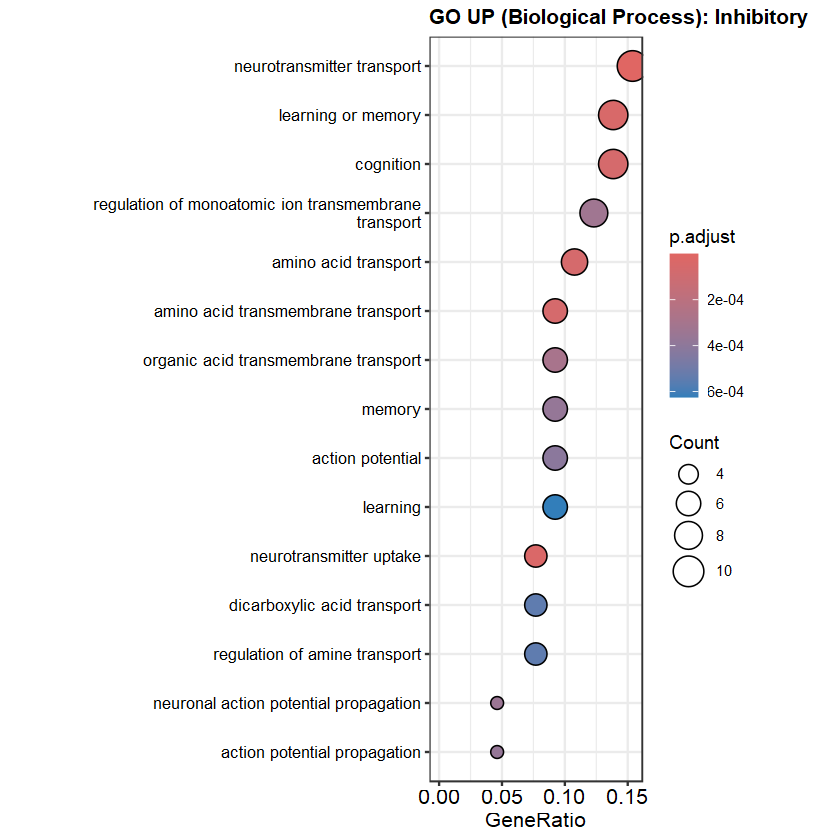

[1] "Saved GO plot for Inhibitory"
[1] "Processing: Excitatory..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


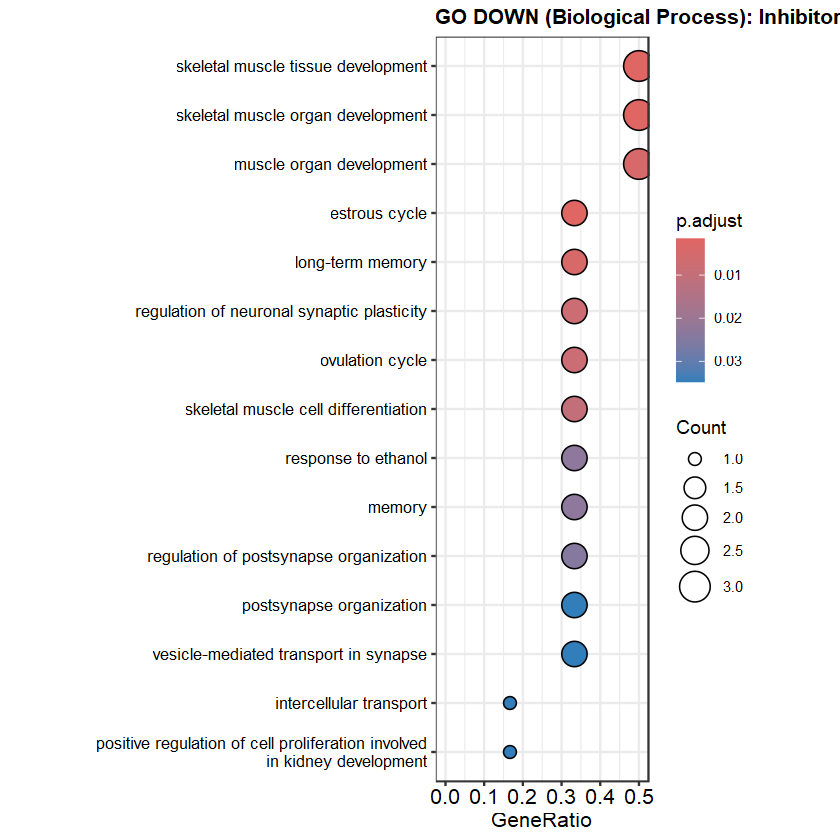

[1] "Saved GO plot for Excitatory"


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


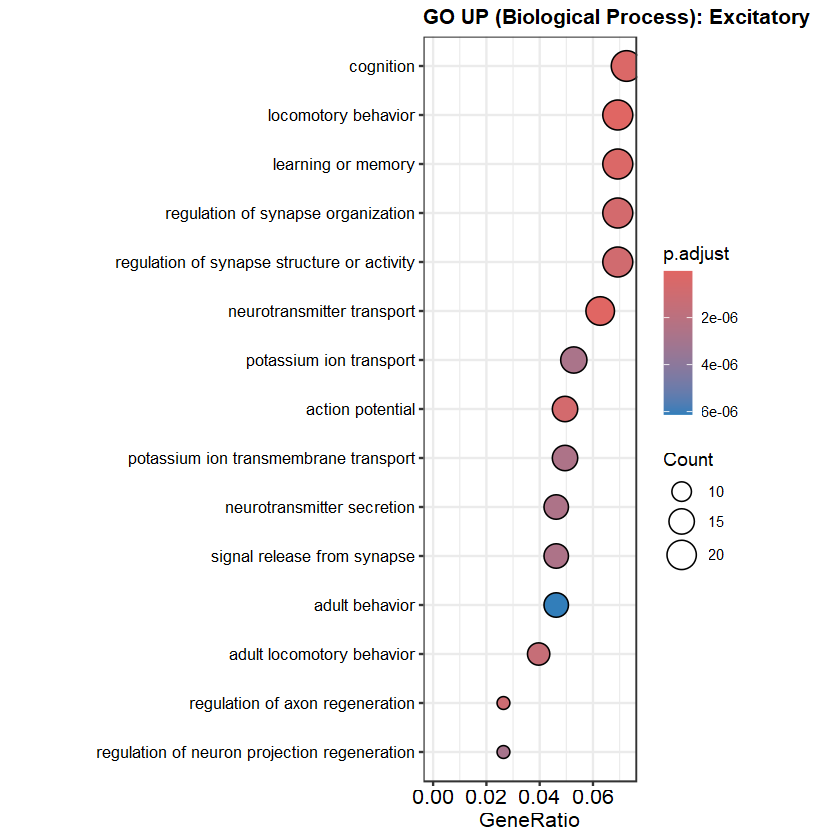

[1] "Saved GO plot for Excitatory"
[1] "Processing: Oligo..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


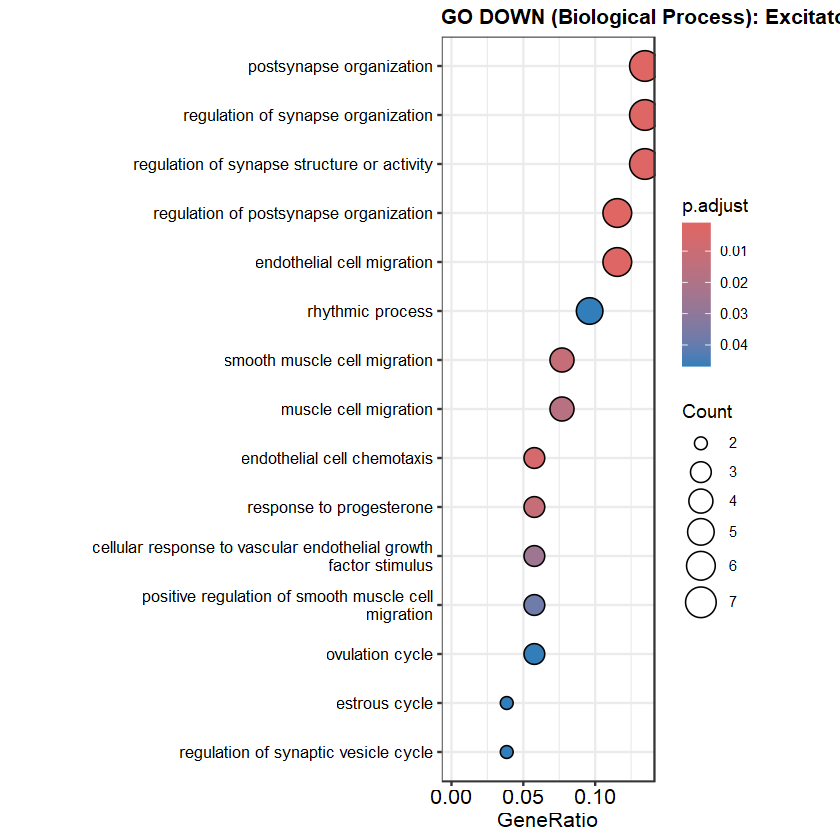

[1] "Saved GO plot for Oligo"


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


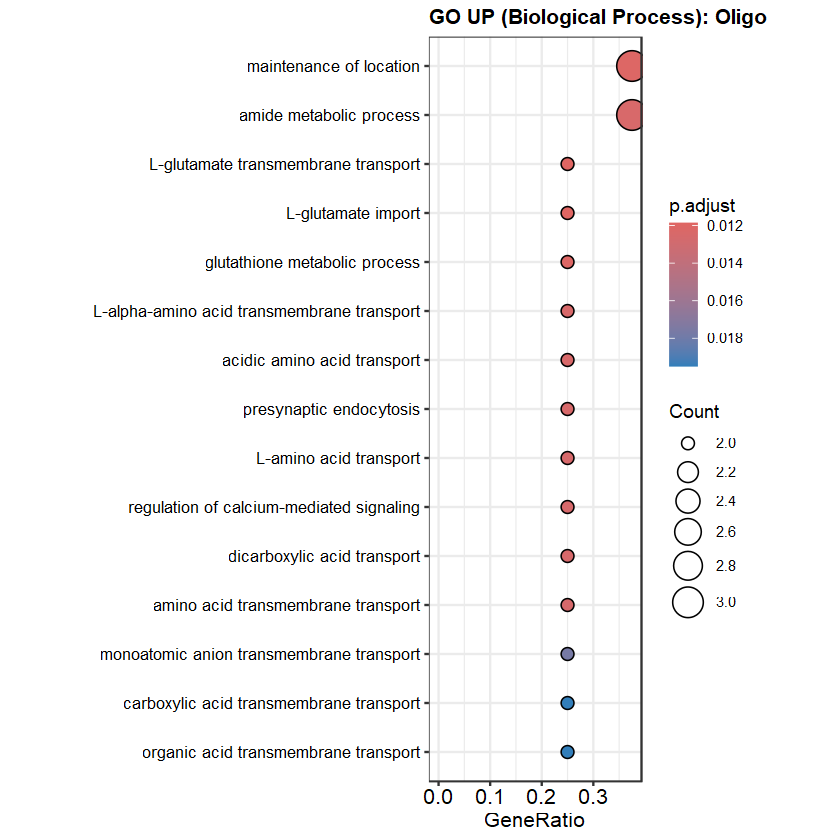

[1] "Saved GO plot for Oligo"
[1] "Processing: Astro..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


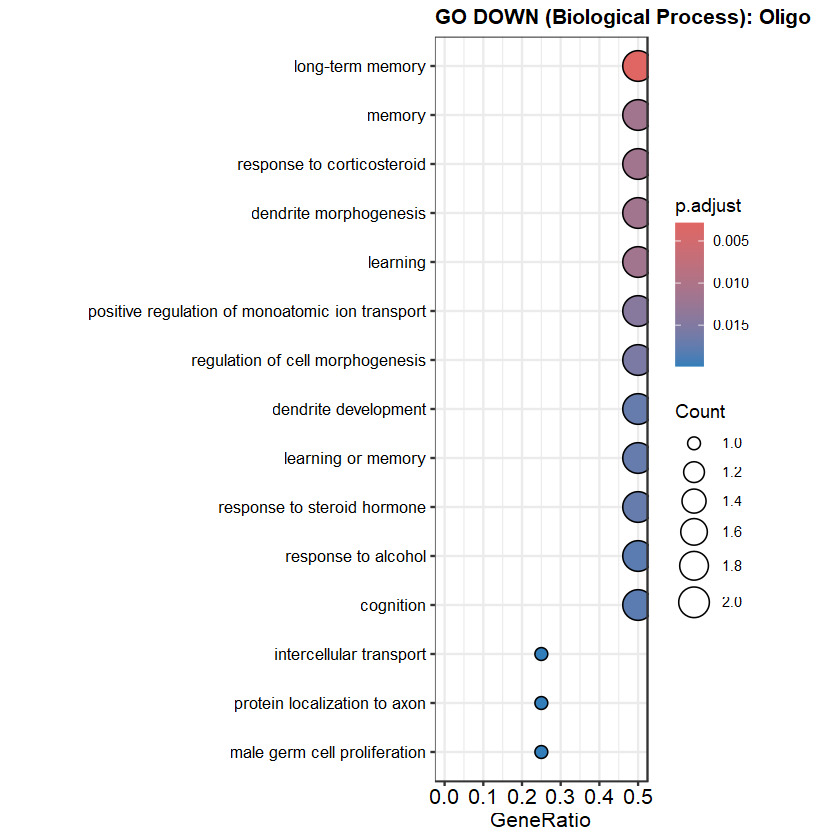

[1] "Saved GO plot for Astro"


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


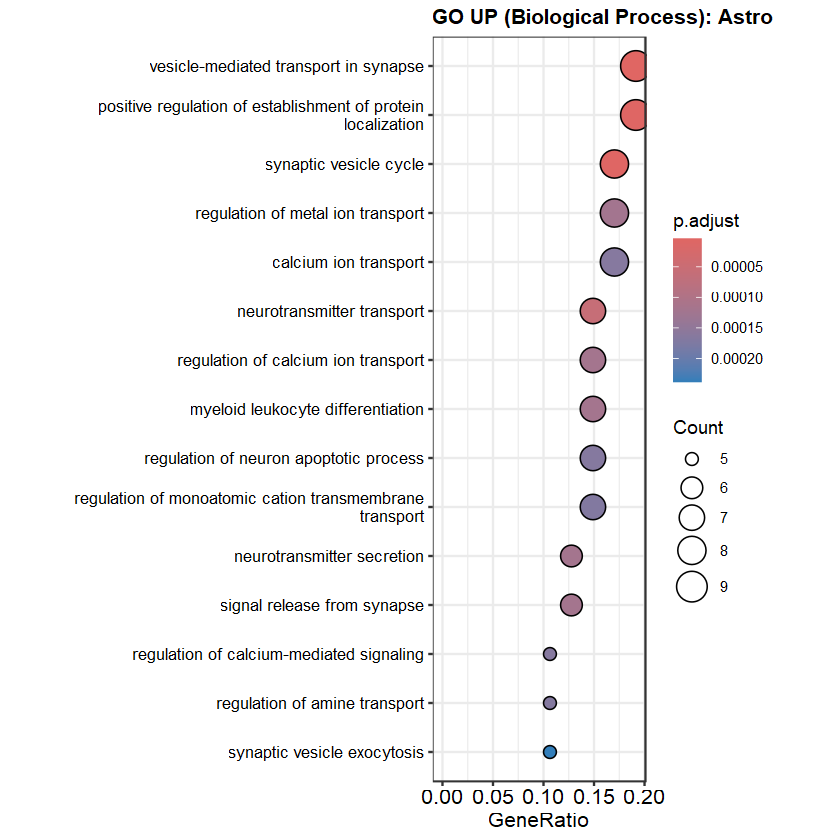

[1] "Saved GO plot for Astro"
[1] "Processing: Endo..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


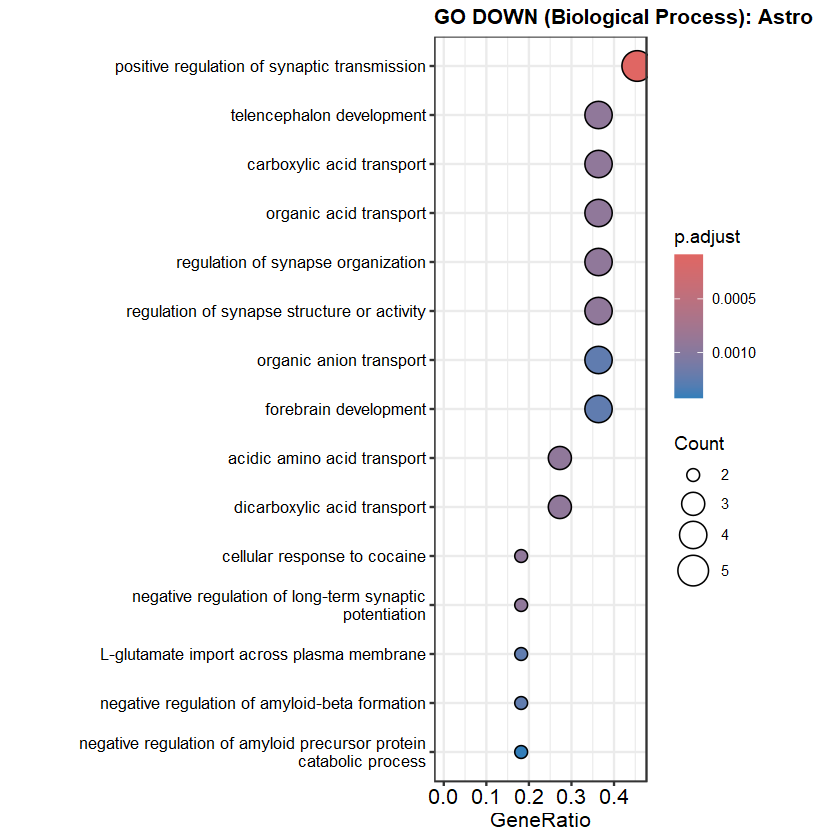

[1] "Saved GO plot for Endo"


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


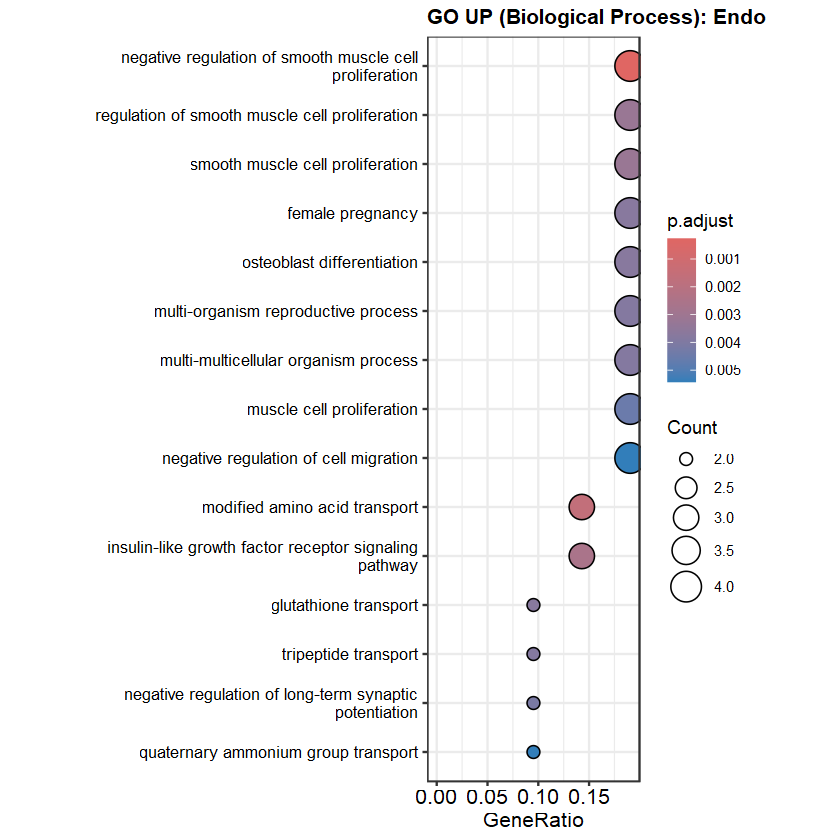

[1] "Saved GO plot for Endo"
[1] "Processing: Microglia..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "Processing: OPC..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


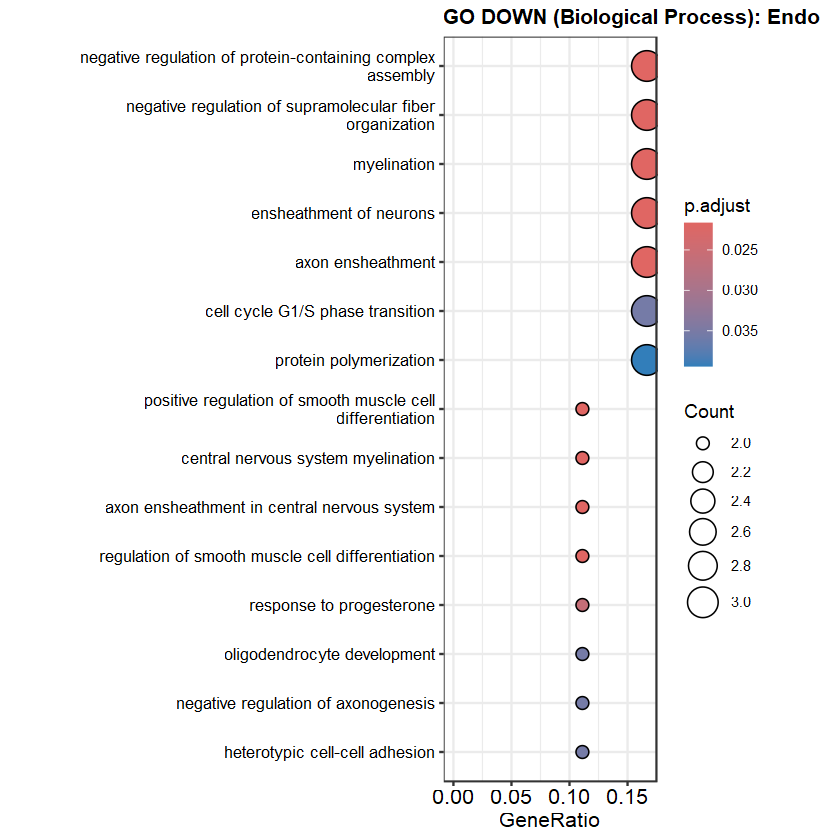

[1] "Saved GO plot for OPC"


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


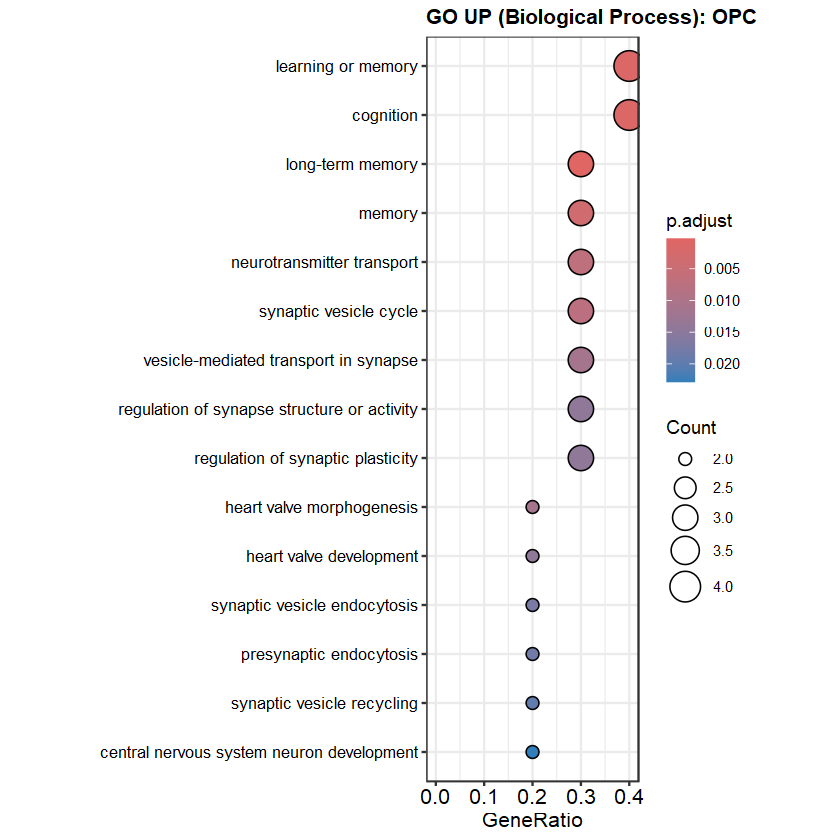

[1] "Saved GO plot for OPC"
[1] "Processing: NF Oligo..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "Task 3 DE & GO Analysis Completed."


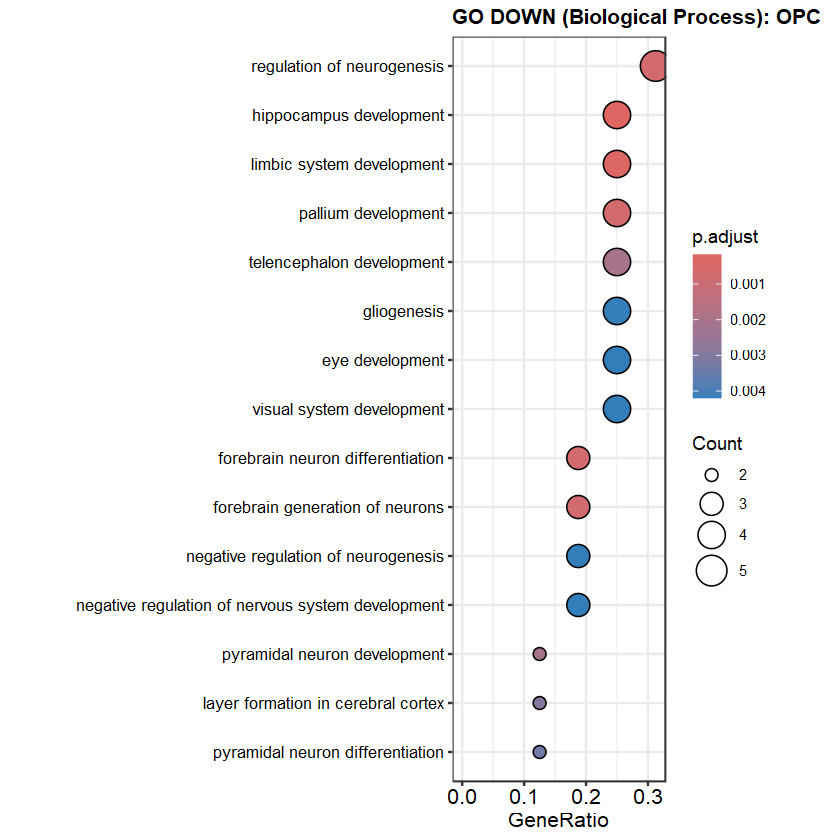

In [17]:
# ================= 3. DE Analysis & GO Enrichment (Per Cell Type) =================
library(Seurat)
library(dplyr)
library(ggplot2)
library(clusterProfiler)
library(org.Mm.eg.db)
library(stringr) # Required to wrap long text labels

print("--- Step 3: Running DE & GO Analysis per Cell Class (Publication Ready) ---")

# Make sure combined_data is loaded
if (!exists("combined_data")) stop("Error: combined_data is missing.")

# Switch back to RNA expression for DE analysis
DefaultAssay(combined_data) <- "Spatial"

# Define cell types to analyze
target_types <- unique(combined_data$predicted_celltype)

# Define Blacklist genes (Striatum markers to exclude, optional)
blacklist_genes <- c("Drd2", "Adora2a")

# Storage for summary
all_markers_list <- list()

for (ctype in target_types) {
  print(paste0("Processing: ", ctype, "..."))
  
  # 3.1 Subset data
  # Wrap in tryCatch so subset errors don't kill the loop
  tryCatch({
    sub_obj <- subset(combined_data, idents = ctype)
    
    # Ensure we have both SMS and CTR cells in this cell type
    if (length(unique(sub_obj$condition)) < 2) {
      print(paste("Skipping", ctype, "- missing condition(s)."))
      next
    }
    
    # 3.2 Find Markers
    markers <- FindMarkers(sub_obj, 
                           ident.1 = "SMS", 
                           ident.2 = "CTR", 
                           group.by = "condition", 
                           logfc.threshold = 0.1, 
                           min.pct = 0.1)
    
    # Clean up results
    if (nrow(markers) > 0) {
      markers$gene <- rownames(markers)
      markers$cell_type <- ctype
      
      # Filter out blacklist genes
      markers <- markers[!markers$gene %in% blacklist_genes, ]
      
      # Save individual CSV
      filename <- paste0("Task2_DEGs_CTX_", gsub(" ", "_", ctype), ".csv")
      write.csv(markers, filename, row.names = FALSE)
      
      # Store for combined list
      all_markers_list[[ctype]] <- markers
      
      # ================= 3.3 GO Enrichment Analysis (Improved Plotting) =================
      
      # Separate Up and Down
      genes_up <- markers$gene[markers$avg_log2FC > 0 & markers$p_val_adj < 0.05]
      genes_down <- markers$gene[markers$avg_log2FC < 0 & markers$p_val_adj < 0.05]
      
      # --- Function to Draw Improved DotPlot ---
      draw_improved_dotplot <- function(gene_list, title_suffix, filename_suffix) {
        if (length(gene_list) > 5) {
          ego <- enrichGO(gene = gene_list, 
                          OrgDb = org.Mm.eg.db, 
                          keyType = "SYMBOL", 
                          ont = "BP", 
                          pAdjustMethod = "BH", 
                          pvalueCutoff = 0.05)
          
          if (!is.null(ego) && nrow(ego) > 0) {
            # Count terms to display so we can scale plot height dynamically
            display_count <- min(15, nrow(ego)) 
            
            p_go <- dotplot(ego, showCategory = display_count) + 
              ggtitle(paste0(title_suffix, ": ", ctype)) +
              
              # === Fix 1: Auto-wrap Y-axis text ===
              scale_y_discrete(labels = function(x) stringr::str_wrap(x, width = 50)) + 
              
              # === Fix for Layout: Compress X-axis to make it narrower ===
              # Anchor X-axis to 0 to pull dots to the left
              scale_x_continuous(limits = c(0, NA)) +
              
              # === Fix 2: Adjust text size, color, and aspect ratio ===
              theme(
                axis.text.y = element_text(size = 10, color = "black"), 
                plot.title = element_text(size = 12, face = "bold"),
                legend.position = "right",
                aspect.ratio = 3.5 # Force a tall and narrow grid layout
              )
            
            # === Fix 3: Dynamic plot height ===
            dynamic_height <- 4 + (display_count * 0.25)
            
            # Print the plot so it appears in the visualization pane
            print(p_go)
            
            # Reduce width from 9 to 6 to physically compress the empty space, 
            # while keeping enough room for the wrapped text on the left.
            ggsave(paste0(filename_suffix, "_", gsub(" ", "_", ctype), ".png"), 
                   plot = p_go, width = 6, height = dynamic_height) 
            
            print(paste("Saved GO plot for", ctype))
          }
        }
      }
      
      # Run GO UP
      draw_improved_dotplot(genes_up, "GO UP (Biological Process)", "Task2_GO_UP")
      
      # Run GO DOWN
      draw_improved_dotplot(genes_down, "GO DOWN (Biological Process)", "Task2_GO_DOWN")
      
    } else {
      print(paste("No significant markers found for", ctype))
    }
    
  }, error = function(e) {
    print(paste("Error processing", ctype, ":", e$message))
  })
}

print("Task 3 DE & GO Analysis Completed.")

[1] "--- Step 4: Generating Summary DotPlot ---"


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


[1] "Task 2 Revision Complete."


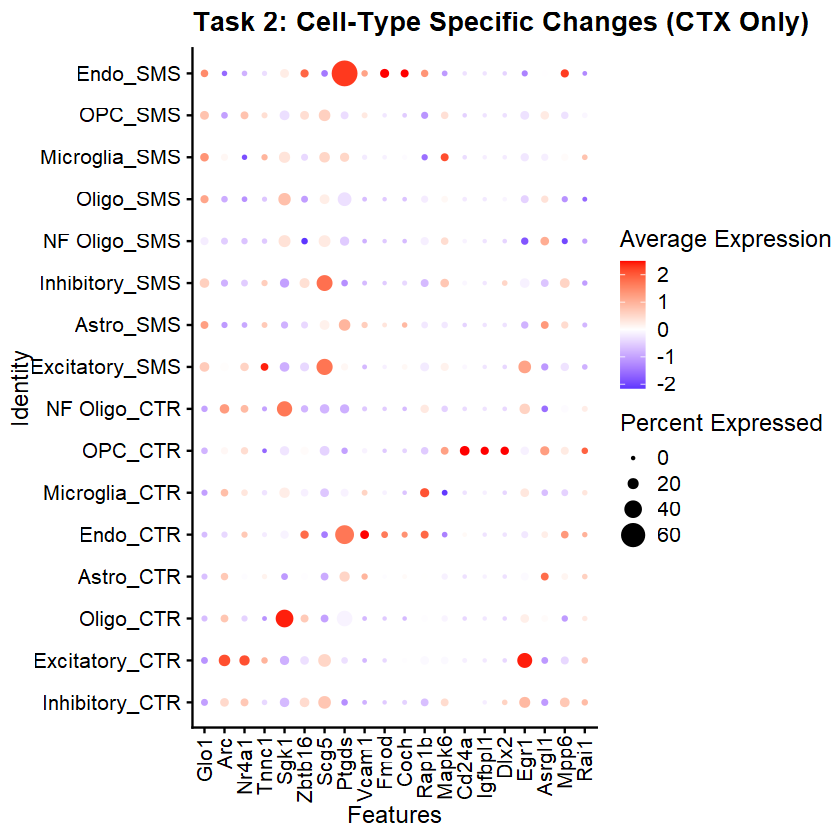

In [18]:
# ================= 4. Visualization: Summary DotPlot =================
print("--- Step 4: Generating Summary DotPlot ---")

if (length(all_markers_list) > 0) {
  # Combine all results
  all_cell_markers <- do.call(rbind, all_markers_list)
  write.csv(all_cell_markers, "Task2_All_CellType_DEGs_Summary.csv", row.names = FALSE)
  
  # Select Top Genes for Plotting
  # Logic: Top 3 Up and Top 3 Down per cell type
  top_genes <- all_cell_markers %>%
    group_by(cell_type) %>%
    top_n(n = 3, wt = abs(avg_log2FC)) %>%
    pull(gene) %>%
    unique()
  
  # Ensure Rai1 is included, ensure Drd2 is excluded
  top_genes <- unique(c(top_genes, "Rai1"))
  top_genes <- setdiff(top_genes, blacklist_genes)
  
  # Prepare Object for DotPlot with split conditions
  combined_data$cell_condition <- paste(Idents(combined_data), combined_data$condition, sep = "_")
  Idents(combined_data) <- "cell_condition"
  
  # Create DotPlot
  p_dot <- DotPlot(combined_data, features = top_genes) + 
    RotatedAxis() +
    scale_color_gradient2(low = "blue", mid = "white", high = "red") +
    ggtitle("Task 2: Cell-Type Specific Changes (CTX Only)") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))
  
  print(p_dot)
  ggsave("Task2_Final_DotPlot_CTX.png", plot = p_dot, width = 15, height = 8)
  
} else {
  print("Warning: No DEGs found across any cell types.")
}

print("Task 2 Revision Complete.")

# Task2 Additional 2026/01/20

[1] "Recalculating PCA and UMAP for combined data..."


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session"


[1] "UMAP calculation complete."
[1] "Generating Rai1 Dot Plot..."


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


[1] "Generating Global UMAP..."


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



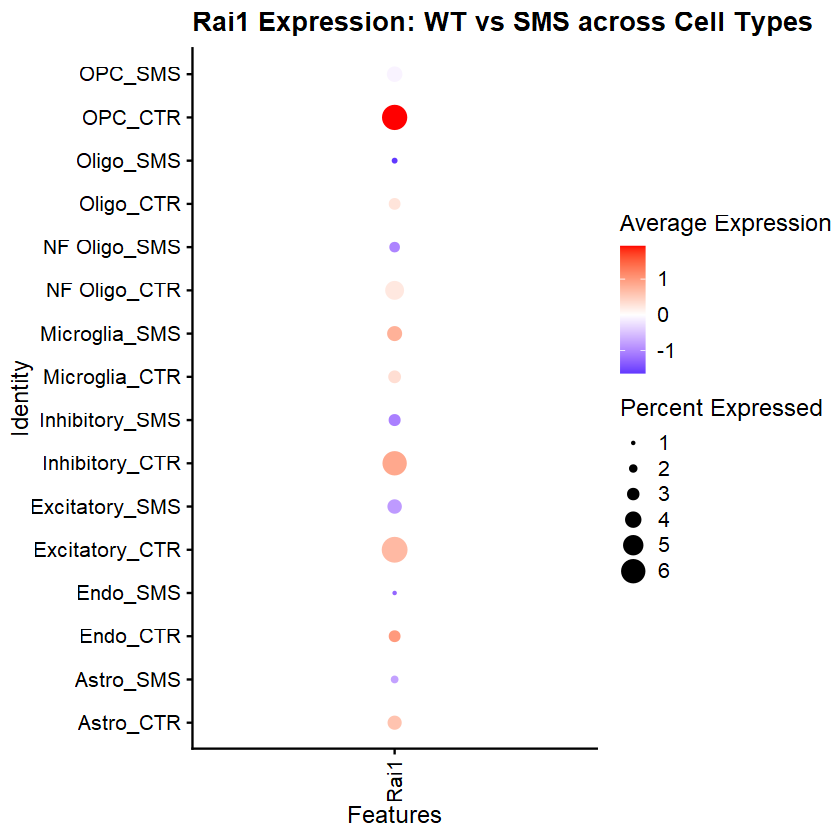

[1] "Generating Cell Count Statistics..."


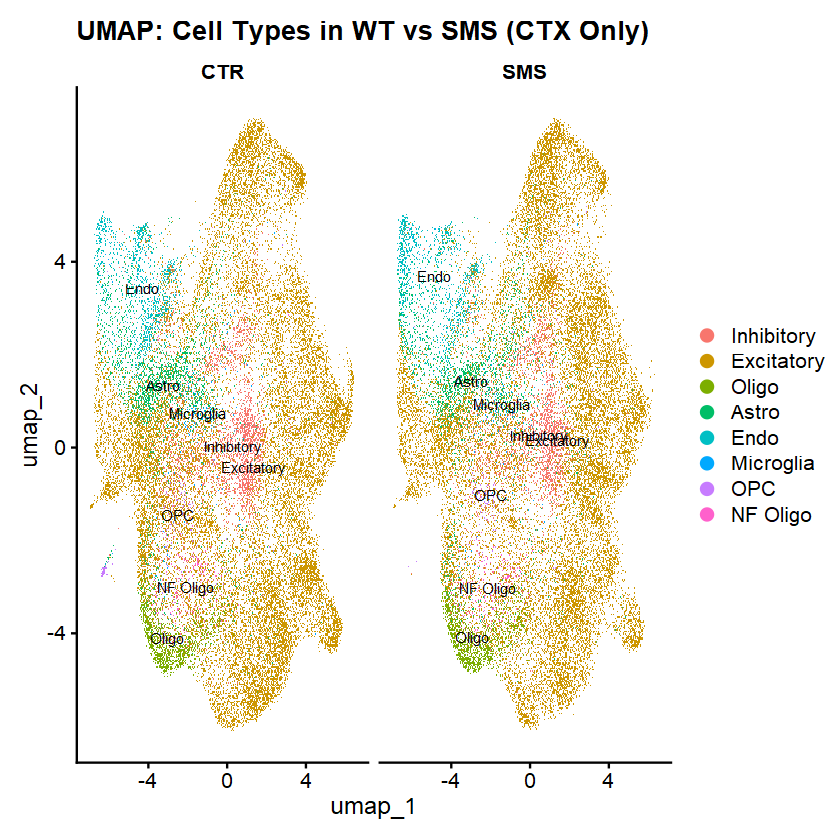

[1] "Task 2 Additional Plots Completed."


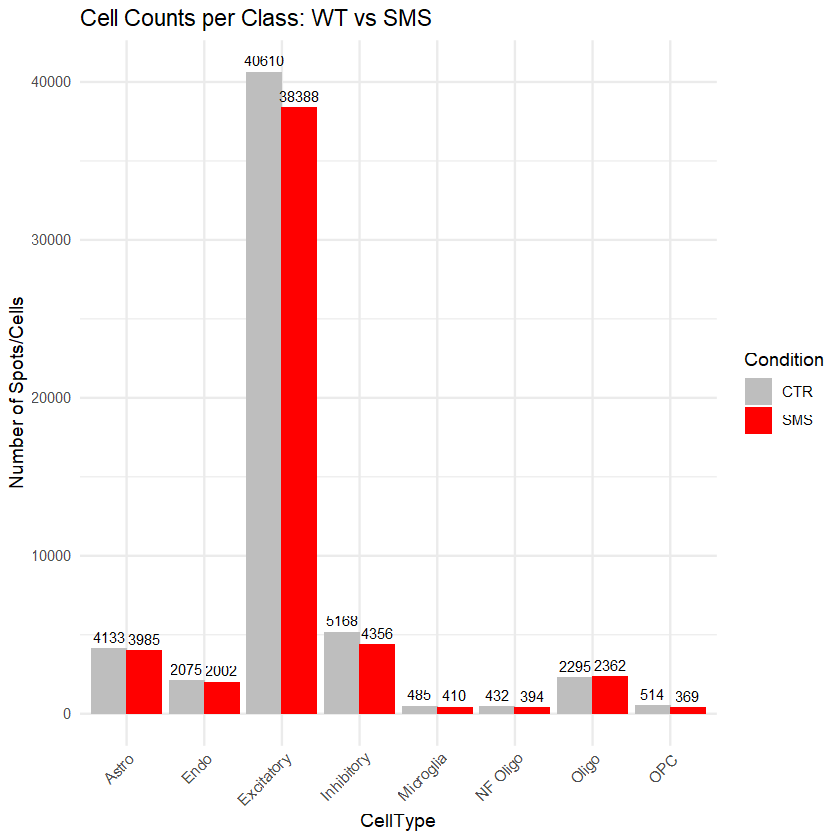

In [19]:
# ================= Task 2 Additions: Global Visualization (FIXED) =================

# 1. Ensure combined data is loaded
if (!exists("combined_data")) stop("Error: combined_data missing. Load Task 1/2 data first.")

# 2. Critical fix: Recalculate PCA and UMAP
# Merging/subsetting drops the old UMAP embeddings, so we need to run them from scratch here
print("Recalculating PCA and UMAP for combined data...")

DefaultAssay(combined_data) <- "Spatial"
combined_data <- NormalizeData(combined_data)
combined_data <- FindVariableFeatures(combined_data, selection.method = "vst", nfeatures = 2000)
combined_data <- ScaleData(combined_data)
combined_data <- RunPCA(combined_data, verbose = FALSE)
combined_data <- RunUMAP(combined_data, dims = 1:30, verbose = FALSE)

print("UMAP calculation complete.")

# ================= Visualization Starts Here =================

# 3. Dot Plot of Rai1 (Rai1 in 8 Cell Types)
print("Generating Rai1 Dot Plot...")

# Create temporary grouping column
combined_data$celltype_condition <- paste(combined_data$predicted_celltype, combined_data$condition, sep = "_")

# Define order (CTR left, SMS right)
cell_types <- sort(unique(combined_data$predicted_celltype))
levels_order <- c()
for (ct in cell_types) {
  levels_order <- c(levels_order, paste0(ct, "_CTR"), paste0(ct, "_SMS"))
}
# Filter valid levels
levels_order <- levels_order[levels_order %in% unique(combined_data$celltype_condition)]
Idents(combined_data) <- factor(combined_data$celltype_condition, levels = levels_order)

p_rai1 <- DotPlot(combined_data, features = "Rai1") + 
  RotatedAxis() +
  scale_color_gradient2(low = "blue", mid = "white", high = "red") +
  ggtitle("Rai1 Expression: WT vs SMS across Cell Types") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

print(p_rai1)
ggsave("Task2_Rai1_DotPlot_AllCells.png", plot = p_rai1, width = 10, height = 6)


# 4. UMAP of 8 Cell Types (WT and SMS)
print("Generating Global UMAP...")

# Revert Identity to simple cell type
Idents(combined_data) <- "predicted_celltype"

# Plot split by condition
p_umap_split <- DimPlot(combined_data, reduction = "umap", split.by = "condition", label = TRUE, label.size = 3) +
  ggtitle("UMAP: Cell Types in WT vs SMS (CTX Only)") +
  theme(legend.position = "right")

print(p_umap_split)
ggsave("Task2_UMAP_Global_Split.png", plot = p_umap_split, width = 14, height = 6)


# 5. Cell Count Bar Graph (WT vs SMS)
print("Generating Cell Count Statistics...")

df_counts <- as.data.frame(table(combined_data$predicted_celltype, combined_data$condition))
colnames(df_counts) <- c("CellType", "Condition", "Count")

p_counts <- ggplot(df_counts, aes(x = CellType, y = Count, fill = Condition)) +
  geom_bar(stat = "identity", position = position_dodge()) +
  geom_text(aes(label = Count), position = position_dodge(width = 0.9), vjust = -0.5, size = 3) +
  scale_fill_manual(values = c("CTR" = "grey", "SMS" = "red")) +
  theme_minimal() +
  labs(title = "Cell Counts per Class: WT vs SMS", y = "Number of Spots/Cells") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

print(p_counts)
ggsave("Task2_CellCounts_BarPlot.png", plot = p_counts, width = 10, height = 6)

print("Task 2 Additional Plots Completed.")

[1] "Regenerating Rai1 Dot Plot with Revised Layout (Side-by-Side)..."


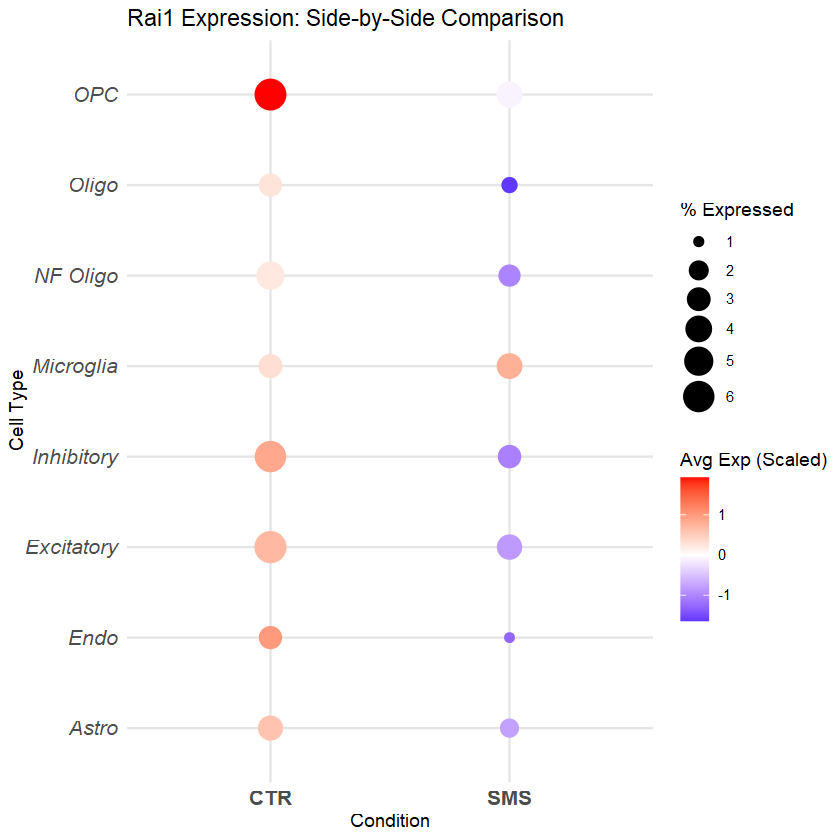

In [20]:
# ================= 1. Dot Plot Revision: Layout Change =================
library(ggplot2)
library(dplyr)
library(Seurat)

print("Regenerating Rai1 Dot Plot with Revised Layout (Side-by-Side)...")

# 1. Extract plotting data
# Pull raw data to manually calculate mean expression and percent expressed for full control
rai1_data <- FetchData(combined_data, vars = c("Rai1", "predicted_celltype", "condition"))

# 2. Manual stat calculation (crucial for addressing the PI's concerns about Percent Expressed)
plot_df <- rai1_data %>%
  group_by(predicted_celltype, condition) %>%
  summarise(
    AvgExpression = mean(expm1(Rai1)),  # Un-log data using expm1 for a more accurate mean
    # % expressed: count of cells with Exp > 0 / total cells per group
    PercentExpressed = sum(Rai1 > 0) / n() * 100,
    .groups = 'drop'
  )

# 3. Re-log and scale the means for color mapping
plot_df$AvgExpressionScaled <- scale(log1p(plot_df$AvgExpression))

# 4. Custom ggplot2 visualization
# Y-axis: Cell Type
# X-axis: Condition
p_dot_revised <- ggplot(plot_df, aes(x = condition, y = predicted_celltype)) +
  geom_point(aes(size = PercentExpressed, color = AvgExpressionScaled)) +
  scale_size(range = c(2, 8)) + # Scale point size limits
  scale_color_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  theme_minimal() +
  labs(
    title = "Rai1 Expression: Side-by-Side Comparison",
    x = "Condition",
    y = "Cell Type",
    size = "% Expressed",
    color = "Avg Exp (Scaled)"
  ) +
  theme(
    axis.text.x = element_text(size = 12, face = "bold"),
    axis.text.y = element_text(size = 12, face = "italic"),
    panel.grid.major = element_line(color = "grey90")
  )

print(p_dot_revised)
ggsave("Task2_Rai1_DotPlot_SideBySide.png", plot = p_dot_revised, width = 6, height = 8)

[1] "Generating Fair Comparison Dot Plot..."
[1] "The following groups have low expression counts and were masked to neutral color:"
# A tibble: 4 × 3
  predicted_celltype condition Cells_Expressing_Rai1
  <chr>              <chr>                     <int>
1 Microglia          CTR                          15
2 Microglia          SMS                          15
3 NF Oligo           SMS                          10
4 OPC                SMS                          14


Warning message:
"The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead."


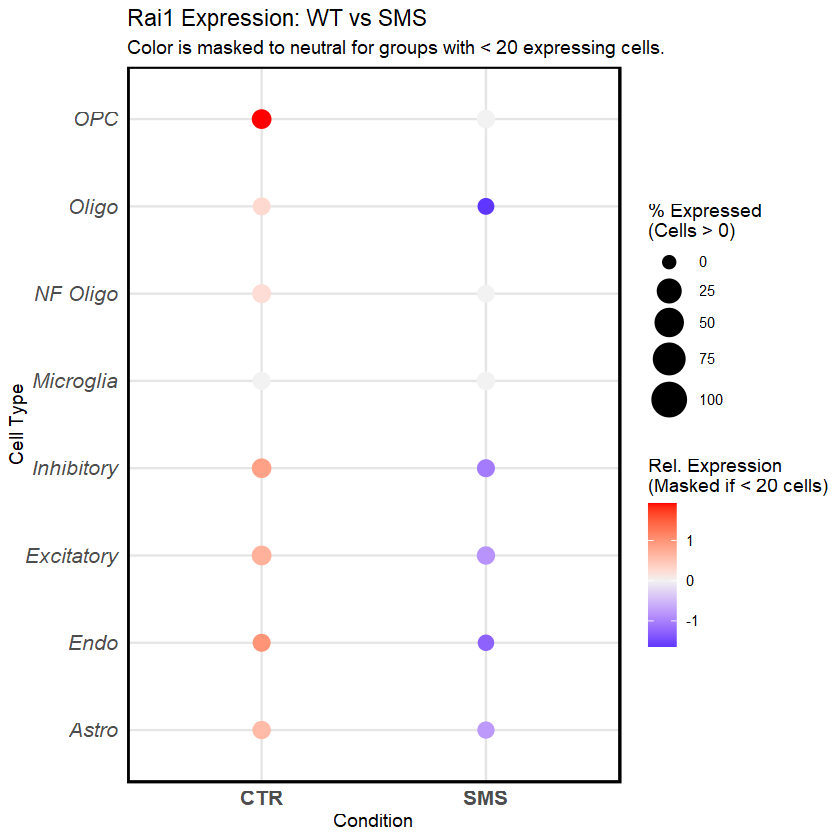

In [21]:
# ================= Task 2: Rai1 Dot Plot (With Noise Masking) =================
library(dplyr)
library(ggplot2)
library(Seurat)

print("Generating Fair Comparison Dot Plot...")

# 1. Extract raw data (same as before)
rai1_data <- FetchData(combined_data, vars = c("Rai1", "predicted_celltype", "condition"), layer = "data")

# 2. Calculate summary statistics
plot_stats <- rai1_data %>%
  group_by(predicted_celltype, condition) %>%
  summarise(
    Total_Cells = n(),
    Cells_Expressing_Rai1 = sum(Rai1 > 0),
    # Calculate % expressed
    Percent_Expressed = (sum(Rai1 > 0) / n()) * 100,
    # Calculate raw mean expression
    Avg_Expression = mean(expm1(Rai1)), 
    .groups = 'drop'
  )

# 3. Z-score normalization (for dot color)
# Scale across the board to get relative highs/lows
plot_stats$Avg_Scaled <- scale(log1p(plot_stats$Avg_Expression))

# ================= CRITICAL MOD: Fair Noise Masking =================

# Set threshold: expression is unreliable if too few cells express the gene (e.g., < 20)
# Force these low-confidence groups to 0 (maps to neutral/white in gradient2)
# Rationale: prevents extreme color shifts caused by just 1 or 2 noisy cells
min_cell_threshold <- 20  # Microglia had 15 in the table, so 20 is a safe threshold to mask it

# Create a new column specifically for plot colors
plot_stats$Color_Value <- plot_stats$Avg_Scaled

# Apply the mask
mask_indices <- plot_stats$Cells_Expressing_Rai1 < min_cell_threshold
plot_stats$Color_Value[mask_indices] <- 0  # Force to neutral color (white)

# Print out the masked groups for your Methods write-up
print("The following groups have low expression counts and were masked to neutral color:")
print(plot_stats[mask_indices, c("predicted_celltype", "condition", "Cells_Expressing_Rai1")])

# ==========================================================

# 4. Plotting
p_fair <- ggplot(plot_stats, aes(x = condition, y = predicted_celltype)) +
  # Note: We map color to our newly masked Color_Value
  geom_point(aes(size = Percent_Expressed, color = Color_Value)) +
  
  # Lock the size range (so Microglia dots don't vanish even at 3%)
  scale_size_continuous(range = c(3, 9), limits = c(0, 100), name = "% Expressed\n(Cells > 0)") +
  
  # Color gradient
  scale_color_gradient2(
    low = "blue", mid = "grey95", high = "red", 
    midpoint = 0, 
    name = "Rel. Expression\n(Masked if < 20 cells)"
  ) +
  
  theme_minimal() +
  labs(
    title = "Rai1 Expression: WT vs SMS",
    subtitle = "Color is masked to neutral for groups with < 20 expressing cells.",
    x = "Condition",
    y = "Cell Type"
  ) +
  theme(
    axis.text.x = element_text(size = 12, face = "bold"),
    axis.text.y = element_text(size = 12, face = "italic"),
    panel.grid.major = element_line(color = "grey90"),
    panel.border = element_rect(color = "black", fill = NA, size = 1)
  )

print(p_fair)
ggsave("Task2_Rai1_DotPlot_Revised.png", plot = p_fair, width = 6, height = 8)

[1] "Starting Volcano Plot generation for Task 2 (8 Cell Classes)..."
[1] "Processing: Astro (SMS: 3985, CTR: 4133)"


Warning message:
"Removed 1311 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 1311 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


[1] "  Saved: Task2_Volcano_Astro.png"
[1] "Processing: Endo (SMS: 2002, CTR: 2075)"


Warning message:
"Removed 865 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 865 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


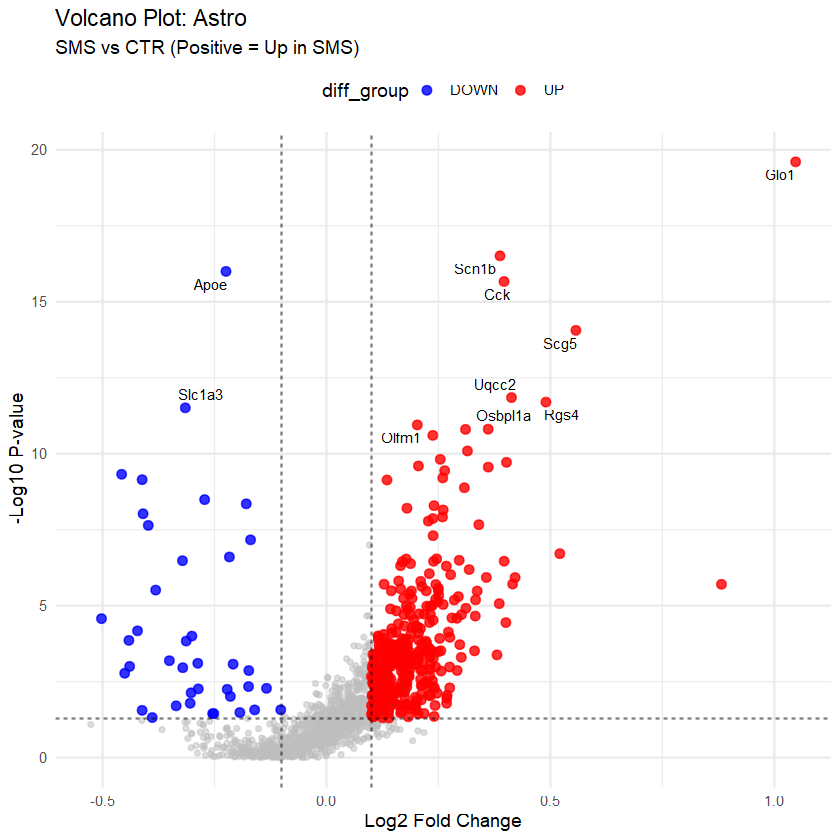

[1] "  Saved: Task2_Volcano_Endo.png"
[1] "Processing: Excitatory (SMS: 38388, CTR: 40610)"


Warning message:
"Removed 2917 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 2917 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


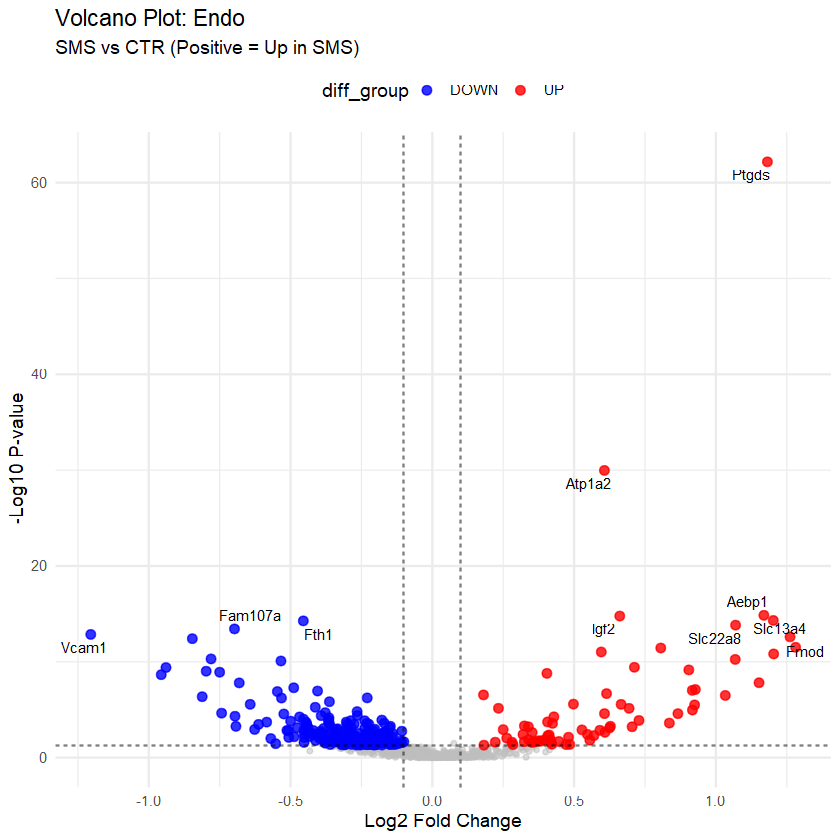

[1] "  Saved: Task2_Volcano_Excitatory.png"
[1] "Processing: Inhibitory (SMS: 4356, CTR: 5168)"


Warning message:
"Removed 2764 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 2764 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


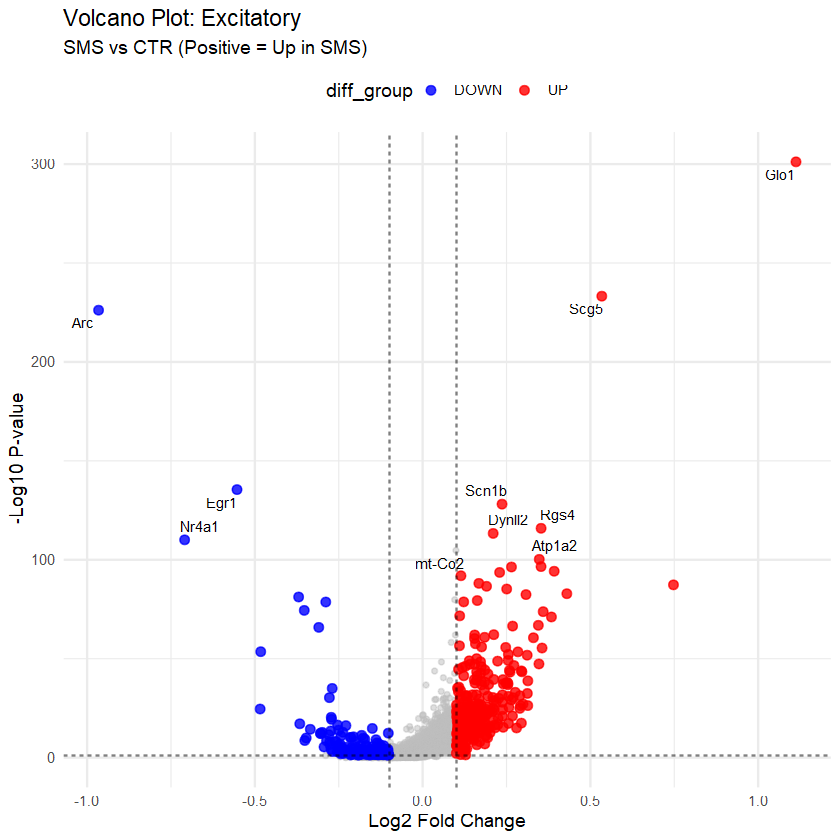

[1] "  Saved: Task2_Volcano_Inhibitory.png"
[1] "Processing: Microglia (SMS: 410, CTR: 485)"


Warning message:
"Removed 1786 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 1786 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


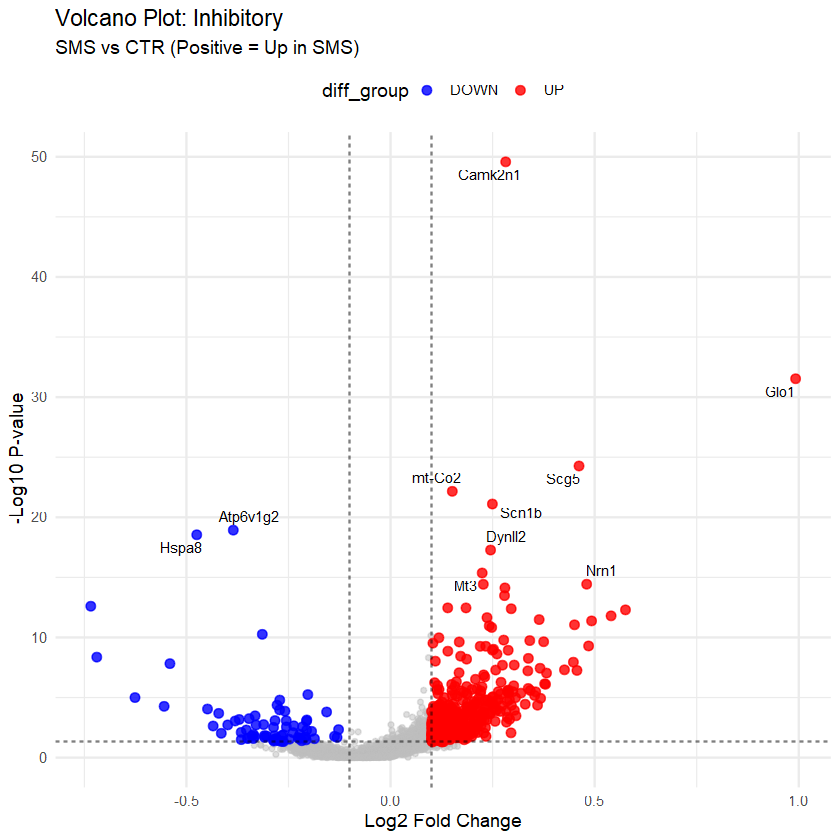

[1] "  Saved: Task2_Volcano_Microglia.png"
[1] "Processing: NF Oligo (SMS: 394, CTR: 432)"


Warning message:
"Removed 2213 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 2213 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


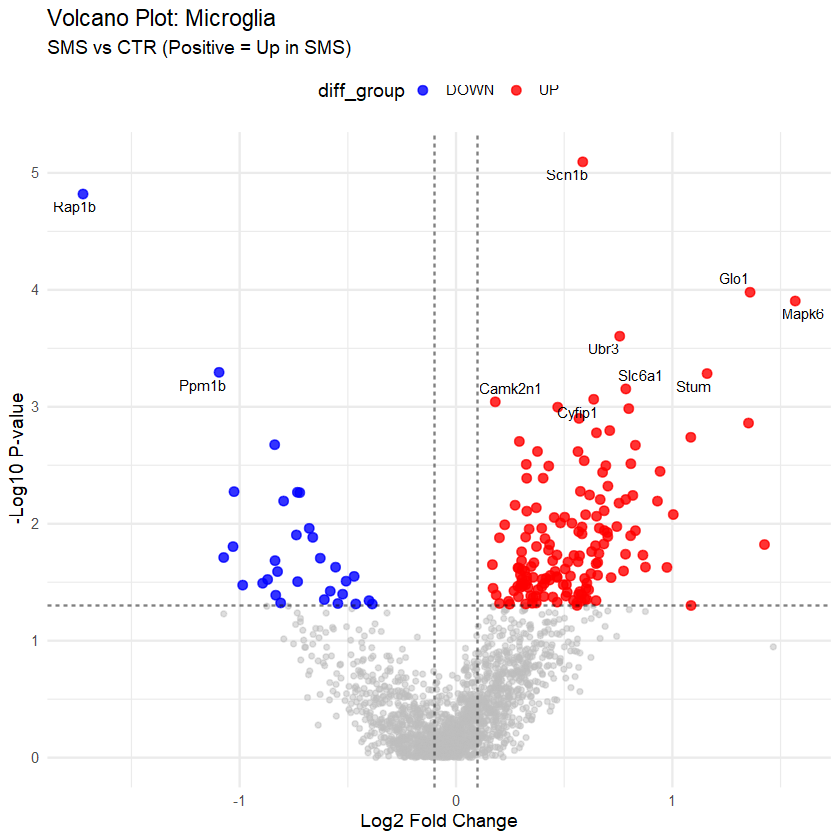

[1] "  Saved: Task2_Volcano_NF_Oligo.png"
[1] "Processing: Oligo (SMS: 2362, CTR: 2295)"


Warning message:
"Removed 1518 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 1518 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


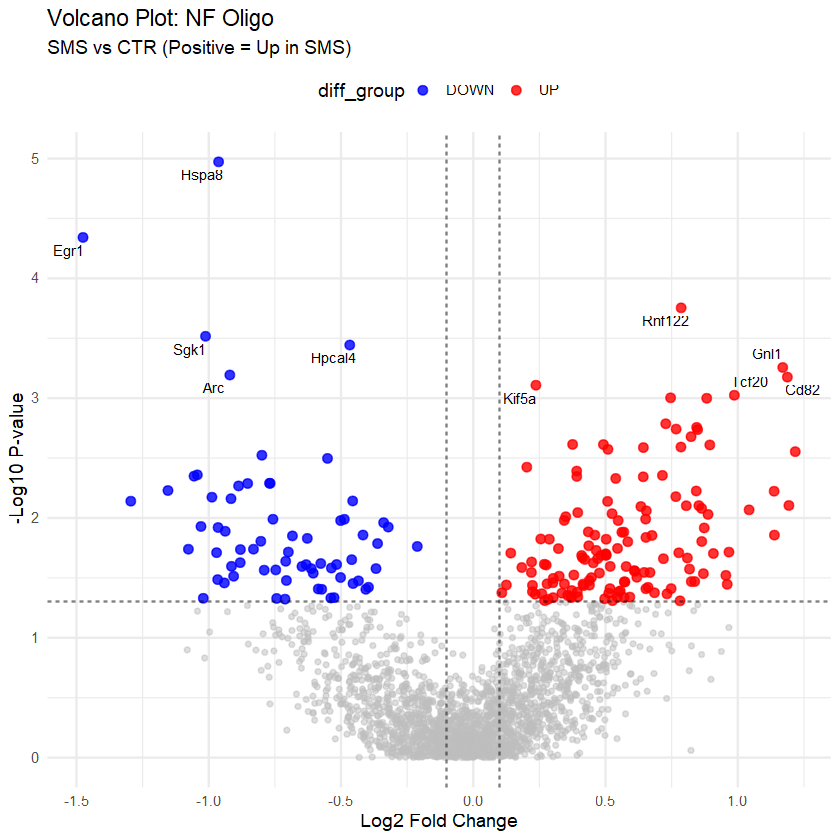

[1] "  Saved: Task2_Volcano_Oligo.png"
[1] "Processing: OPC (SMS: 369, CTR: 514)"


Warning message:
"Removed 2526 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 2526 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


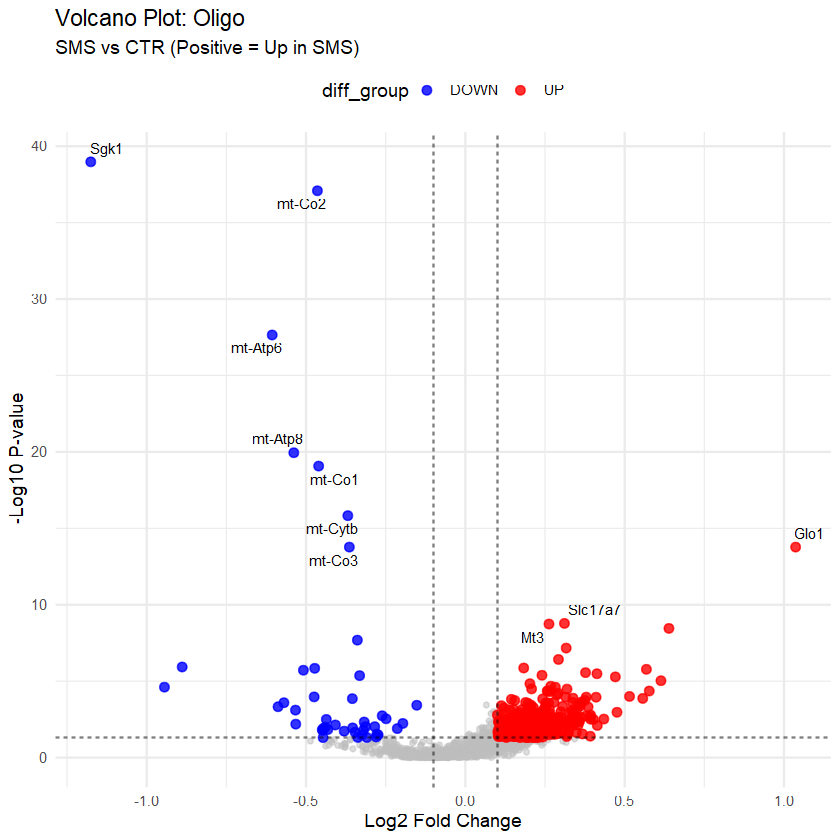

[1] "  Saved: Task2_Volcano_OPC.png"
[1] "Task 2 Volcano Plots Completed."


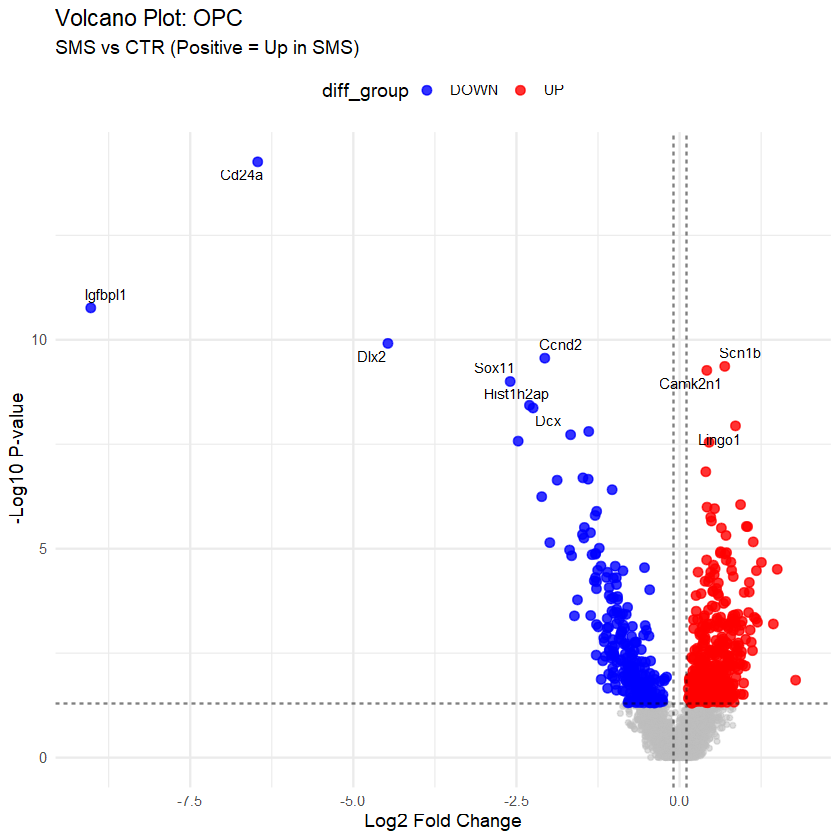

In [23]:
# ================= Task 2 Extension: Volcano Plots for All 8 Cell Types =================
library(Seurat)
library(ggplot2)
library(ggrepel)
library(dplyr)

print("Starting Volcano Plot generation for Task 2 (8 Cell Classes)...")

# 1. Prep data: Create composite idents for DE contrast
# Expected format: "Astro_CTR", "Astro_SMS"
combined_data$celltype_condition <- paste(combined_data$predicted_celltype, combined_data$condition, sep = "_")
Idents(combined_data) <- "celltype_condition"

# 2. Grab all unique cell types
cell_types <- sort(unique(combined_data$predicted_celltype))

# 3. Loop over each cell type
for (ct in cell_types) {
  
  # Define DE contrast groups
  ident_sms <- paste0(ct, "_SMS")
  ident_ctr <- paste0(ct, "_CTR")
  
  # QC: Ensure both groups have at least 3 cells before running DE
  n_sms <- sum(Idents(combined_data) == ident_sms)
  n_ctr <- sum(Idents(combined_data) == ident_ctr)
  
  print(paste0("Processing: ", ct, " (SMS: ", n_sms, ", CTR: ", n_ctr, ")"))
  
  if (n_sms < 3 || n_ctr < 3) {
    print(paste("  Skipping", ct, "- not enough cells for DE analysis."))
    next
  }
  
  # 4. Run DE (FindMarkers)
  # logfc.threshold = 0: Keep everything to form the volcano background
  # min.pct = 0.1: Filter for genes expressed in >= 10% of cells
  tryCatch({
    de_results <- FindMarkers(combined_data, 
                              ident.1 = ident_sms, 
                              ident.2 = ident_ctr, 
                              logfc.threshold = 0,
                              min.pct = 0.1,
                              verbose = FALSE)
    
    # Pull rownames to a gene column
    de_results$gene <- rownames(de_results)
    
    # 5. Classify genes as Up/Down/NS
    # Cutoffs: P-value < 0.05 and |log2FC| > 0.1 (tweak if needed)
    de_results$diff_group <- "NS"
    de_results$diff_group[de_results$p_val < 0.05 & de_results$avg_log2FC > 0.1] <- "UP"
    de_results$diff_group[de_results$p_val < 0.05 & de_results$avg_log2FC < -0.1] <- "DOWN"
    
    # 6. Labeling (grab top 10 genes by p-value for labeling)
    de_results$label <- NA
    top_genes <- head(de_results[order(de_results$p_val), "gene"], 10)
    de_results$label[de_results$gene %in% top_genes] <- de_results$gene[de_results$gene %in% top_genes]
    
    # 7. Build Volcano Plot via ggplot2
    p_vol <- ggplot(de_results, aes(x = avg_log2FC, y = -log10(p_val))) +
      # Background genes (NS)
      geom_point(data = subset(de_results, diff_group == "NS"), 
                 color = "grey", alpha = 0.5, size = 1) +
      # Significant genes (Up/Down)
      geom_point(data = subset(de_results, diff_group != "NS"), 
                 aes(color = diff_group), alpha = 0.8, size = 2) +
      
      # Custom colors
      scale_color_manual(values = c("DOWN" = "blue", "UP" = "red")) +
      
      # Visual thresholds
      geom_vline(xintercept = c(-0.1, 0.1), linetype = "dashed", color = "black", alpha=0.5) +
      geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "black", alpha=0.5) +
      
      # Add text labels (with repel to avoid overlaps)
      geom_text_repel(aes(label = label), size = 3, max.overlaps = 20) +
      
      theme_minimal() +
      labs(title = paste0("Volcano Plot: ", ct),
           subtitle = "SMS vs CTR (Positive = Up in SMS)",
           x = "Log2 Fold Change",
           y = "-Log10 P-value") +
      theme(legend.position = "top")
    
    # 8. Save plot
    # Replace spaces in filenames with underscores
    filename <- paste0("Task2_Volcano_", gsub(" ", "_", ct), ".png") 
    
    # 
    print(p_vol)
    
    ggsave(filename, plot = p_vol, width = 7, height = 6)
    print(paste("  Saved:", filename))
    
  }, error = function(e) {
    print(paste("  Error calculating DE for", ct, ":", e$message))
  })
}

print("Task 2 Volcano Plots Completed.")

# Task3 

In [24]:
# ================= 1. Environment & Paths =================
# Set paths to square_016um (Contains necessary coordinate files)
path_ctr_root <- "F:\\H.M.打火机\\Huang_Minza__Ctr_1_A1\\square_016um"
path_sms_root <- "F:\\H.M.打火机\\Huang_Minza__SMS_1_D1\\square_016um"

# Load packages
packages <- c("Seurat", "dplyr", "ggplot2", "hdf5r", "patchwork", "ggrepel", "ggVennDiagram", "clusterProfiler", "org.Mm.eg.db", "enrichplot")
for (pkg in packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) install.packages(pkg)
}

library(Seurat)
library(dplyr)
library(ggplot2)
library(hdf5r)
library(patchwork)
library(ggrepel)
library(ggVennDiagram)
library(clusterProfiler)
library(org.Mm.eg.db)
library(enrichplot)

Warning message:
"package 'hdf5r' was built under R version 4.4.3"

Attaching package: 'hdf5r'


The following object is masked from 'package:S4Vectors':

    values


Warning message:
"package 'ggVennDiagram' was built under R version 4.4.3"


In [25]:
# ================= 2. Helper Functions =================

# 2.1 Robust Loading Function
load_hd_data_correctly <- function(data_dir, sample_id) {
  # Auto-detect H5 filename
  possible_names <- c("filtered_feature_bc_matrix.h5", "filtered_feature_cell_matrix.h5")
  found_file <- possible_names[file.exists(file.path(data_dir, possible_names))][1]
  
  if (is.na(found_file)) {
    stop(paste("Error: No H5 matrix found in", data_dir))
  }
  
  print(paste("Loading Spatial Data from:", data_dir))
  
  # Load data with coordinates
  tryCatch({
    obj <- Load10X_Spatial(
      data.dir = data_dir, 
      filename = found_file,
      filter.matrix = FALSE 
    )
    obj$condition <- sample_id
    obj$orig.ident <- sample_id
    return(obj)
  }, error = function(e) {
    stop(paste("Load failed. Ensure 'spatial' folder exists with coordinates.\nError:", e$message))
  })
}

# 2.2 Spatial Cropping Helper (Task 1 Coordinates)
subset_by_coords <- function(obj, boxes) {
  coords <- GetTissueCoordinates(obj)
  x_col <- grep("col|x", colnames(coords), value = TRUE)[1]
  y_col <- grep("row|y", colnames(coords), value = TRUE)[1]
  
  cells_to_keep <- c()
  for (i in 1:nrow(boxes)) {
    ids <- rownames(coords[coords[[x_col]] >= boxes$xmin[i] & coords[[x_col]] <= boxes$xmax[i] &
                           coords[[y_col]] >= boxes$ymin[i] & coords[[y_col]] <= boxes$ymax[i], ])
    cells_to_keep <- c(cells_to_keep, ids)
  }
  
  print(paste("Cells kept after cropping:", length(unique(cells_to_keep))))
  
  if(length(cells_to_keep) == 0) {
    warning("Warning: No cells found in box. Check coordinates.")
    return(obj) 
  }
  return(subset(obj, cells = unique(cells_to_keep)))
}

# Define Coordinates (Finalized from Task 1)
ctr_boxes <- data.frame(
  xmin = c(4000, 15500), xmax = c(14500, 27500),
  ymin = c(7000, 6000), ymax = c(17500, 16500)
)
sms_boxes <- data.frame(
  xmin = c(15000, 2000), xmax = c(26000, 14500),
  ymin = c(10000, 12500), ymax = c(19500, 21500)
)

In [26]:
# ================= 3. Load, Merge & CROP =================
print("Loading data from square_016um...")

# Load & Crop CTR
ctr_seg <- load_hd_data_correctly(path_ctr_root, "CTR")
print("Applying Task 1 Cropping to CTR...")
ctr_seg <- subset_by_coords(ctr_seg, ctr_boxes)

# Load & Crop SMS
sms_seg <- load_hd_data_correctly(path_sms_root, "SMS")
print("Applying Task 1 Cropping to SMS...")
sms_seg <- subset_by_coords(sms_seg, sms_boxes)

print("Merging datasets...")
seg_data <- merge(ctr_seg, y = sms_seg, add.cell.ids = c("CTR", "SMS"))
seg_data <- JoinLayers(seg_data)
print(paste("Total spots loaded (CTX Only):", ncol(seg_data)))

[1] "Loading data from square_016um..."
[1] "Loading Spatial Data from: F:\\H.M.打火机\\Huang_Minza__Ctr_1_A1\\square_016um"
[1] "Applying Task 1 Cropping to CTR..."
[1] "Cells kept after cropping: 55712"


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "Loading Spatial Data from: F:\\H.M.打火机\\Huang_Minza__SMS_1_D1\\square_016um"
[1] "Applying Task 1 Cropping to SMS..."
[1] "Cells kept after cropping: 52266"


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "Merging datasets..."


Warning message:
"Key 'slice1_' taken, using 'slice12_' instead"


[1] "Total spots loaded (CTX Only): 107978"


In [27]:
# ================= 4. Identify Inhibitory Neurons (Gad2+) =================
print("Normalizing and identifying inhibitory neurons...")

# Ensure we use Spatial assay
DefaultAssay(seg_data) <- "Spatial" 
seg_data <- NormalizeData(seg_data)
seg_data <- FindVariableFeatures(seg_data)
seg_data <- ScaleData(seg_data)

# Subset using Gad2 > 0
print("Using Gad2 expression (>0) to subset Inhibitory neurons...")
inhib_obj <- subset(seg_data, subset = Gad2 > 0)
print(paste0("Success: Extracted ", ncol(inhib_obj), " inhibitory neurons."))

[1] "Normalizing and identifying inhibitory neurons..."


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix



[1] "Using Gad2 expression (>0) to subset Inhibitory neurons..."


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "Success: Extracted 8183 inhibitory neurons."


[1] "Re-clustering inhibitory neurons..."


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"


[1] "Annotating subtypes based on max expression..."


As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `ident` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.


[1] "Detected 'g' prefix in cluster names. Removing to match numeric IDs..."
[1] "Cluster Annotation Mapping (Cleaned):"
   cluster subtype
1        0     SST
2        1     SST
3        2     SST
4        3      PV
5        4     VIP
6        5     SST
7        6     VIP
8        7     SST
9        8     SST
10       9     SST
11      10   Other
12      11     SST
[1] "Found subtypes:"
[1] SST   PV    VIP   Other
Levels: SST PV VIP Other


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "Final Cell Counts per Subtype:"

  PV  SST  VIP 
 908 5671 1579 


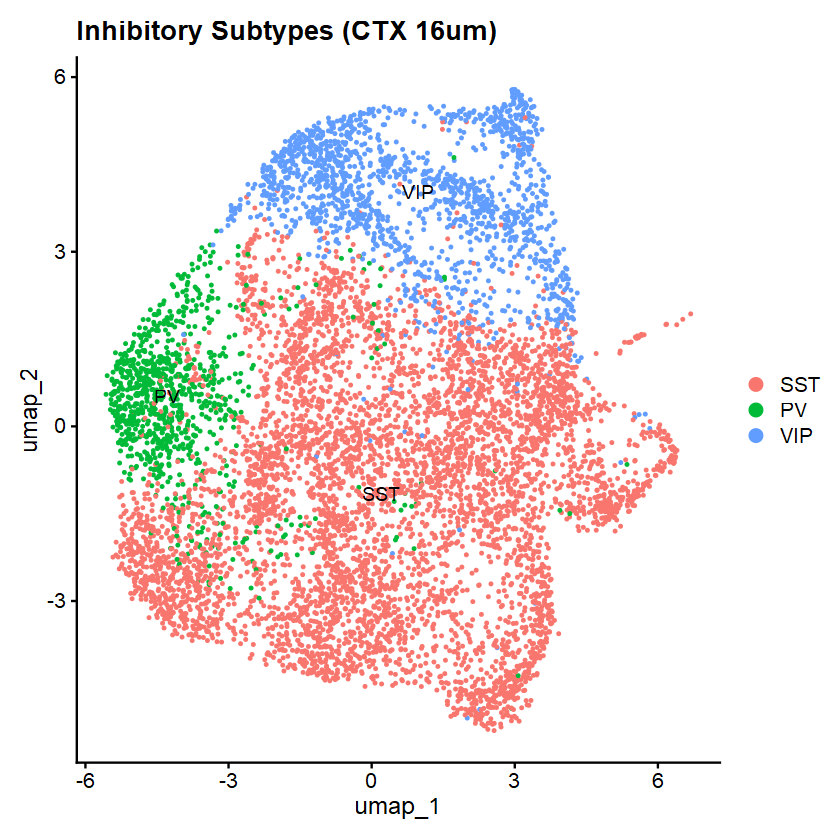

In [28]:
# ================= 5. Subtype Identification (PV, SST, VIP) =================
print("Re-clustering inhibitory neurons...")
DefaultAssay(inhib_obj) <- "Spatial"
inhib_obj <- NormalizeData(inhib_obj)
inhib_obj <- FindVariableFeatures(inhib_obj)
inhib_obj <- ScaleData(inhib_obj)
inhib_obj <- RunPCA(inhib_obj, verbose = FALSE)
inhib_obj <- RunUMAP(inhib_obj, dims = 1:15, verbose = FALSE)
inhib_obj <- FindNeighbors(inhib_obj, dims = 1:15, verbose = FALSE)
inhib_obj <- FindClusters(inhib_obj, resolution = 0.4, verbose = FALSE)

# --- ROBUST ANNOTATION (Fixed 'g' prefix issue) ---
print("Annotating subtypes based on max expression...")

# 1. Calculate average expression per cluster
# AverageExpression returns a matrix where column names might get a 'g' prefix (e.g. g0, g1)
avg_exp <- AverageExpression(inhib_obj, features = c("Pvalb", "Sst", "Vip"), assay = "Spatial")$Spatial

# *** CRITICAL FIX: Clean column names to match Seurat numeric IDs ***
# If columns look like "g0", "g1" but Seurat IDs are "0", "1", remove the "g"
if (all(grepl("^g\\d+$", colnames(avg_exp)))) {
  print("Detected 'g' prefix in cluster names. Removing to match numeric IDs...")
  colnames(avg_exp) <- gsub("^g", "", colnames(avg_exp))
}

# 2. Create mapping table
cluster_map <- data.frame(cluster = colnames(avg_exp), subtype = "Other", stringsAsFactors = FALSE)

for(i in 1:ncol(avg_exp)) {
  col_vals <- avg_exp[, i]
  max_gene <- rownames(avg_exp)[which.max(col_vals)]
  max_val <- max(col_vals)
  
  # Threshold to avoid noise
  if(max_val > 0.1) {
    if(max_gene == "Pvalb") cluster_map$subtype[i] <- "PV"
    if(max_gene == "Sst") cluster_map$subtype[i] <- "SST"
    if(max_gene == "Vip") cluster_map$subtype[i] <- "VIP"
  }
}

print("Cluster Annotation Mapping (Cleaned):")
print(cluster_map)

# 3. Map labels back to cells (Metadata approach)
current_clusters <- as.character(Idents(inhib_obj)) # Convert to char to ensure safe matching
new_labels <- cluster_map$subtype[match(current_clusters, cluster_map$cluster)]

# Check if mapping worked (Debug Step)
if (all(is.na(new_labels))) {
  stop("Error: Annotation mapping failed completely. IDs do not match cluster map.")
}

# 4. Assign new identities
inhib_obj$subtype <- new_labels
Idents(inhib_obj) <- "subtype"

# 5. Keep only identified subtypes
# Check if we actually found any of the targets before subsetting
found_types <- unique(Idents(inhib_obj))
print("Found subtypes:")
print(found_types)

targets <- c("PV", "SST", "VIP")
targets_present <- targets[targets %in% found_types]

if (length(targets_present) == 0) {
  stop("Error: No PV, SST, or VIP cells were identified. Check marker expression levels.")
}

inhib_obj <- subset(inhib_obj, idents = targets_present)
print("Final Cell Counts per Subtype:")
print(table(inhib_obj$subtype))

# UMAP Visualization
p_umap <- DimPlot(inhib_obj, reduction = "umap", label = TRUE) + ggtitle("Inhibitory Subtypes (CTX 16um)")
print(p_umap)
ggsave("Task3_Inhibitory_UMAP_CTX.png", plot = p_umap, width = 6, height = 5)

In [29]:
# ================= 6. DE Analysis (Loosened Criteria) =================
target_subtypes <- c("PV", "SST", "VIP")
diff_markers_list <- list()
logfc_cutoff <- 0.05 

print("Starting subtype-specific DE analysis...")

for (st in target_subtypes) {
  cat(paste0("\nAnalyzing: ", st, " ... \n"))
  sub_obj <- subset(inhib_obj, idents = st)
  
  # Check if both conditions exist
  if (length(unique(sub_obj$condition)) == 2) {
    tryCatch({
      markers <- FindMarkers(sub_obj, 
                             ident.1 = "SMS", 
                             ident.2 = "CTR", 
                             group.by = "condition", 
                             logfc.threshold = logfc_cutoff, 
                             min.pct = 0.05,
                             verbose = FALSE)
      
      if(nrow(markers) > 0) {
        markers$gene <- rownames(markers)
        markers$cell_type <- st
        markers$direction <- ifelse(markers$avg_log2FC > 0, "UP", "DOWN")
        diff_markers_list[[st]] <- markers
        
        # Save CSV
        write.csv(markers, paste0("Task3_DEGs_CTX_", st, ".csv"), row.names = FALSE)
        print(paste("  -> Saved DEGs for", st))
      } else {
        print("  -> No DEGs found.")
      }
    }, error = function(e) { cat("Error: ", e$message, "\n") })
  } else {
    print("  -> Skipping: Missing CTR or SMS condition.")
  }
}

# Consolidate Results
if(length(diff_markers_list) > 0){
    all_sub_markers <- do.call(rbind, diff_markers_list)
    write.csv(all_sub_markers, "Task3_All_Subtype_DEGs_Summary.csv", row.names = FALSE)
} else {
    stop("No DEGs found across any subtype. Lower threshold or check data.")
}

[1] "Starting subtype-specific DE analysis..."

Analyzing: PV ... 


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "  -> Saved DEGs for PV"

Analyzing: SST ... 


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "  -> Saved DEGs for SST"

Analyzing: VIP ... 


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "  -> Saved DEGs for VIP"


[1] "Generating Venn Diagrams..."


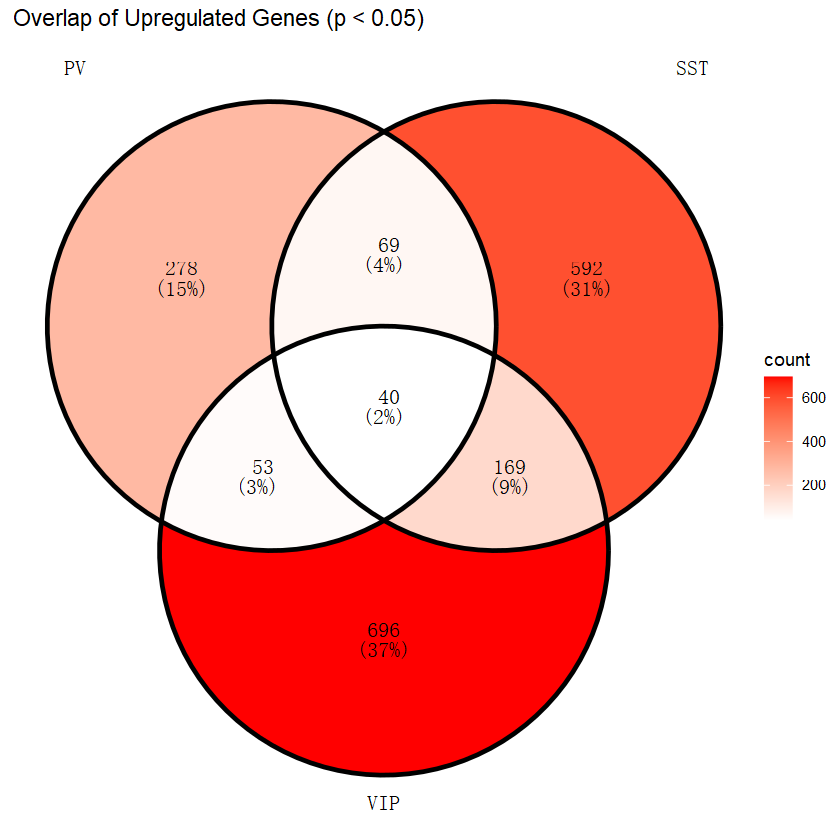

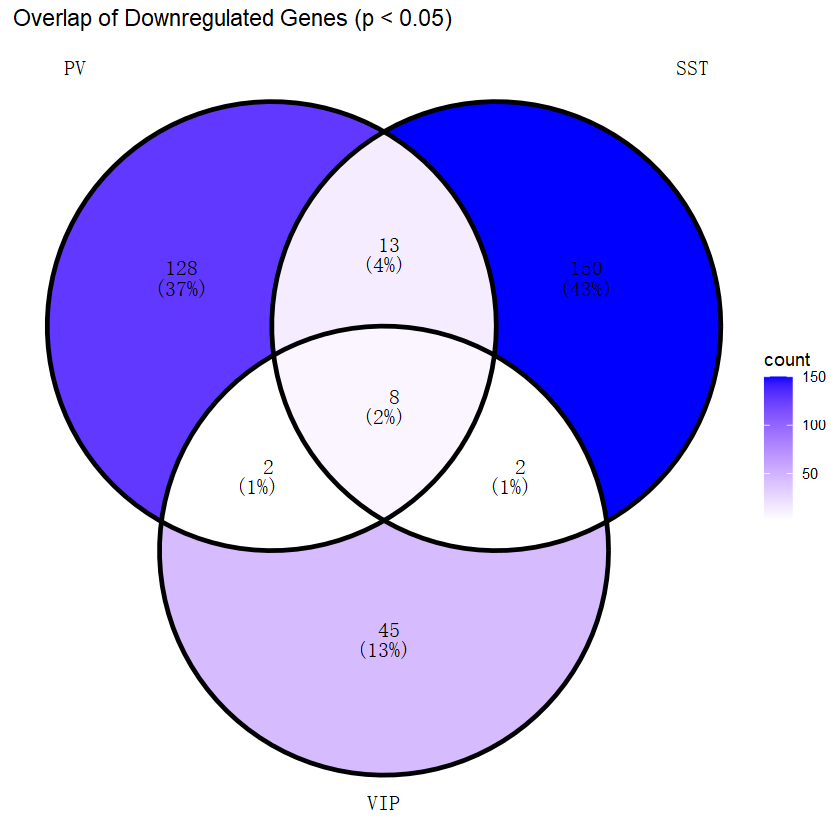

In [30]:
# ================= 7. Venn Diagrams =================
print("Generating Venn Diagrams...")

get_sig_genes <- function(df, type, dir) {
  # Using raw p_val < 0.05 for Venn to show potential overlap even if weak
  return(df$gene[df$cell_type == type & df$direction == dir & df$p_val < 0.05])
}

venn_up <- list(
  PV = get_sig_genes(all_sub_markers, "PV", "UP"),
  SST = get_sig_genes(all_sub_markers, "SST", "UP"),
  VIP = get_sig_genes(all_sub_markers, "VIP", "UP")
)

venn_down <- list(
  PV = get_sig_genes(all_sub_markers, "PV", "DOWN"),
  SST = get_sig_genes(all_sub_markers, "SST", "DOWN"),
  VIP = get_sig_genes(all_sub_markers, "VIP", "DOWN")
)

p_venn_up <- ggVennDiagram(venn_up, label_alpha = 0) + 
             ggtitle("Overlap of Upregulated Genes (p < 0.05)") + 
             scale_fill_gradient(low="white",high="red")
print(p_venn_up)
ggsave("Task3_Venn_UP.png", plot = p_venn_up, width = 6, height = 6)

p_venn_down <- ggVennDiagram(venn_down, label_alpha = 0) + 
               ggtitle("Overlap of Downregulated Genes (p < 0.05)") + 
               scale_fill_gradient(low="white",high="blue")
print(p_venn_down)
ggsave("Task3_Venn_DOWN.png", plot = p_venn_down, width = 6, height = 6)

In [ ]:
# MARK

In [ ]:
# # ================= 8. GO Enrichment =================
# print("Running GO Enrichment...")

# for (st in target_subtypes) {
#   sub_df <- all_sub_markers[all_sub_markers$cell_type == st, ]
  
#   # Up
#   genes_up <- sub_df$gene[sub_df$direction == "UP" & sub_df$p_val < 0.05]
#   if(length(genes_up) >= 5) {
#     ego <- enrichGO(genes_up, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP", pvalueCutoff = 0.05)
#     if(!is.null(ego) && nrow(ego) > 0) {
#       p <- dotplot(ego, showCategory=10) + ggtitle(paste0("GO UP: ", st))
#       print(p)
#       ggsave(paste0("Task3_GO_UP_", st, ".png"), plot = p, width = 8, height = 6)
#     }
#   }
  
#   # Down
#   genes_down <- sub_df$gene[sub_df$direction == "DOWN" & sub_df$p_val < 0.05]
#   if(length(genes_down) >= 5) {
#     ego <- enrichGO(genes_down, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP", pvalueCutoff = 0.05)
#     if(!is.null(ego) && nrow(ego) > 0) {
#       p <- dotplot(ego, showCategory=10) + ggtitle(paste0("GO DOWN: ", st))
#       print(p)
#       ggsave(paste0("Task3_GO_DOWN_", st, ".png"), plot = p, width = 8, height = 6)
#     }
#   }
# }

[1] "Running GO Enrichment..."


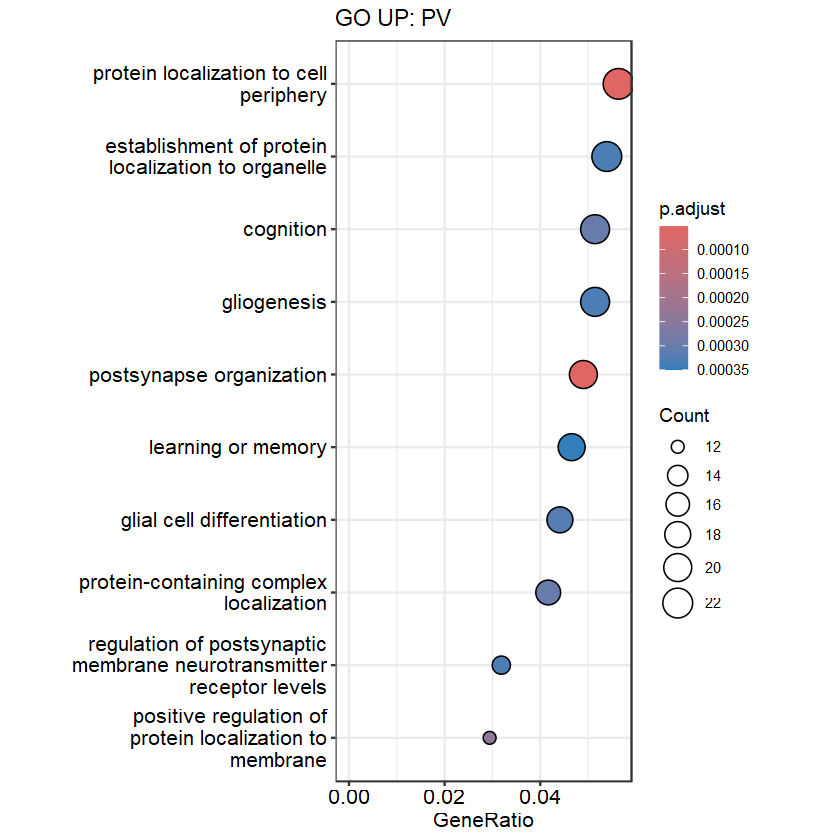

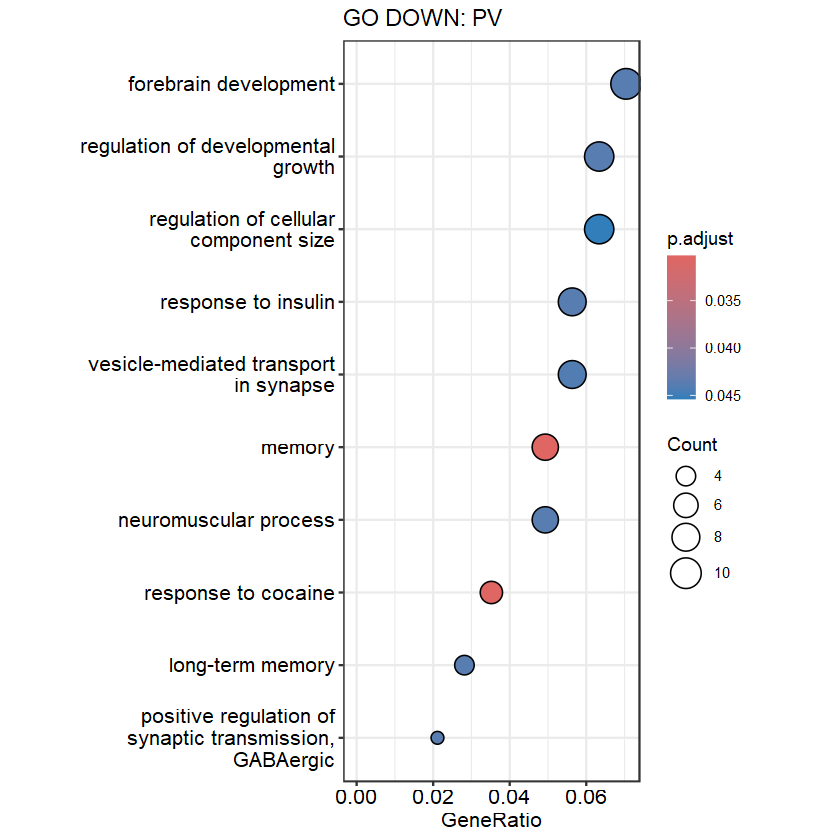

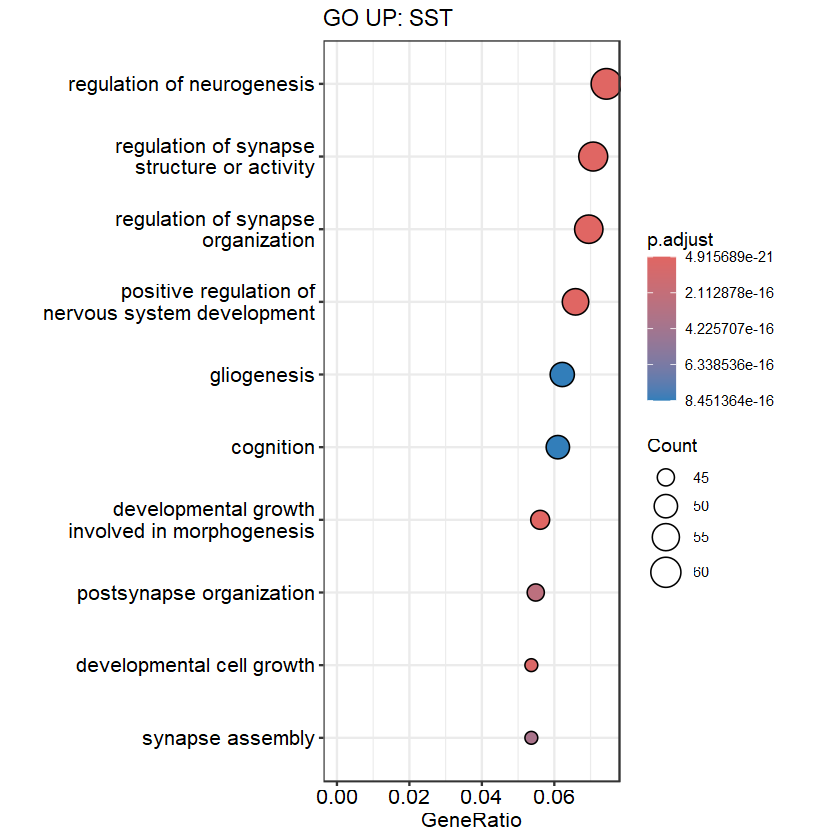

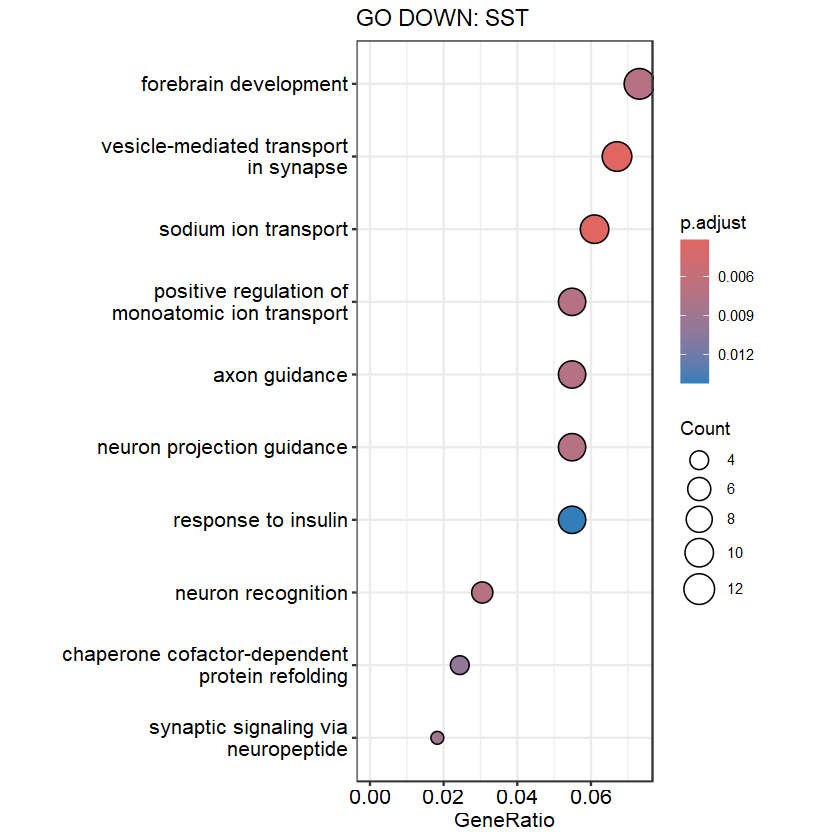

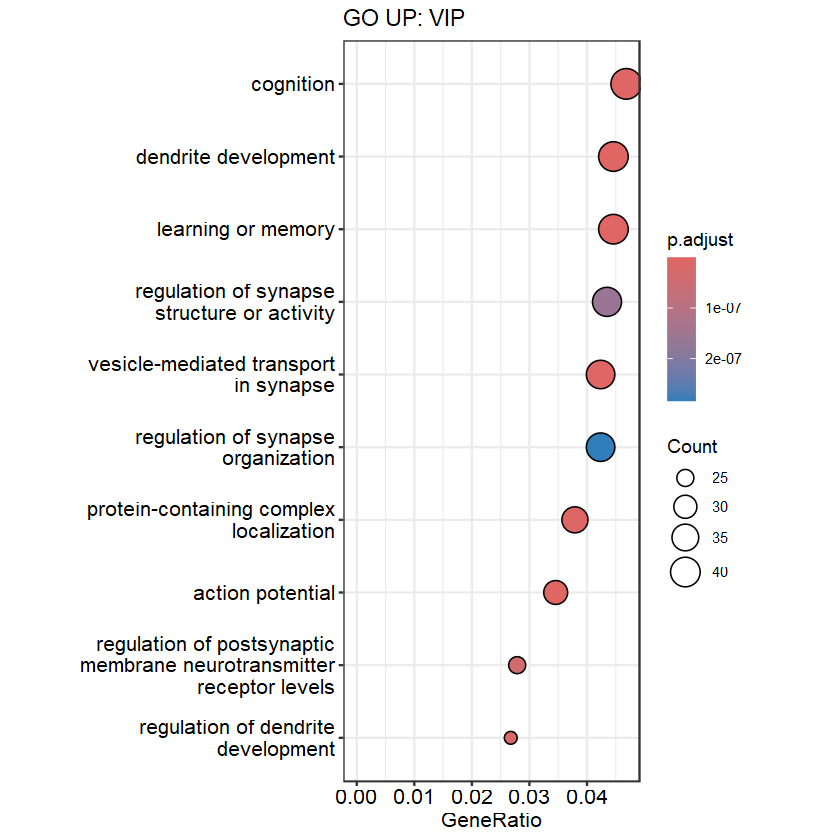

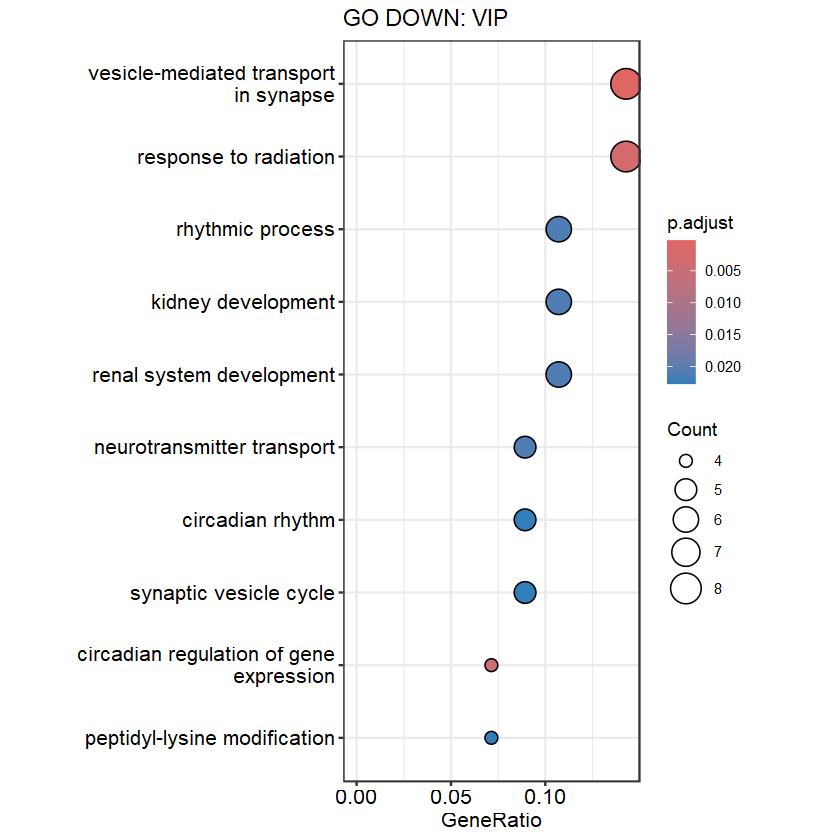

In [31]:
# ================= 8. GO Enrichment =================
print("Running GO Enrichment...")

for (st in target_subtypes) {
  sub_df <- all_sub_markers[all_sub_markers$cell_type == st, ]
  
  # Up markers
  genes_up <- sub_df$gene[sub_df$direction == "UP" & sub_df$p_val < 0.05]
  if(length(genes_up) >= 5) {
    ego <- enrichGO(genes_up, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP", pvalueCutoff = 0.05)
    if(!is.null(ego) && nrow(ego) > 0) {
      p <- dotplot(ego, showCategory=10) + 
           ggtitle(paste0("GO UP: ", st)) +
           # Anchor X-axis to 0 to pull dots to the left
           scale_x_continuous(limits = c(0, NA)) + 
           # Lock aspect ratio to make it tall and narrow
           theme(aspect.ratio = 2.5)
           
      print(p)
      
      # Shrink width and increase height to physically compress the X-axis
      ggsave(paste0("Task3_GO_UP_", st, ".png"), plot = p, width = 5, height = 7)
    }
  }
  
  # Down markers
  genes_down <- sub_df$gene[sub_df$direction == "DOWN" & sub_df$p_val < 0.05]
  if(length(genes_down) >= 5) {
    ego <- enrichGO(genes_down, OrgDb = org.Mm.eg.db, keyType = "SYMBOL", ont = "BP", pvalueCutoff = 0.05)
    if(!is.null(ego) && nrow(ego) > 0) {
      p <- dotplot(ego, showCategory=10) + 
           ggtitle(paste0("GO DOWN: ", st)) +
           # Anchor X-axis to 0 to pull dots to the left
           scale_x_continuous(limits = c(0, NA)) + 
           # Lock aspect ratio to make it tall and narrow
           theme(aspect.ratio = 2.5)
           
      print(p)
      
      # Shrink width and increase height to physically compress the X-axis
      ggsave(paste0("Task3_GO_DOWN_", st, ".png"), plot = p, width = 5, height = 7)
    }
  }
}

[1] "Generating Volcano Plots..."


Warning message:
"Removed 6221 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 6221 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 4468 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 4468 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


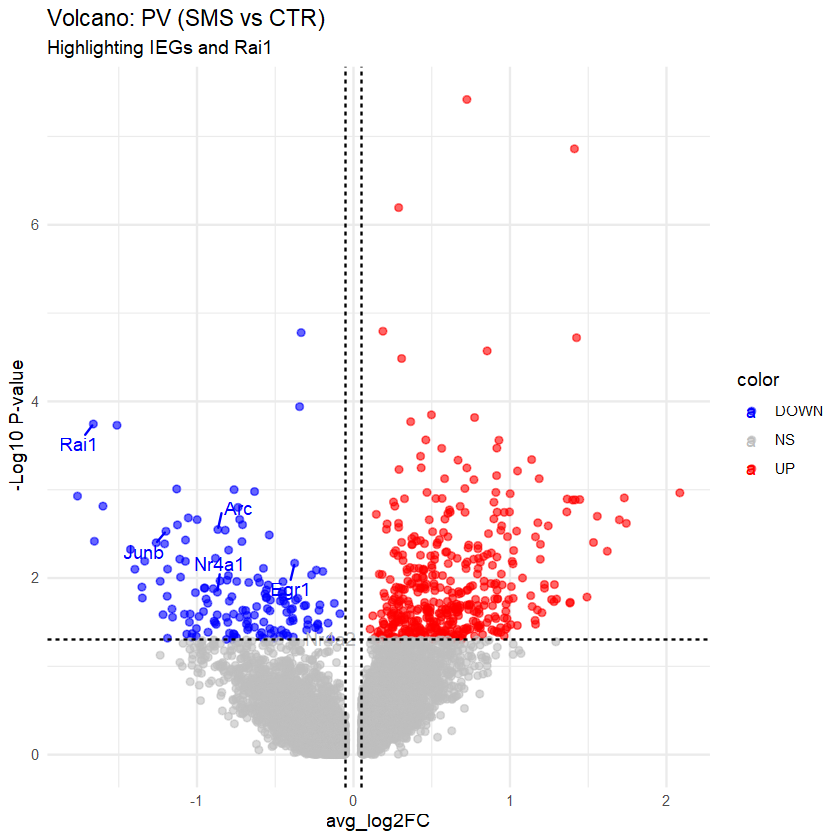

Warning message:
"Removed 5735 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 5735 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


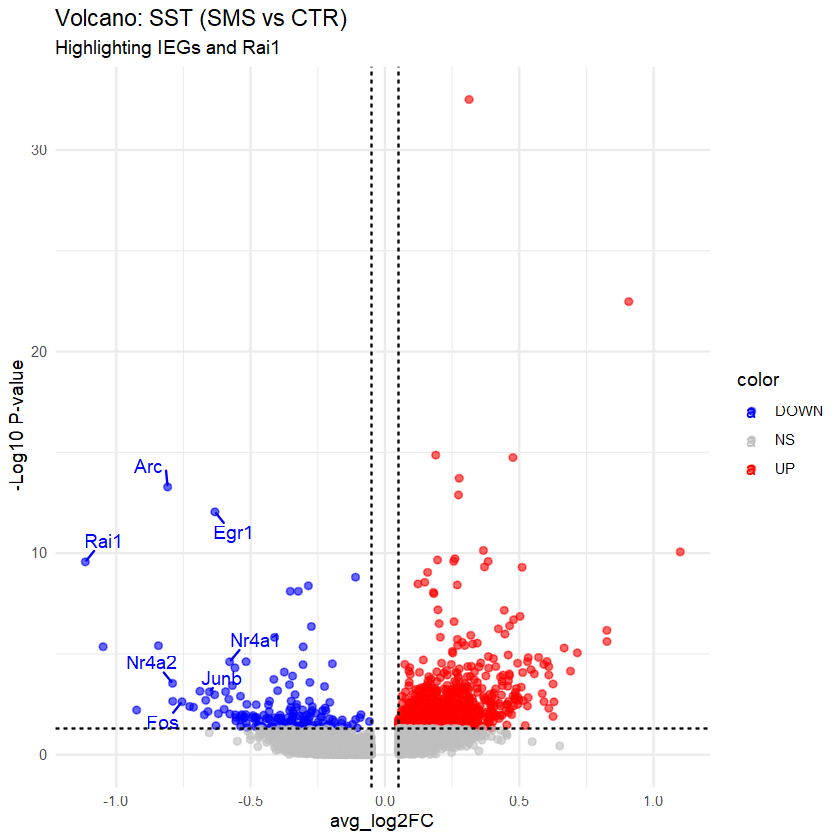

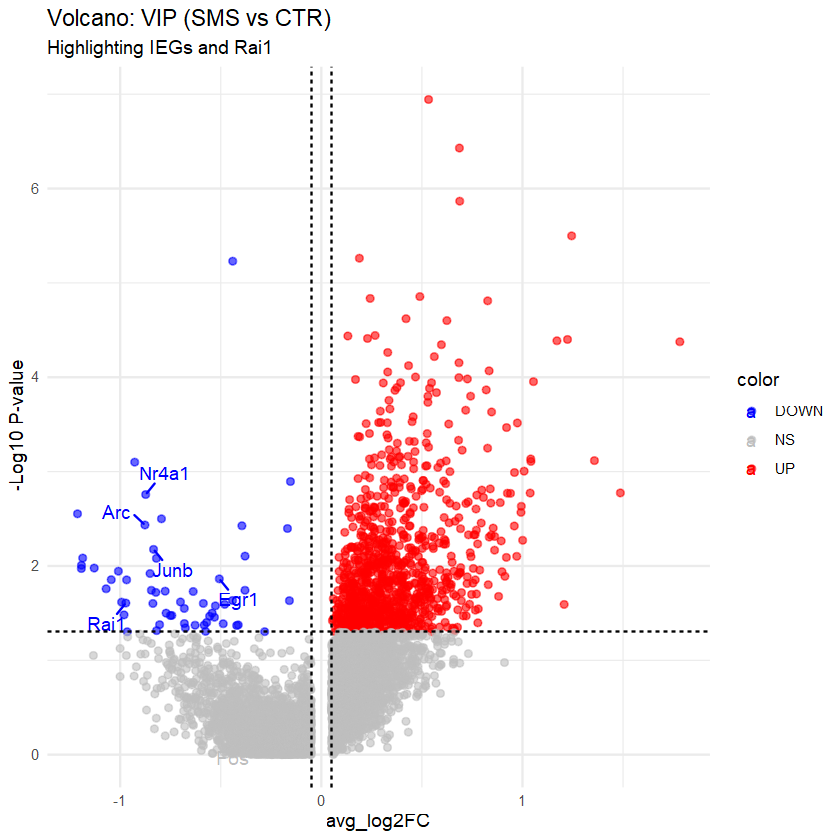

In [32]:
# ================= 9. Volcano Plots (Highlight IEGs & Rai1) =================
print("Generating Volcano Plots...")

# Genes of interest to label
iegs <- c("Fos", "Junb", "Fosl2", "Egr1", "Egr2", "Nr4a1", "Nr4a2", "Nr4a3", "Arc", "Dusp5", "Rai1")

for (st in target_subtypes) {
  df <- all_sub_markers[all_sub_markers$cell_type == st, ]
  
  # Determine color status
  df$color <- "NS"
  df$color[df$avg_log2FC > 0.05 & df$p_val < 0.05] <- "UP"
  df$color[df$avg_log2FC < -0.05 & df$p_val < 0.05] <- "DOWN"
  
  # Label Logic
  df$label <- NA
  genes_to_label <- intersect(df$gene, iegs)
  df$label[df$gene %in% genes_to_label] <- df$gene[df$gene %in% genes_to_label]
  
  p_vol <- ggplot(df, aes(x = avg_log2FC, y = -log10(p_val), color = color, label = label)) +
    geom_point(alpha = 0.6, size = 1.5) +
    scale_color_manual(values = c("DOWN" = "blue", "NS" = "grey", "UP" = "red")) +
    geom_text_repel(max.overlaps = 50, box.padding = 0.5, force = 2, min.segment.length = 0) +
    geom_vline(xintercept = c(-0.05, 0.05), linetype = "dashed") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed") +
    theme_minimal() +
    labs(title = paste0("Volcano: ", st, " (SMS vs CTR)"),
         subtitle = "Highlighting IEGs and Rai1",
         y = "-Log10 P-value")
  
  print(p_vol)
  ggsave(paste0("Task3_Volcano_", st, ".png"), plot = p_vol, width = 8, height = 6)
}

[1] "Generating Final Dot Plot..."


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


[1] "Task 3 Complete."


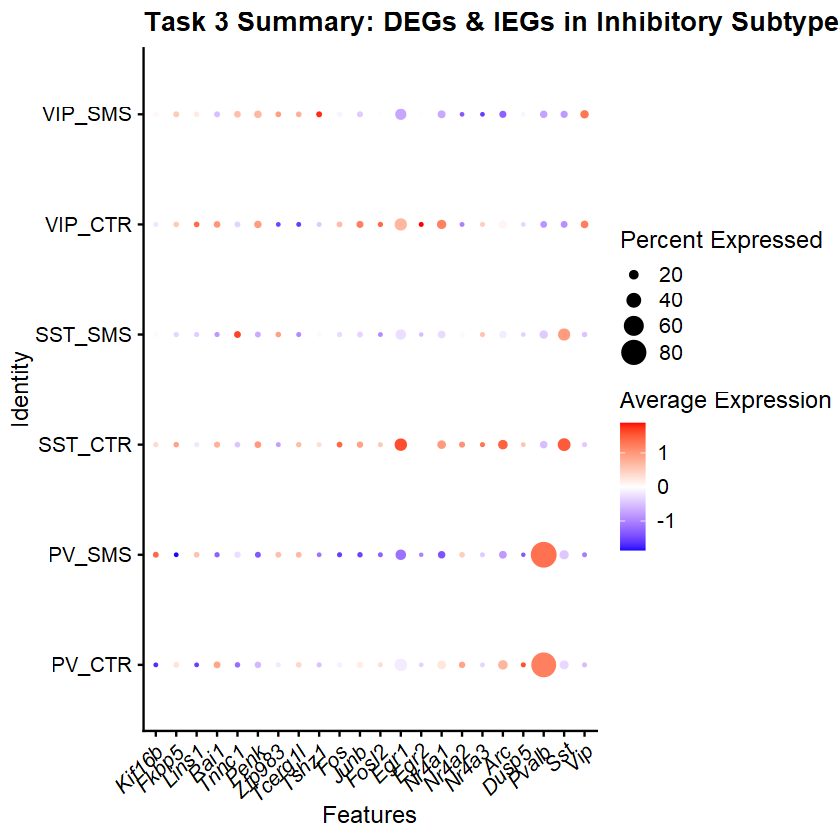

In [33]:
# ================= 10. Final Summary Dot Plot =================
print("Generating Final Dot Plot...")

# Select Top 3 DEGs per type
top_genes <- all_sub_markers %>% 
  group_by(cell_type) %>% 
  slice_max(order_by = abs(avg_log2FC), n = 3, with_ties = FALSE) %>% 
  pull(gene)

# Combine with markers and IEGs
final_features <- unique(c(top_genes, iegs, "Pvalb", "Sst", "Vip"))

# Order X axis for plotting
inhib_obj$cell_condition <- paste(Idents(inhib_obj), inhib_obj$condition, sep = "_")
Idents(inhib_obj) <- "cell_condition"

# Define ideal order
levels_order <- c("PV_CTR", "PV_SMS", "SST_CTR", "SST_SMS", "VIP_CTR", "VIP_SMS")
# Filter to keep only existing levels
levels_order <- levels_order[levels_order %in% unique(Idents(inhib_obj))]
Idents(inhib_obj) <- factor(Idents(inhib_obj), levels = levels_order)

p_final_dot <- DotPlot(inhib_obj, features = final_features) + 
  RotatedAxis() +
  ggtitle("Task 3 Summary: DEGs & IEGs in Inhibitory Subtypes") +
  scale_color_gradient2(low = "blue", mid = "white", high = "red") +
  theme(axis.text.x = element_text(face = "italic"))

print(p_final_dot)
ggsave("Task3_Final_DotPlot_Summary.png", plot = p_final_dot, width = 12, height = 6)

print("Task 3 Complete.")

# Task3_newnew_20260120

In [ ]:
# replace sec 9 

[1] "Generating Updated Volcano Plots with Specific Upregulated Genes..."


Warning message:
"Removed 6217 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 6217 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 4464 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 4464 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


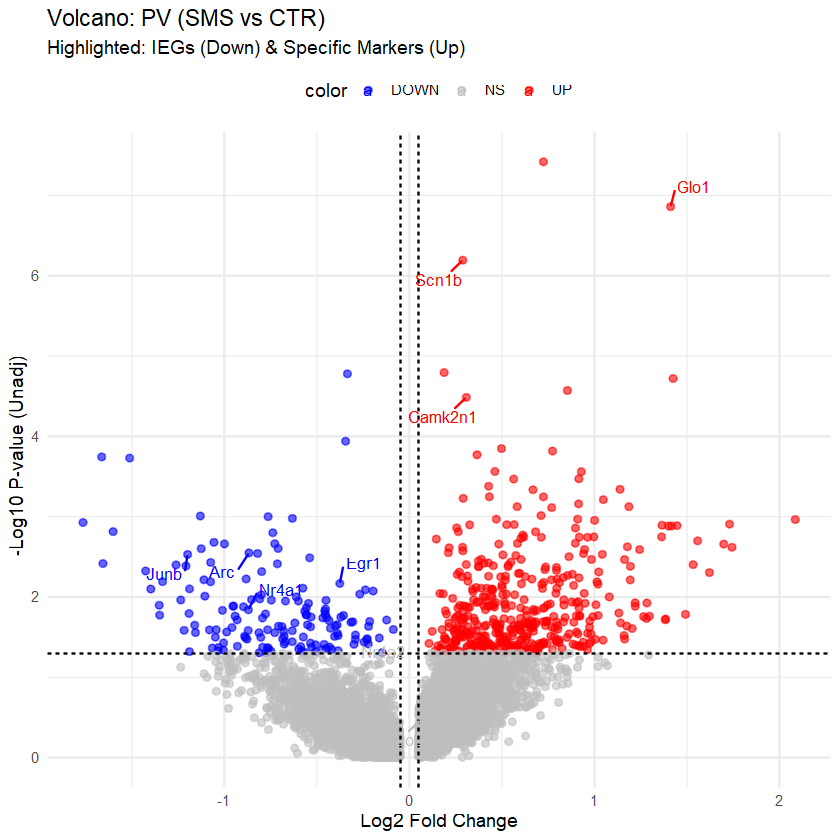

Warning message:
"Removed 5731 rows containing missing values or values outside the scale range (`geom_text_repel()`)."
Warning message:
"Removed 5731 rows containing missing values or values outside the scale range (`geom_text_repel()`)."


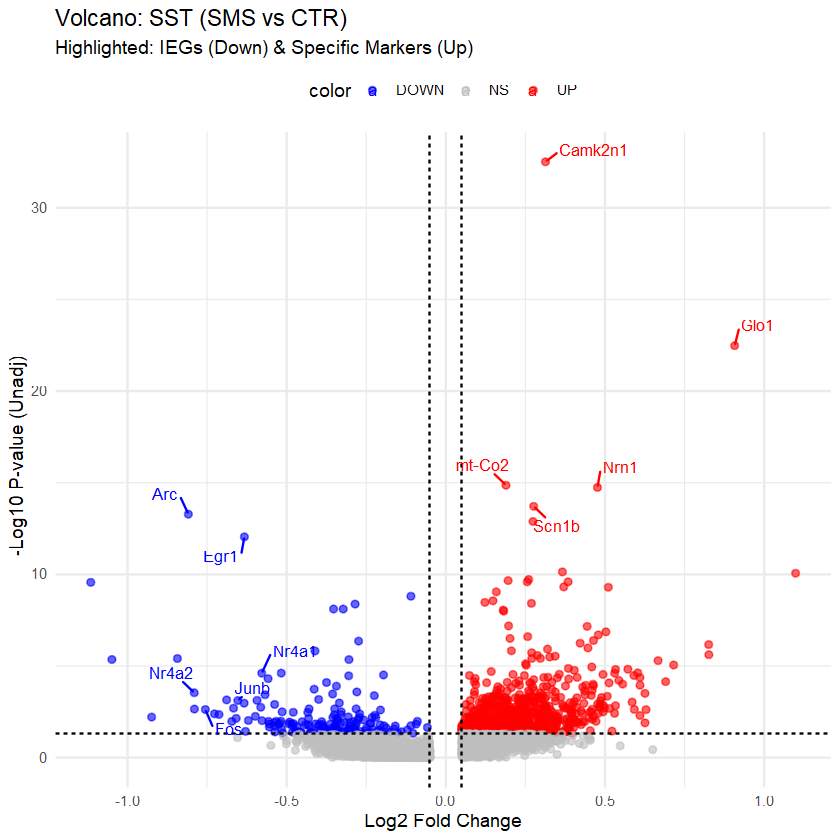

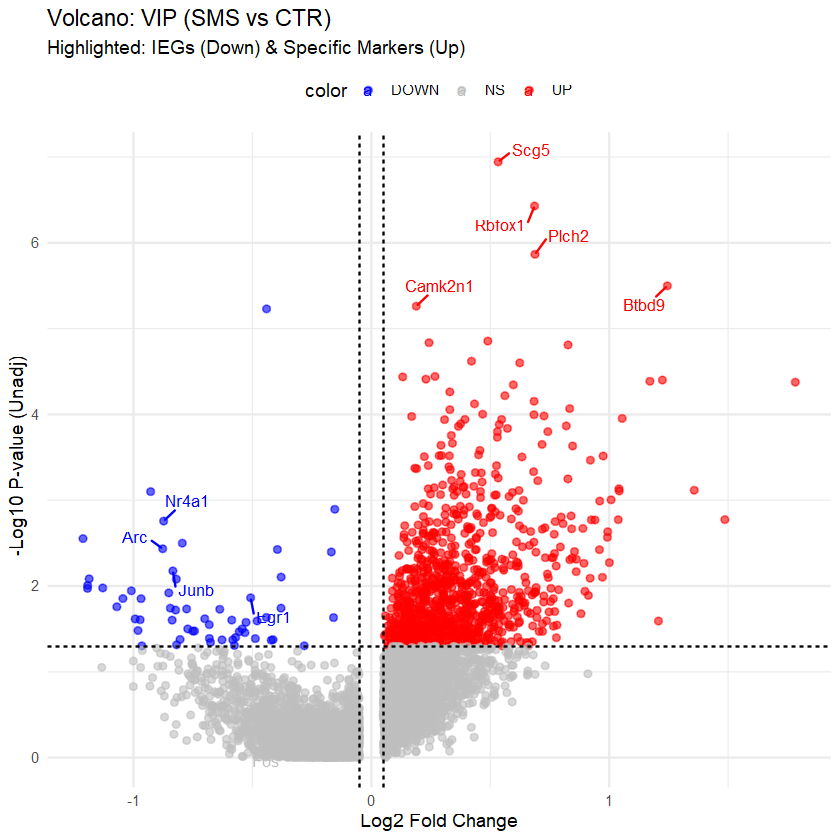

In [34]:
# ================= Task 3 Updated: Volcano Plots with UP/DOWN Highlights =================
library(ggplot2)
library(ggrepel)
library(dplyr)

print("Generating Updated Volcano Plots with Specific Upregulated Genes...")

# 1. Define Gene Lists
# Downregulated (IEGs from previous request)
genes_down_core <- c("Fos", "Junb", "Fosl2", "Egr1", "Egr2", "Nr4a1", "Nr4a2", "Nr4a3", "Arc", "Dusp5")

# Upregulated (New request)
genes_up_list <- list(
  VIP = c("Scg5", "Rbfox1", "Plch2", "Btbd9", "Camk2n1"),
  SST = c("Camk2n1", "Glo1", "mt-Co2", "Nrn1", "Scn1b"),
  PV  = c("Glo1", "mt-Co2", "Scn1b", "Camk2n1", "Nrn1")
)

# 2. Loop through subtypes to plot
target_subtypes <- c("PV", "SST", "VIP")

for (st in target_subtypes) {
  # Filter data for current subtype
  df <- all_sub_markers[all_sub_markers$cell_type == st, ]
  
  # Determine colors based on thresholds
  # Note: Using p_val < 0.05 (unadjusted) for visualization trends as discussed
  df$color <- "NS"
  df$color[df$avg_log2FC > 0.05 & df$p_val < 0.05] <- "UP"
  df$color[df$avg_log2FC < -0.05 & df$p_val < 0.05] <- "DOWN"
  
  # Create Label Column
  df$label <- NA
  
  # Label Logic:
  # 1. Label Core Downregulated Genes (IEGs)
  down_hits <- intersect(df$gene, genes_down_core)
  df$label[df$gene %in% down_hits] <- df$gene[df$gene %in% down_hits]
  
  # 2. Label Specific Upregulated Genes for this subtype
  up_targets <- genes_up_list[[st]]
  up_hits <- intersect(df$gene, up_targets)
  df$label[df$gene %in% up_hits] <- df$gene[df$gene %in% up_hits]
  
  # Plot
  p_vol <- ggplot(df, aes(x = avg_log2FC, y = -log10(p_val), color = color, label = label)) +
    geom_point(alpha = 0.6, size = 1.5) +
    scale_color_manual(values = c("DOWN" = "blue", "NS" = "grey", "UP" = "red")) +
    geom_vline(xintercept = c(-0.05, 0.05), linetype = "dashed", color = "black") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "black") +
    # ggrepel handles text placement
    geom_text_repel(max.overlaps = 100, box.padding = 0.5, force = 2, min.segment.length = 0, size = 3.5) +
    theme_minimal() +
    labs(title = paste0("Volcano: ", st, " (SMS vs CTR)"),
         subtitle = paste0("Highlighted: IEGs (Down) & Specific Markers (Up)"),
         y = "-Log10 P-value (Unadj)",
         x = "Log2 Fold Change") +
    theme(legend.position = "top")
  
  print(p_vol)
  ggsave(paste0("Task3_Volcano_Updated_", st, ".png"), plot = p_vol, width = 8, height = 7)
}

In [ ]:
# 2026/02/11
# "There is some overlap in the clusters and they are not entirely distinct (although it's quite a small overlap). Is there a way to improve the clustering?

# This must be the UMAP for the CTR data. Can we also have a UMAP for the SMS data so we I can show them next to each other in the paper"

[1] "Optimizing UMAP layout for better separation..."


Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
08:49:24 UMAP embedding parameters a = 0.4361 b = 1.447

08:49:24 Read 8158 rows and found 30 numeric columns

08:49:24 Using Annoy for neighbor search, n_neighbors = 30

08:49:24 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

08:49:25 Writing NN index file to temp file C:\Users\woshi\AppData\Local\Temp\Rtmpq64gBj\file851c6c4e2040

08:49:25 Searching Annoy index using 1 thread, search_k = 3000

08:49:26 Annoy recall = 100%

08:49:27 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

08:49:29 Initializing from normalized Laplacian + noise (using RSpectra)

08:49:29

[1] "Saved optimized split UMAP."


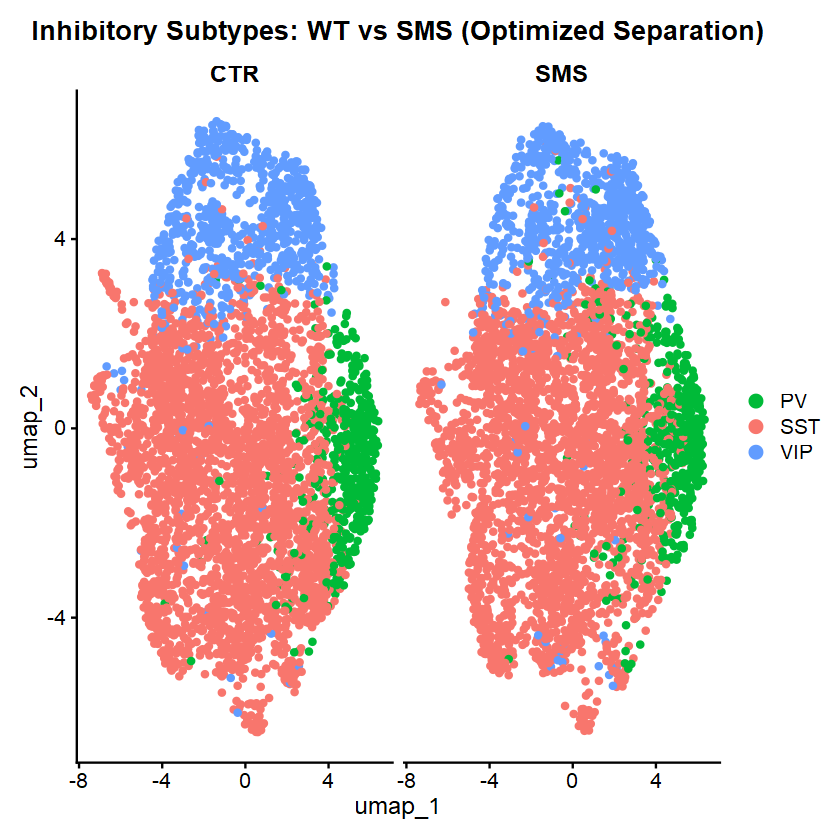

In [35]:
# ================= Task 3 Update: Improved Clustering & Split View =================
library(Seurat)
library(ggplot2)

print("Optimizing UMAP layout for better separation...")

# 1. Re-process the Inhibitory subset
# Crucial step: We need to calculate variance specific to this subset rather than relying on global variance.
# This usually yields much cleaner and more distinct clustering.
DefaultAssay(inhib_obj) <- "Spatial"
inhib_obj <- FindVariableFeatures(inhib_obj, selection.method = "vst", nfeatures = 2000)
inhib_obj <- ScaleData(inhib_obj)
inhib_obj <- RunPCA(inhib_obj, verbose = FALSE)

# 2. Run optimized UMAP (Fine-tuning parameters)
# min.dist: Default is 0.3. Increasing it to 0.6 pushes clusters further apart (Less overlap)
# spread: Controls the overall scale/spread of the embedding
inhib_obj <- RunUMAP(inhib_obj, dims = 1:30, min.dist = 0.6, spread = 1.0)

# 3. Plotting: Side-by-Side view
# split.by = "condition" automatically ensures the axes and scales are identical across both panels
p_inhib_split <- DimPlot(inhib_obj, reduction = "umap", 
                         split.by = "condition",  # Key parameter: splits into CTR and SMS panels
                         group.by = "subtype",    # Color points by subtype
                         pt.size = 1.2,           # Slightly increase point size for visibility
                         cols = c("SST"="#F8766D", "PV"="#00BA38", "VIP"="#619CFF")) + # Maintain the original RGB palette
  ggtitle("Inhibitory Subtypes: WT vs SMS (Optimized Separation)") +
  theme(
    strip.text = element_text(size = 14, face = "bold"), # Adjust the size of the CTR/SMS facet headers
    legend.position = "right"
  )

print(p_inhib_split)
ggsave("Task3_Inhibitory_UMAP_Split_Optimized.png", plot = p_inhib_split, width = 12, height = 6)

print("Saved optimized split UMAP.")

# Task4 New

In [36]:
# ================= 1. Environment & Paths =================
# Set paths to square_016um (Most reliable source with coords)
path_ctr_root <- "F:\\H.M.打火机\\Huang_Minza__Ctr_1_A1\\square_016um"
path_sms_root <- "F:\\H.M.打火机\\Huang_Minza__SMS_1_D1\\square_016um"
ref_path_matrix <- "F:\\H.M.打火机\\Task2\\DataFromPaper\\GSE124952_expression_matrix.csv.gz"
ref_path_meta <- "F:\\H.M.打火机\\Task2\\DataFromPaper\\GSE124952_meta_data.csv.gz"

# Load Libraries
packages <- c("Seurat", "CellChat", "dplyr", "patchwork", "ggplot2", "hdf5r", "ComplexHeatmap")
for (pkg in packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) install.packages(pkg)
}

library(Seurat)
library(CellChat)
library(dplyr)
library(patchwork)
library(ggplot2)
library(ComplexHeatmap)

Registered S3 method overwritten by 'ggnetwork':
  method         from  
  fortify.igraph ggtree

Loading required package: igraph

Warning message:
"package 'igraph' was built under R version 4.4.3"

Attaching package: 'igraph'


The following objects are masked from 'package:future':

    %->%, %<-%


The following object is masked from 'package:IRanges':

    union


The following object is masked from 'package:S4Vectors':

    union


The following objects are masked from 'package:BiocGenerics':

    normalize, path, union


The following object is masked from 'package:clusterProfiler':

    simplify


The following objects are masked from 'package:dplyr':

    as_data_frame, groups, union


The following object is masked from 'package:Seurat':

    components


The following objects are masked from 'package:stats':

    decompose, spectrum


The following object is masked from 'package:base':

    union


Loading required package: grid

ComplexHeatmap version 2.22.0
Bioconductor p

In [37]:
# ================= 2. Helper Functions (Load & Crop) =================

# 2.1 Robust Loading
load_hd_data_correctly <- function(data_dir, sample_id) {
  possible_names <- c("filtered_feature_bc_matrix.h5", "filtered_feature_cell_matrix.h5")
  found_file <- possible_names[file.exists(file.path(data_dir, possible_names))][1]
  
  if (is.na(found_file)) stop(paste("Error: No H5 matrix found in", data_dir))
  
  print(paste("Loading Spatial Data from:", data_dir))
  tryCatch({
    obj <- Load10X_Spatial(data.dir = data_dir, filename = found_file, filter.matrix = FALSE)
    obj$condition <- sample_id
    obj$orig.ident <- sample_id
    return(obj)
  }, error = function(e) { stop(paste("Load failed:", e$message)) })
}

# 2.2 Task 1 Coordinates (Finalized)
subset_by_coords <- function(obj, boxes) {
  coords <- GetTissueCoordinates(obj)
  x_col <- grep("col|x", colnames(coords), value = TRUE)[1]
  y_col <- grep("row|y", colnames(coords), value = TRUE)[1]
  
  cells_to_keep <- c()
  for (i in 1:nrow(boxes)) {
    ids <- rownames(coords[coords[[x_col]] >= boxes$xmin[i] & coords[[x_col]] <= boxes$xmax[i] &
                           coords[[y_col]] >= boxes$ymin[i] & coords[[y_col]] <= boxes$ymax[i], ])
    cells_to_keep <- c(cells_to_keep, ids)
  }
  return(subset(obj, cells = unique(cells_to_keep)))
}

ctr_boxes <- data.frame(xmin = c(4000, 15500), xmax = c(14500, 27500), ymin = c(7000, 6000), ymax = c(17500, 16500))
sms_boxes <- data.frame(xmin = c(15000, 2000), xmax = c(26000, 14500), ymin = c(10000, 12500), ymax = c(19500, 21500))

In [38]:
# ================= 3. Preparation: Load, Crop & Annotate =================
print("Step 3: Loading and Cropping Data to CTX Only...")

# Load & Crop
ctr_obj <- load_hd_data_correctly(path_ctr_root, "CTR")
ctr_obj <- subset_by_coords(ctr_obj, ctr_boxes)

sms_obj <- load_hd_data_correctly(path_sms_root, "SMS")
sms_obj <- subset_by_coords(sms_obj, sms_boxes)

# Merge
combined_data <- merge(ctr_obj, y = sms_obj, add.cell.ids = c("CTR", "SMS"))
combined_data <- JoinLayers(combined_data)

# Process for Label Transfer
DefaultAssay(combined_data) <- "Spatial"
combined_data <- NormalizeData(combined_data) %>% FindVariableFeatures() %>% ScaleData() %>% RunPCA()

# --- Label Transfer (Using Reference) ---
print("Loading Reference Atlas for Annotation...")
ref_counts <- read.csv(ref_path_matrix, row.names = 1, check.names = FALSE)
ref_meta <- read.csv(ref_path_meta, row.names = 1)
ref_obj <- CreateSeuratObject(counts = ref_counts, meta.data = ref_meta)
Idents(ref_obj) <- ref_obj$CellType
ref_obj <- NormalizeData(ref_obj) %>% FindVariableFeatures() %>% ScaleData() %>% RunPCA() %>% RunUMAP(dims=1:30)

print("Transferring Labels to CTX data...")
anchors <- FindTransferAnchors(reference = ref_obj, query = combined_data, normalization.method = "LogNormalize")
predictions <- TransferData(anchorset = anchors, refdata = ref_obj$CellType, dims = 1:30)
combined_data$predicted_celltype <- predictions$predicted.id

print("Cell Types identified:")
print(table(combined_data$predicted_celltype))

# Split back to CTR and SMS with labels
Idents(combined_data) <- "condition"
ctr_obj <- subset(combined_data, idents = "CTR")
sms_obj <- subset(combined_data, idents = "SMS")

[1] "Step 3: Loading and Cropping Data to CTX Only..."
[1] "Loading Spatial Data from: F:\\H.M.打火机\\Huang_Minza__Ctr_1_A1\\square_016um"


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


[1] "Loading Spatial Data from: F:\\H.M.打火机\\Huang_Minza__SMS_1_D1\\square_016um"


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Key 'slice1_' taken, using 'slice12_' instead"
Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Snap25, Uchl1, Snhg11, Atp6v1b2, Ywhah, Stxbp1, Syp, Dnm1, Ptk2b, Rtn1 
	   Calm2, Nrgn, Ncdn, Ppp3r1, Ndrg4, App, Syt1, Syn1, Slc17a7, Serinc1 
	   Ndfip1, Stmn1, Atp1b1, Rtn4, Olfm1, Sncb, Ptprn, Map1b, Thy1, Atp2b1 
Negative:  Ptgds, Apoe, Apod, Gfap, Atp1a2, Igf2, Mobp, Mgp, Cldn11, Plp1 
	   Vim, Ahnak, Mbp, Col1a2, Id3, Timp3, Fn1, Mal, Aqp4, Col1a1 
	   Slc1a3, Slc6a20a, A

[1] "Loading Reference Atlas for Annotation..."


Warning message:
"Data is of class data.frame. Coercing to dgCMatrix."
Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  Stmn3, Sncb, Rtn1, Snap25, Syt1, Atp6v1g2, Mllt11, Snhg11, Vsnl1, Rab3a 
	   Celf4, Tubb3, Zwint, Mtap1b, Thy1, Chn1, Tagln3, Stmn2, Snca, Gap43 
	   Zcchc18, Tuba4a, Ctxn1, Snap47, Sult4a1, Atp6v1b2, Olfm1, Mdh1, Got1, Tmem59l 
Negative:  Sepp1, Myl12a, Fos, Flt1, Sparc, Id1, Ly6c1, Ly6a, Id3, Itm2a 
	   Ifitm3, Pltp, Cldn5, Arpc1b, Slc2a1, Slco1a4, Gng11, Gng5, Esam, Pglyrp1 
	   Epas1, Klf4, Fcgrt, Btg2, Ptprb, Klf2, Ramp2, Anxa3, Srgn, Slco1c1 
PC_ 2 
Positive:  Spock2, Tmsb10, Bsg, Egfl7, Ldha, Ablim1, 9430020K01Rik, Car4, Flt1, Ly6c1 
	   Rgs4, Ly6a, Cldn5, Pltp, Itm2a, Esam, Slco1a4, Ptprb, Pglyrp1, Uchl1 
	   Rgs5, Gpr116, Id1, Tm4sf1, Stmn2, Cd34, Abcb1a, Slc6a6, Fn1, Ifitm3 
Negative:  Tsc22d4, Cd9, Phgdh, Trf, Evi2a, Cnp, Cmtm5, Cd81, Cd63, Plp1 
	   Mag, Lgmn, Cldn11, Psat1, Ctss, C

[1] "Transferring Labels to CTX data..."


Performing PCA on the provided reference using 1761 features as input.

Projecting cell embeddings

Finding neighborhoods

Finding anchors

	Found 6379 anchors

Finding integration vectors

Finding integration vector weights

Predicting cell labels



[1] "Cell Types identified:"

     Astro       Endo Excitatory Inhibitory  Microglia   NF Oligo      Oligo 
      7803       4090      81925       8534        538        705       3697 
       OPC 
       686 


Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Seurat objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating Centroids objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating FOV objects"
Warning message:
"Not validating Seurat objects"


In [41]:
# ================= 4. CellChat Processing =================
create_cellchat_object <- function(seurat_obj, group_name) {
  print(paste("Processing CellChat for:", group_name))
  
  # Prepare Input
  data.input <- GetAssayData(seurat_obj, assay = "Spatial", layer = "data")
  meta <- seurat_obj@meta.data
  
  # Create Object
  cellchat <- createCellChat(object = data.input, meta = meta, group.by = "predicted_celltype")
  cellchat@DB <- CellChatDB.mouse
  
  # Process
  cellchat <- subsetData(cellchat)
  cellchat <- identifyOverExpressedGenes(cellchat)
  cellchat <- identifyOverExpressedInteractions(cellchat)
  
  # Compute Probabilities (Standard scRNA-seq mode is robust for high-res Visium)
  cellchat <- computeCommunProb(cellchat, type = "triMean")
  cellchat <- filterCommunication(cellchat, min.cells = 10)
  cellchat <- computeCommunProbPathway(cellchat)
  cellchat <- aggregateNet(cellchat)
  
  return(cellchat)
}

print("Running CellChat pipelines...")
cc_ctr <- create_cellchat_object(ctr_obj, "CTR")
cc_sms <- create_cellchat_object(sms_obj, "SMS")

# Merge for comparison
object.list <- list(CTR = cc_ctr, SMS = cc_sms)
cellchat_merged <- mergeCellChat(object.list, add.names = names(object.list))

[1] "Running CellChat pipelines..."
[1] "Processing CellChat for: CTR"
[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  Astro Endo Excitatory Inhibitory Microglia NF Oligo Oligo OPC 
Issue identified!! Please check the official Gene Symbol of the following genes:  
 H2-BI H2-Ea-ps 
triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2026-02-24 09:14:54.696743]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2026-02-24 09:23:25.887551]"
[1] "Processing CellChat for: SMS"
[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  Astro Endo Excitatory Inhibitory Microglia NF Oligo Oligo OPC 
Issue identified!! Please check the official Gene Symbol of the following genes:  
 H2-BI H

Merge the following slots: 'data.signaling','images','net', 'netP','meta', 'idents', 'var.features' , 'DB', and 'LR'.



[1] "Generating Overall Statistics..."


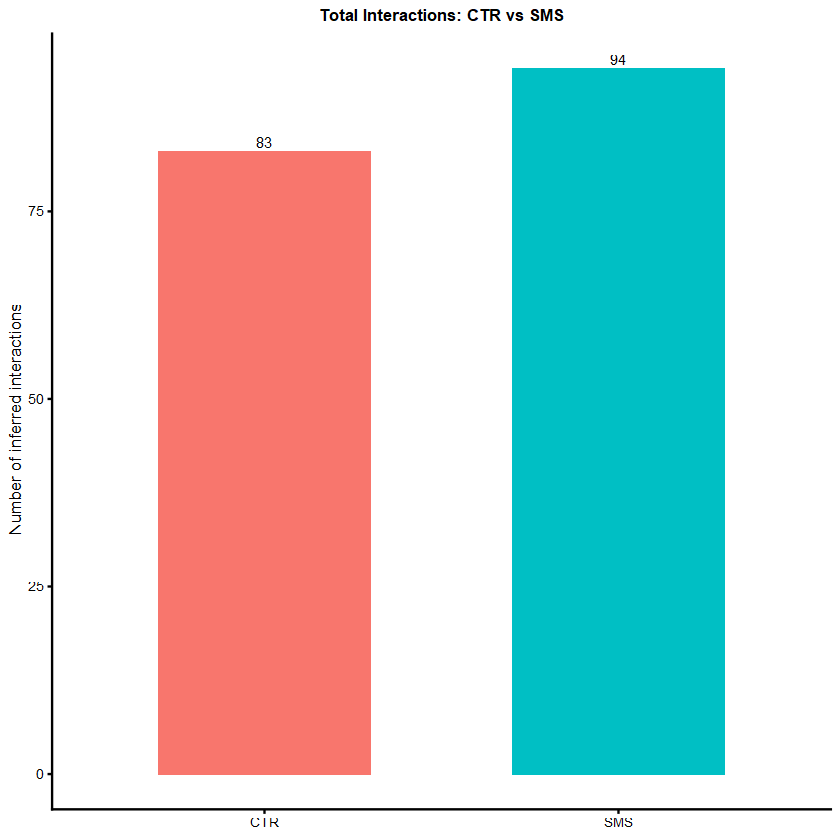

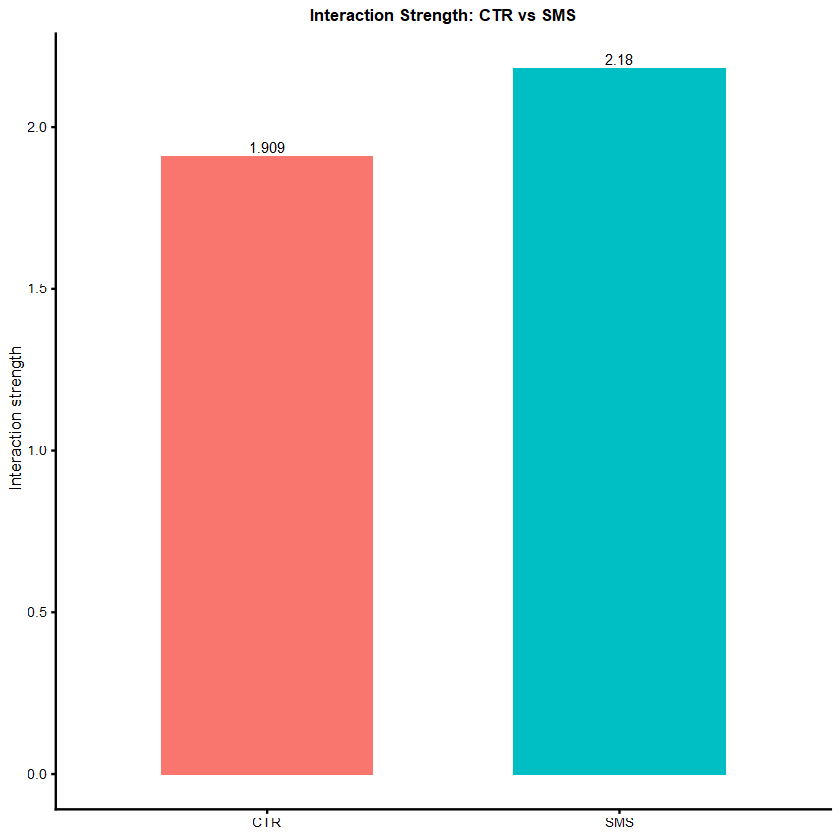

In [42]:
# ================= 5. Visualization: Overall Stats =================
print("Generating Overall Statistics...")

# 1. Compare total number of interactions
p_stats <- compareInteractions(cellchat_merged, show.legend = F, group = c(1,2)) + 
           ggtitle("Total Interactions: CTR vs SMS")
print(p_stats)
ggsave("Task4_Overall_Interactions_Count.png", plot = p_stats, width = 6, height = 6)

# 2. Compare interaction strength
p_strength <- compareInteractions(cellchat_merged, show.legend = F, group = c(1,2), measure = "weight") + 
              ggtitle("Interaction Strength: CTR vs SMS")
print(p_strength)
ggsave("Task4_Overall_Interactions_Strength.png", plot = p_strength, width = 6, height = 6)

[1] "Generating Circle Plots for Inhibitory & Oligo interactions..."
[1] "Plotting CTR Network..."


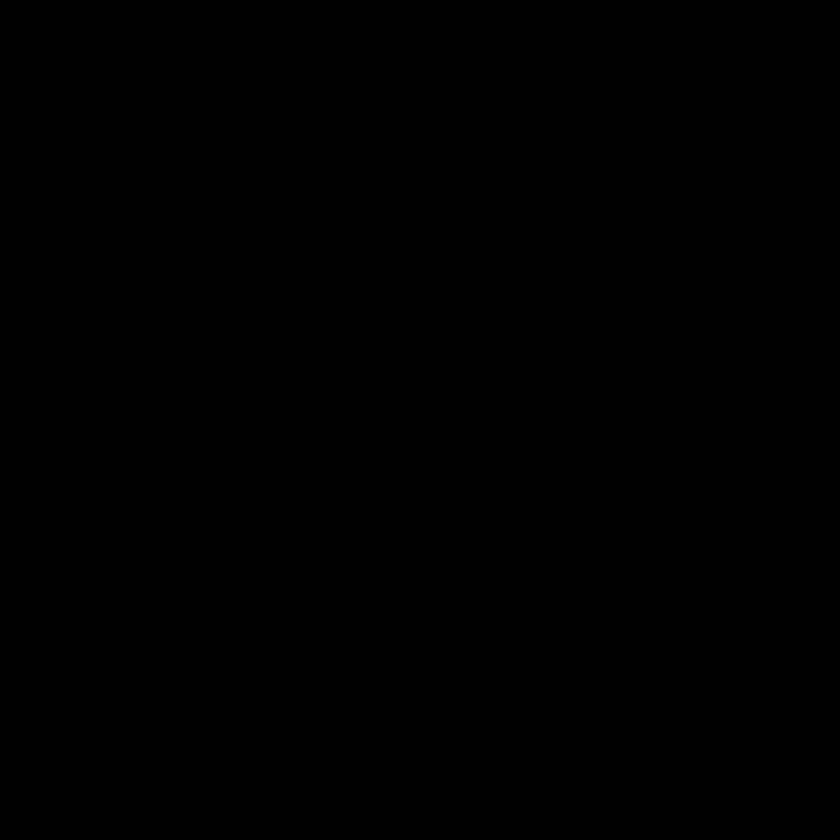

png 
  3

[1] "Saved Task4_CirclePlot_CTR.png"
[1] "Plotting SMS Network..."


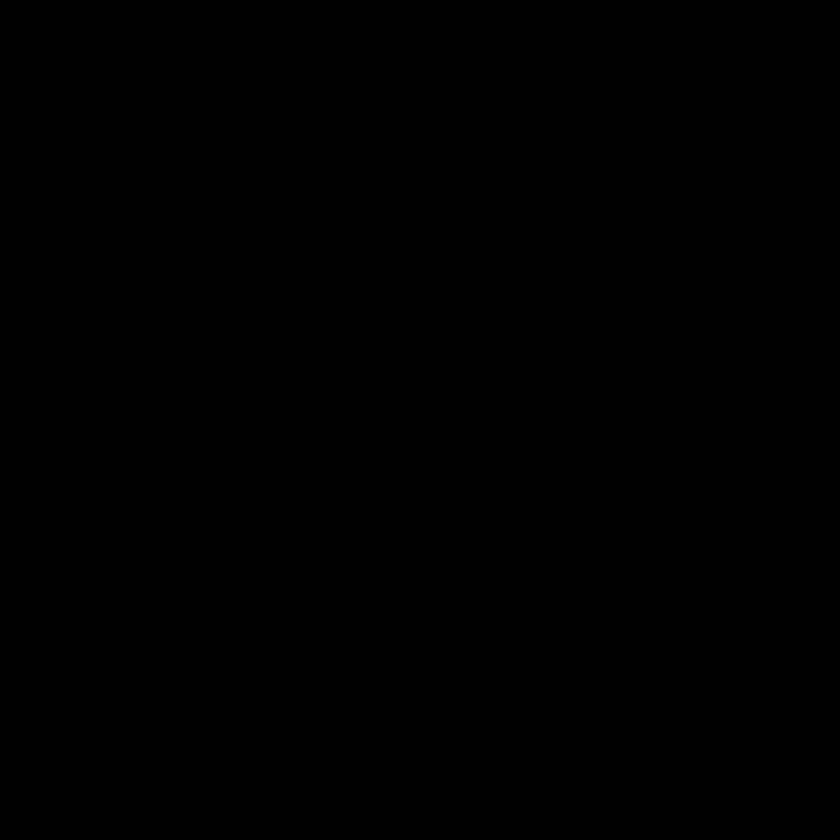

png 
  3

[1] "Saved Task4_CirclePlot_SMS.png"
[1] "Generating Bubble Plots..."
[1] "Plotting interactions between: Inhibitory, Excitatory, Oligo, NF Oligo, Astro"
[1] "Plotting CTR Bubble..."


Comparing communications on a single object 




[1] "Plotting SMS Bubble..."


Comparing communications on a single object 




[1] "Plotting comparison (Lost in SMS)..."


Comparing communications on a merged object 




[1] "Plotting comparison (Gained in SMS)..."


Comparing communications on a merged object 




[1] "Task 4 Visualization Fix Complete."


In [43]:
# ================= 6. Visualization: Circle Plots (FIXED) =================
print("Generating Circle Plots for Inhibitory & Oligo interactions...")

# *** FIX: Manually calculate group sizes for vertex weights ***
# This replaces the missing 'groupSize' function
groupSize_ctr <- as.numeric(table(cc_ctr@idents))
groupSize_sms <- as.numeric(table(cc_sms@idents))

# Define groups of interest
groups_to_show <- c("Inhibitory", "Excitatory", "Oligo", "NF Oligo", "Astro", "Microglia")
# Filter to existing groups in the object
groups_to_show <- groups_to_show[groups_to_show %in% levels(cc_ctr@idents)]

# --- Plot CTR Circle ---
print("Plotting CTR Network...")
png("Task4_CirclePlot_CTR.png", width = 2000, height = 2000, res = 300)
par(mfrow = c(1,1))
netVisual_circle(cc_ctr@net$count, 
                 vertex.weight = groupSize_ctr, 
                 weight.scale = TRUE, 
                 label.edge = FALSE, 
                 title.name = "CTR Network (CTX)")
dev.off()
print("Saved Task4_CirclePlot_CTR.png")

# --- Plot SMS Circle ---
print("Plotting SMS Network...")
png("Task4_CirclePlot_SMS.png", width = 2000, height = 2000, res = 300)
par(mfrow = c(1,1))
netVisual_circle(cc_sms@net$count, 
                 vertex.weight = groupSize_sms, 
                 weight.scale = TRUE, 
                 label.edge = FALSE, 
                 title.name = "SMS Network (CTX)")
dev.off()
print("Saved Task4_CirclePlot_SMS.png")

# ================= 7. Visualization: Bubble Plots (Detailed) =================
print("Generating Bubble Plots...")

# Define Sources and Targets
# Specifically targeting Inhibitory, Oligo, and Neurons as per instructions
sources_target <- c("Inhibitory", "Excitatory", "Oligo", "NF Oligo", "Astro")
# Ensure these types exist in your dataset
available_types <- levels(cc_ctr@idents)
sources_target <- sources_target[sources_target %in% available_types]

print(paste("Plotting interactions between:", paste(sources_target, collapse=", ")))

# --- Plot 1: CTR Only (Baseline Check) ---
print("Plotting CTR Bubble...")
# Note: remove.isolate=FALSE ensures we see rows even if interactions are sparse
p_bub_ctr <- netVisual_bubble(cc_ctr, 
                              sources.use = sources_target, 
                              targets.use = sources_target, 
                              remove.isolate = FALSE, 
                              angle.x = 45, 
                              title.name = "CTR Interactions (Baseline)")
print(p_bub_ctr)
ggsave("Task4_Bubble_CTR_Only.png", plot = p_bub_ctr, width = 12, height = 10)

# --- Plot 2: SMS Only ---
print("Plotting SMS Bubble...")
p_bub_sms <- netVisual_bubble(cc_sms, 
                              sources.use = sources_target, 
                              targets.use = sources_target, 
                              remove.isolate = FALSE, 
                              angle.x = 45, 
                              title.name = "SMS Interactions")
print(p_bub_sms)
ggsave("Task4_Bubble_SMS_Only.png", plot = p_bub_sms, width = 12, height = 10)

# --- Plot 3: Comparison (Decreased vs Increased) ---
# Ensure cellchat_merged exists (it should from previous steps)
if(!exists("cellchat_merged")) {
  object.list <- list(CTR = cc_ctr, SMS = cc_sms)
  cellchat_merged <- mergeCellChat(object.list, add.names = names(object.list))
}

# Lost in SMS (Enriched in CTR)
print("Plotting comparison (Lost in SMS)...")
# max.dataset = 1 means highlights interactions stronger in the 1st dataset (CTR)
tryCatch({
  p_loss <- netVisual_bubble(cellchat_merged, 
                             sources.use = sources_target, 
                             targets.use = sources_target, 
                             comparison = c(1, 2), 
                             max.dataset = 1, 
                             angle.x = 45, 
                             remove.isolate = FALSE,
                             title.name = "Interactions Enriched in CTR (Lost in SMS)")
  print(p_loss)
  ggsave("Task4_Bubble_Enriched_in_CTR.png", plot = p_loss, width = 14, height = 12)
}, error = function(e) { print(paste("Error plotting Loss Bubble:", e$message)) })

# Gained in SMS (Enriched in SMS)
print("Plotting comparison (Gained in SMS)...")
# max.dataset = 2 means highlights interactions stronger in the 2nd dataset (SMS)
tryCatch({
  p_gain <- netVisual_bubble(cellchat_merged, 
                             sources.use = sources_target, 
                             targets.use = sources_target, 
                             comparison = c(1, 2), 
                             max.dataset = 2, 
                             angle.x = 45, 
                             remove.isolate = FALSE,
                             title.name = "Interactions Enriched in SMS")
  print(p_gain)
  ggsave("Task4_Bubble_Enriched_in_SMS.png", plot = p_gain, width = 14, height = 12)
}, error = function(e) { print(paste("Error plotting Gain Bubble:", e$message)) })

print("Task 4 Visualization Fix Complete.")

# Task4 Addition 2026/01/20

In [44]:
# ================= Special Request: Subtype Circle Plot =================
library(CellChat)

print("Preparing data for Subtype Circle Plot (SST-PV-VIP-Excitatory)...")

# 1. Update Annotations in combined_data
# Create a new column starting with broad types
combined_data$fine_label <- as.character(combined_data$predicted_celltype)

# Map Task 3 subtypes (PV/SST/VIP) back to combined_data
# We find cells that exist in inhib_obj and update their label
cells_with_subtype <- colnames(inhib_obj)
# Ensure these cells are in combined_data
cells_common <- intersect(cells_with_subtype, colnames(combined_data))

if(length(cells_common) > 0) {
  # Transfer labels
  # Note: Need to align indices
  combined_data$fine_label[match(cells_common, colnames(combined_data))] <- as.character(inhib_obj$subtype[match(cells_common, colnames(inhib_obj))])
} else {
  stop("Error: No matching cells found between Task 3 and Task 2 objects. Did you run them in the same session?")
}

print("Updated Labels (Example):")
print(table(combined_data$fine_label))

# 2. Subset Data for Specific Interaction Analysis
# We only want: Excitatory, PV, SST, VIP
target_groups <- c("Excitatory", "PV", "SST", "VIP")
cells_to_plot <- colnames(combined_data)[combined_data$fine_label %in% target_groups]

# Create a mini Seurat object for just these cells to save computation time
mini_seurat <- subset(combined_data, cells = cells_to_plot)
# Update Idents to the fine labels
Idents(mini_seurat) <- mini_seurat$fine_label

# 3. Quick CellChat Run (CTR and SMS separated)
run_mini_cellchat <- function(seurat_obj, group_name) {
  data.input <- GetAssayData(seurat_obj, assay = "Spatial", layer = "data")
  meta <- seurat_obj@meta.data
  
  # Create Object
  cc <- createCellChat(object = data.input, meta = meta, group.by = "fine_label")
  cc@DB <- CellChatDB.mouse
  
  # Compute (Standard Flow)
  cc <- subsetData(cc)
  cc <- identifyOverExpressedGenes(cc)
  cc <- identifyOverExpressedInteractions(cc)
  cc <- computeCommunProb(cc, type = "triMean")
  cc <- filterCommunication(cc, min.cells = 10)
  cc <- computeCommunProbPathway(cc)
  cc <- aggregateNet(cc)
  return(cc)
}

print("Running CellChat for Subtypes (This may take a few minutes)...")
# Split by condition
mini_ctr <- subset(mini_seurat, idents = "CTR", invert = FALSE) # Split implicitly by meta
mini_sms <- subset(mini_seurat, idents = "SMS", invert = FALSE)

# Note: We need to ensure Idents correspond to condition for subsetting
# But for CellChat, we need Idents to be fine_label.
# Let's subset using metadata column
mini_ctr <- subset(mini_seurat, subset = condition == "CTR")
mini_sms <- subset(mini_seurat, subset = condition == "SMS")

cc_sub_ctr <- run_mini_cellchat(mini_ctr, "CTR")
cc_sub_sms <- run_mini_cellchat(mini_sms, "SMS")

# 4. Generate Circle Plots
print("Plotting Subtype Circle Plots...")

# Define color palette manually to ensure consistency
# Excitatory, PV, SST, VIP
group_colors <- c("Excitatory"="#F8766D", "PV"="#7CAE00", "SST"="#00BFC4", "VIP"="#C77CFF")
# Match names found in object
avail_groups <- levels(cc_sub_ctr@idents)
my_cols <- group_colors[avail_groups]

# Plot CTR
png("Special_Circle_Subtypes_CTR.png", width = 2000, height = 2000, res = 300)
par(mfrow = c(1,1))
netVisual_circle(cc_sub_ctr@net$count, 
                 vertex.weight = as.numeric(table(cc_sub_ctr@idents)), 
                 weight.scale = T, label.edge= F, 
                 color.use = my_cols,
                 title.name = "Connectivity: Excitatory & Inhib Subtypes (WT)")
dev.off()

# Plot SMS
png("Special_Circle_Subtypes_SMS.png", width = 2000, height = 2000, res = 300)
par(mfrow = c(1,1))
netVisual_circle(cc_sub_sms@net$count, 
                 vertex.weight = as.numeric(table(cc_sub_sms@idents)), 
                 weight.scale = T, label.edge= F, 
                 color.use = my_cols,
                 title.name = "Connectivity: Excitatory & Inhib Subtypes (SMS)")
dev.off()

print("Special request completed.")

[1] "Preparing data for Subtype Circle Plot (SST-PV-VIP-Excitatory)..."
[1] "Updated Labels (Example):"

     Astro       Endo Excitatory Inhibitory  Microglia   NF Oligo      Oligo 
      7408       3995      77524       5497        515        673       3553 
       OPC         PV        SST        VIP 
       655        908       5671       1579 
[1] "Running CellChat for Subtypes (This may take a few minutes)..."


ERROR: Error in WhichCells.Seurat(object = x, cells = cells, idents = idents, : Cannot find the following identities in the object: CTR


In [45]:
# ================= Robust Special Circle Plot Generation =================
library(CellChat)
library(ComplexHeatmap)

# 1. Force clear graphic devices (Critical step to prevent 0KB output files)
while (dev.cur() > 1) dev.off()
graphics.off()

print("Starting Robust Special Circle Plot Analysis...")

# Ensure data exists
if (!exists("mini_seurat")) {
  stop("Error: 'mini_seurat' object missing. Please run the data subsetting part first.")
}

# Define colors to ensure consistency across plots
target_groups <- c("Excitatory", "PV", "SST", "VIP")
group_colors <- scPalette(length(target_groups))
names(group_colors) <- target_groups

# Define a more robust CellChat wrapper function
# Added logic: Automatically lower thresholds if standard parameters yield 0 interactions
run_robust_cellchat <- function(seurat_obj, group_name) {
  print(paste(">>> Processing:", group_name))
  
  data.input <- GetAssayData(seurat_obj, assay = "Spatial", layer = "data")
  meta <- seurat_obj@meta.data
  
  cc <- createCellChat(object = data.input, meta = meta, group.by = "fine_label")
  cc@DB <- CellChatDB.mouse
  
  cc <- subsetData(cc)
  cc <- identifyOverExpressedGenes(cc)
  cc <- identifyOverExpressedInteractions(cc)
  
  # First attempt: Standard thresholds
  cc <- computeCommunProb(cc, type = "triMean")
  # Note: Setting min.cells = 3 to prevent empty results due to low cell counts
  cc <- filterCommunication(cc, min.cells = 3) 
  cc <- computeCommunProbPathway(cc)
  cc <- aggregateNet(cc)
  
  # Check the number of interactions
  count_sum <- sum(cc@net$count)
  print(paste("    Total Interactions found:", count_sum))
  
  if (count_sum == 0) {
    print("    Warning: No interactions found with standard thresholds. Trying looser thresholds...")
    # If 0, bypass filterCommunication for a looser threshold
    cc <- computeCommunProb(cc, type = "triMean")
    # Skip filtering and aggregate directly
    cc <- computeCommunProbPathway(cc)
    cc <- aggregateNet(cc)
    print(paste("    Retry Total Interactions:", sum(cc@net$count)))
  }
  
  return(cc)
}

# 2. Re-calculate (Ensure data is up to date)
print("Re-running CellChat for CTR...")
mini_ctr <- subset(mini_seurat, subset = condition == "CTR")
cc_sub_ctr <- run_robust_cellchat(mini_ctr, "CTR")

print("Re-running CellChat for SMS...")
mini_sms <- subset(mini_seurat, subset = condition == "SMS")
cc_sub_sms <- run_robust_cellchat(mini_sms, "SMS")

# 3. Plotting (Draw separately to ensure file streams close properly)

# --- Plot 1: CTR ---
# Check if there is data to plot
if (sum(cc_sub_ctr@net$count) > 0) {
  print("Generating CTR Circle Plot...")
  
  png("Task4_Special_Circle_CTR_Fixed.png", width = 2000, height = 2000, res = 300)
  par(mfrow = c(1,1), xpd=TRUE) # Force reset plotting parameters
  
  # Calculate vertex weights
  w_ctr <- as.numeric(table(cc_sub_ctr@idents))
  
  # Plot the network
  netVisual_circle(cc_sub_ctr@net$count, 
                   vertex.weight = w_ctr, 
                   weight.scale = TRUE, 
                   label.edge = FALSE, 
                   color.use = group_colors[levels(cc_sub_ctr@idents)],
                   title.name = "Connectivity: Excitatory & Inhib Subtypes (WT)")
  
  dev.off() # Close the CTR file device
  print("Success: Task4_Special_Circle_CTR_Fixed.png saved.")
} else {
  print("ERROR: CTR group still has 0 interactions. Cannot plot circle.")
}

# --- Plot 2: SMS ---
# Force clear to prevent device interference
while (dev.cur() > 1) dev.off()

if (sum(cc_sub_sms@net$count) > 0) {
  print("Generating SMS Circle Plot...")
  
  png("Task4_Special_Circle_SMS_Fixed.png", width = 2000, height = 2000, res = 300)
  par(mfrow = c(1,1), xpd=TRUE)
  
  w_sms <- as.numeric(table(cc_sub_sms@idents))
  
  netVisual_circle(cc_sub_sms@net$count, 
                   vertex.weight = w_sms, 
                   weight.scale = TRUE, 
                   label.edge = FALSE, 
                   color.use = group_colors[levels(cc_sub_sms@idents)],
                   title.name = "Connectivity: Excitatory & Inhib Subtypes (SMS)")
  
  dev.off() # Close the SMS file device
  print("Success: Task4_Special_Circle_SMS_Fixed.png saved.")
} else {
  print("ERROR: SMS group has 0 interactions.")
}

print("Fix completed.")

[1] "Starting Robust Special Circle Plot Analysis..."
[1] "Re-running CellChat for CTR..."
[1] ">>> Processing: CTR"
[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  Excitatory PV SST VIP 
Issue identified!! Please check the official Gene Symbol of the following genes:  
 H2-BI H2-Ea-ps 
triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2026-02-24 09:44:29.252859]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2026-02-24 09:51:07.327468]"
[1] "    Total Interactions found: 56"
[1] "Re-running CellChat for SMS..."
[1] ">>> Processing: SMS"
[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  Excitatory PV SST VIP 
Issue identified!! Please check the official Gene Symbol o

# Task 5

In [46]:
# ================= Task 5: Trajectory Analysis (Slingshot) =================
library(slingshot)
library(SingleCellExperiment)
library(ggplot2)
library(RColorBrewer)
library(scales)

print("Starting Task 5: Slingshot Trajectory Analysis for PV/SST/VIP...")

# 1. Prepare data
# Re-using the inhib_obj from Task 3 (contains PV, SST, VIP)
# Convert to SingleCellExperiment (SCE) object, which Slingshot requires
sce <- as.SingleCellExperiment(inhib_obj)

# 2. Run Slingshot
# clusterLabels: use our annotated subtypes
# reducedDim: use the pre-calculated UMAP embeddings
print("Calculating trajectories (this calculates a shared path for CTR & SMS)...")
sce <- slingshot(sce, clusterLabels = 'subtype', reducedDim = 'UMAP')

# 3. Extract plotting data
# Extract the pseudotime values computed by Slingshot
pt <- slingPseudotime(sce)
# Pull UMAP coordinates
umap_coords <- reducedDims(sce)$UMAP

# Build a master dataframe for ggplot2
df_plot <- data.frame(
  UMAP_1 = umap_coords[,1],
  UMAP_2 = umap_coords[,2],
  Pseudotime = pt[,1], # Grab the primary trajectory (Lineage 1)
  Condition = inhib_obj$condition,
  Subtype = inhib_obj$subtype
)

# 4. Extract curve coordinates (for drawing the black trajectory lines)
# Slingshot fits principal curves, which need to be extracted manually for custom plotting
curves <- slingCurves(sce)
curve_coords <- data.frame()

for(i in 1:length(curves)){
  # Grab coordinates for the current curve
  c_coords <- curves[[i]]$s[curves[[i]]$ord, ]
  c_df <- data.frame(
    UMAP_1 = c_coords[,1],
    UMAP_2 = c_coords[,2],
    Lineage = paste0("Lineage", i)
  )
  curve_coords <- rbind(curve_coords, c_df)
}

Loading required package: princurve

Loading required package: TrajectoryUtils

Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: 'matrixStats'


The following objects are masked from 'package:Biobase':

    anyMissing, rowMedians


The following object is masked from 'package:dplyr':

    count



Attaching package: 'MatrixGenerics'


The following objects are masked from 'package:matrixStats':

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds

[1] "Starting Task 5: Slingshot Trajectory Analysis for PV/SST/VIP..."
[1] "Calculating trajectories (this calculates a shared path for CTR & SMS)..."


[1] "Generating Plot 1: Trajectory UMAP..."


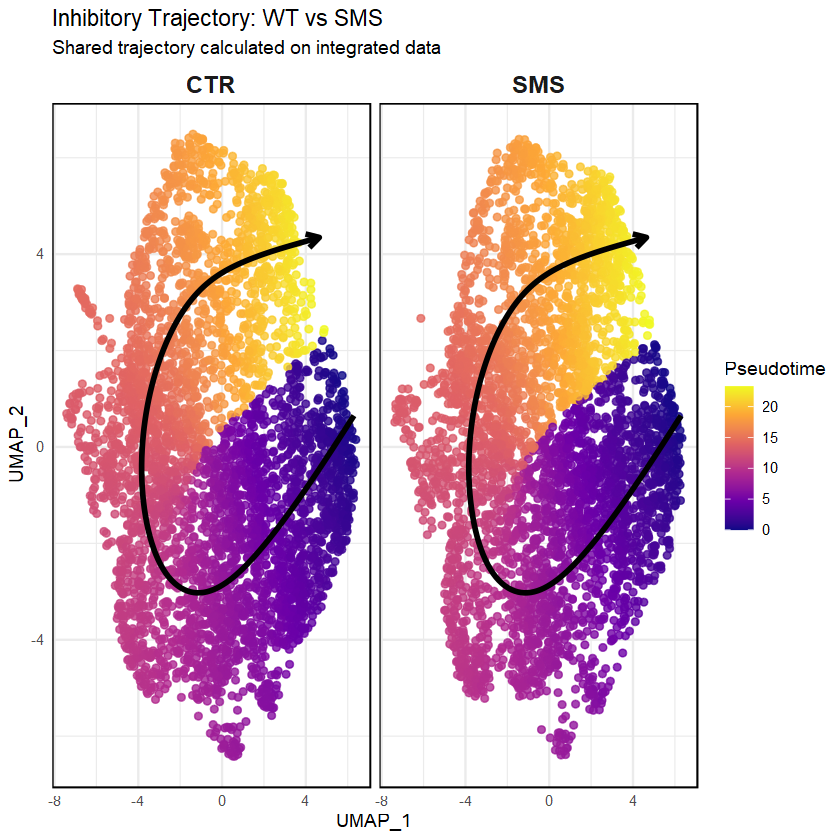

In [47]:
# ================= Plot 1: Trajectory UMAP (Side-by-Side) =================
print("Generating Plot 1: Trajectory UMAP...")

# Define colors (maintaining consistency)
# Can map either Pseudotime gradient or Subtype colors
# Here we use Pseudotime to visualize the state/developmental progression
p_traj <- ggplot() +
  # Plot the individual cells
  geom_point(data = df_plot, aes(x = UMAP_1, y = UMAP_2, color = Pseudotime), 
             size = 1.5, alpha = 0.8) +
  scale_color_viridis_c(option = "plasma", na.value = "grey90", name = "Pseudotime") +
  
  # Draw the principal curve paths (black lines)
  geom_path(data = curve_coords, aes(x = UMAP_1, y = UMAP_2, group = Lineage), 
            color = "black", size = 1.2, arrow = arrow(length = unit(0.3, "cm"))) +
  
  # Split view for CTR vs SMS
  facet_wrap(~Condition) +
  
  theme_minimal() +
  labs(title = "Inhibitory Trajectory: WT vs SMS",
       subtitle = "Shared trajectory calculated on integrated data") +
  theme(
    strip.text = element_text(size = 14, face = "bold"),
    legend.position = "right",
    panel.border = element_rect(color = "black", fill = NA)
  )

print(p_traj)
ggsave("Task5_Trajectory_UMAP_Split.png", plot = p_traj, width = 12, height = 6)

[1] "Generating Plot 2: Subtype Trajectory..."


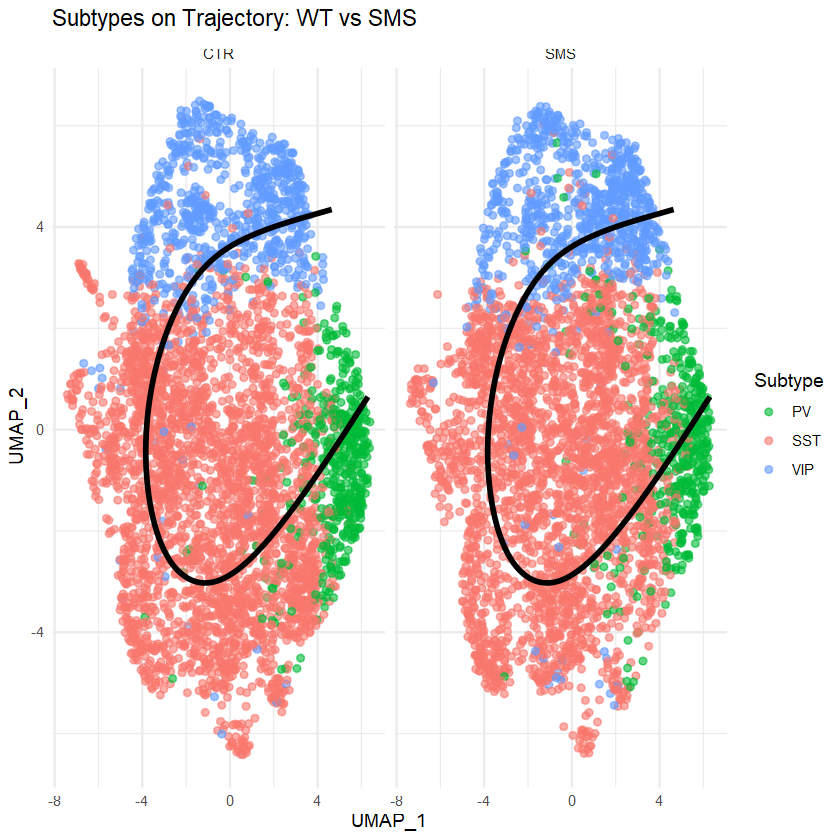

In [48]:
# ================= Plot 2: Subtype Distribution on Trajectory =================
# The trajectory is drawn, but where do the actual PV/SST/VIP cells land?
# Let's generate another version colored by Subtype instead of pseudotime.
print("Generating Plot 2: Subtype Trajectory...")

p_traj_sub <- ggplot() +
  geom_point(data = df_plot, aes(x = UMAP_1, y = UMAP_2, color = Subtype), 
             size = 1.5, alpha = 0.6) +
  # Re-use the original RGB color palette
  scale_color_manual(values = c("SST"="#F8766D", "PV"="#00BA38", "VIP"="#619CFF")) +
  
  geom_path(data = curve_coords, aes(x = UMAP_1, y = UMAP_2, group = Lineage), 
            color = "black", size = 1.2) +
  
  facet_wrap(~Condition) +
  theme_minimal() +
  labs(title = "Subtypes on Trajectory: WT vs SMS")

print(p_traj_sub)
ggsave("Task5_Trajectory_Subtypes_Split.png", plot = p_traj_sub, width = 12, height = 6)

[1] "Generating Plot 3: Pseudotime Density..."
[1] "Task 5 Trajectory Analysis Completed."


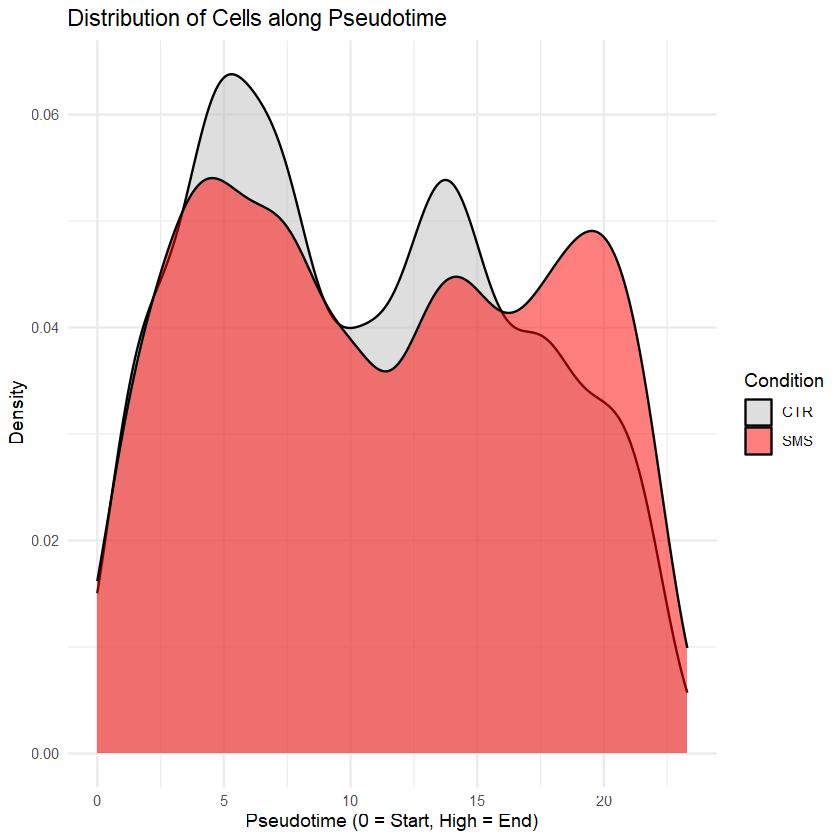

In [49]:
# ================= Plot 3: Pseudotime Density (Quantitative Comparison) =================
print("Generating Plot 3: Pseudotime Density...")

# This plot is crucial: it quantifies whether there's a developmental shift between CTR and SMS.
# If the SMS density peak is shifted to the right compared to CTR, it indicates SMS cells are in a "later" or more advanced state.
p_density <- ggplot(df_plot, aes(x = Pseudotime, fill = Condition)) +
  geom_density(alpha = 0.5) +
  scale_fill_manual(values = c("CTR" = "grey", "SMS" = "red")) +
  theme_minimal() +
  labs(title = "Distribution of Cells along Pseudotime",
       x = "Pseudotime (0 = Start, High = End)",
       y = "Density")

print(p_density)
ggsave("Task5_Pseudotime_Density_Comparison.png", plot = p_density, width = 8, height = 5)

print("Task 5 Trajectory Analysis Completed.")

In [ ]:
# 2026/02/14 
# I've attached the trajectory curve that you made for excitatory cells. This plot is for the CTR sample I'm guessing. Can you make one for SMS as well so we can compare the two

In [ ]:
# ================= Task 5 Extension: Excitatory Trajectory Analysis =================
library(slingshot)
library(SingleCellExperiment)
library(ggplot2)
library(RColorBrewer)
library(Seurat)
library(viridis)

print("Starting Trajectory Analysis for Excitatory Neurons...")

# 1. Prepare data: Subset Excitatory cells and re-embed
# We must re-run UMAP because Excitatory cells form a single dense blob in the global UMAP, hiding the trajectory direction.
if (!exists("combined_data")) stop("combined_data missing!")

print("Subsetting Excitatory cells and re-embedding...")
excit_obj <- subset(combined_data, idents = "Excitatory")

DefaultAssay(excit_obj) <- "Spatial"
excit_obj <- FindVariableFeatures(excit_obj, selection.method = "vst", nfeatures = 2000)
excit_obj <- ScaleData(excit_obj)
excit_obj <- RunPCA(excit_obj, verbose = FALSE)
excit_obj <- RunUMAP(excit_obj, dims = 1:30)

# 2. Sub-clustering
# Slingshot needs "waypoints" to draw its curves, so we need to subdivide Excitatory cells into distinct states.
excit_obj <- FindNeighbors(excit_obj, dims = 1:30)
excit_obj <- FindClusters(excit_obj, resolution = 0.3) # Low resolution to isolate 3-4 main states

print("Excitatory Sub-clusters found:")
print(table(excit_obj$seurat_clusters))

# 3. Run Slingshot
print("Calculating trajectory curves...")
sce <- as.SingleCellExperiment(excit_obj)
# Use seurat_clusters as waypoints
sce <- slingshot(sce, clusterLabels = 'seurat_clusters', reducedDim = 'UMAP')

# 4. Extract plotting data
pt <- slingPseudotime(sce)
umap_coords <- reducedDims(sce)$UMAP

# Merge into a master dataframe
df_plot <- data.frame(
  UMAP_1 = umap_coords[,1],
  UMAP_2 = umap_coords[,2],
  Pseudotime = pt[,1], # Grab the primary trajectory (Lineage 1)
  Condition = excit_obj$condition,
  Cluster = excit_obj$seurat_clusters # Current sub-cluster state
)

# Extract principal curve coordinates (the black trajectory lines)
curves <- slingCurves(sce)
curve_coords <- data.frame()
for(i in 1:length(curves)){
  c_coords <- curves[[i]]$s[curves[[i]]$ord, ]
  c_df <- data.frame(
    UMAP_1 = c_coords[,1],
    UMAP_2 = c_coords[,2],
    Lineage = paste0("Lineage", i)
  )
  curve_coords <- rbind(curve_coords, c_df)
}

# ================= Plot 1: Side-by-Side Trajectory (CTR vs SMS) =================
print("Generating Excitatory Trajectory Plot (Split View)...")

p_traj <- ggplot() +
  # 1. Plot cells (colored by Pseudotime progression)
  geom_point(data = df_plot, aes(x = UMAP_1, y = UMAP_2, color = Pseudotime), 
             size = 1.2, alpha = 0.8) +
  scale_color_viridis_c(option = "magma", na.value = "grey90", name = "Pseudotime\n(Development)") +
  
  # 2. Draw trajectory path (black arrows)
  geom_path(data = curve_coords, aes(x = UMAP_1, y = UMAP_2, group = Lineage), 
            color = "black", size = 1.5, arrow = arrow(length = unit(0.4, "cm"))) +
  
  # 3. Split view (Critical step: facet by condition for side-by-side comparison)
  facet_wrap(~Condition) +
  
  theme_minimal() +
  labs(title = "Trajectory of Excitatory Neurons: WT vs SMS",
       subtitle = "Color indicates progression (Dark = Early, Light = Late)") +
  theme(
    strip.text = element_text(size = 16, face = "bold"), # Enlarge facet headers
    legend.position = "right",
    panel.border = element_rect(color = "black", fill = NA),
    axis.title = element_text(size = 12)
  )

print(p_traj)
ggsave("Task5_Excitatory_Trajectory_Split.png", plot = p_traj, width = 14, height = 7)



# ================= Plot 2: Density Comparison =================
print("Generating Density Plot...")
# This plot provides an intuitive look at whether SMS is "delayed" or "advanced" compared to WT
p_density <- ggplot(df_plot, aes(x = Pseudotime, fill = Condition)) +
  geom_density(alpha = 0.5) +
  scale_fill_manual(values = c("CTR" = "grey", "SMS" = "red")) +
  theme_minimal() +
  labs(title = "Excitatory Neurons: Pseudotime Distribution",
       subtitle = "Comparison of cell density along the trajectory",
       x = "Pseudotime (0 = Start State, High = End State)",
       y = "Density")

print(p_density)
ggsave("Task5_Excitatory_Pseudotime_Density.png", plot = p_density, width = 8, height = 5)

print("Excitatory Trajectory Analysis Completed.")